In [ ]:
!pip install -q numpy pandas scipy matplotlib scikit-learn mne moabb

In [ ]:
import numpy as np
import pandas as pd
import scipy
import sklearn
import mne
import moabb

print("PROJECT VOICE")
print("Environment initialized successfully!")

print("NumPy:", np.__version__)
print("MNE:", mne.__version__)
print("MOABB:", moabb.__version__)

PROJECT VOICE
Environment initialized successfully!
NumPy: 2.4.6
MNE: 1.13.2
MOABB: 1.7.2


In [ ]:

# ============================================================
# PROJECT VOICE
# P300-Based Communication Research System
# Module 1: Core Architecture and Signal Processing Framework
# ============================================================

!pip install -q numpy pandas scipy matplotlib scikit-learn mne moabb seaborn

# -------------------- IMPORTS -------------------------------

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

warnings.filterwarnings("ignore")

# -------------------- PROJECT CONFIGURATION -----------------

PROJECT_NAME = "PROJECT VOICE"

CONFIG = {
    "sampling_rate": 256,
    "low_cutoff": 0.5,
    "high_cutoff": 20.0,
    "notch_frequency": 50,
    "epoch_start": -0.2,
    "epoch_end": 0.8,
    "random_state": 42,
    "target_event": 1,
    "non_target_event": 0
}

# -------------------- DIRECTORY STRUCTURE -------------------

DIRECTORIES = [
    "data/raw",
    "data/processed",
    "results/figures",
    "results/metrics",
    "models",
    "logs"
]

for directory in DIRECTORIES:
    os.makedirs(directory, exist_ok=True)

# -------------------- EXPERIMENT LOGGING --------------------

EXPERIMENT_LOG = {
    "project": PROJECT_NAME,
    "initialization_time": datetime.now().isoformat(),
    "configuration": CONFIG,
    "status": "INITIALIZED"
}

with open("logs/experiment_log.json", "w") as file:
    json.dump(EXPERIMENT_LOG, file, indent=4)

# -------------------- EEG FILTERING -------------------------

def bandpass_filter(signal, sampling_rate=256,
                    low=0.5, high=20.0, order=4):

    """
    Apply a Butterworth bandpass filter to EEG data.

    Expected input:
    channels x timepoints
    """

    sos = butter(
        order,
        [low, high],
        btype="bandpass",
        fs=sampling_rate,
        output="sos"
    )

    filtered = sosfiltfilt(sos, signal, axis=-1)

    return filtered


def notch_filter(signal, sampling_rate=256,
                 frequency=50):

    """
    Reduce power-line interference.
    """

    b, a = iirnotch(
        frequency,
        Q=30,
        fs=sampling_rate
    )

    filtered = filtfilt(b, a, signal, axis=-1)

    return filtered


def preprocess_eeg(signal, sampling_rate=256):

    """
    Complete preprocessing pipeline.
    """

    signal = np.asarray(signal, dtype=float)

    signal = notch_filter(
        signal,
        sampling_rate
    )

    signal = bandpass_filter(
        signal,
        sampling_rate
    )

    return signal


# -------------------- EPOCH EXTRACTION ----------------------

def extract_epochs(
    signal,
    event_samples,
    sampling_rate=256,
    start=-0.2,
    end=0.8
):

    """
    Extract time-locked EEG epochs.

    signal:
        channels x timepoints

    event_samples:
        Event onset sample indices
    """

    start_offset = int(start * sampling_rate)
    end_offset = int(end * sampling_rate)

    epochs = []

    for event in event_samples:

        start_index = event + start_offset
        end_index = event + end_offset

        if start_index < 0:
            continue

        if end_index > signal.shape[-1]:
            continue

        epoch = signal[:, start_index:end_index]

        epochs.append(epoch)

    return np.asarray(epochs)


# -------------------- FEATURE EXTRACTION -------------------

def extract_features(epochs):

    """
    Convert EEG epochs into feature vectors.

    Features:
    - Mean amplitude
    - Standard deviation
    - Maximum amplitude
    - Minimum amplitude
    - Signal energy
    """

    features = []

    for epoch in epochs:

        mean = np.mean(epoch, axis=-1)
        std = np.std(epoch, axis=-1)
        maximum = np.max(epoch, axis=-1)
        minimum = np.min(epoch, axis=-1)
        energy = np.mean(epoch ** 2, axis=-1)

        feature_vector = np.concatenate([
            mean,
            std,
            maximum,
            minimum,
            energy
        ])

        features.append(feature_vector)

    return np.asarray(features)


# -------------------- CLASSIFIER ---------------------------

def train_p300_classifier(X_train, y_train):

    """
    Train a baseline P300 classifier.
    """

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(X_train)

    classifier = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    classifier.fit(X_scaled, y_train)

    return scaler, classifier


def evaluate_classifier(
    scaler,
    classifier,
    X_test,
    y_test
):

    """
    Evaluate model performance.
    """

    X_scaled = scaler.transform(X_test)

    predictions = classifier.predict(X_scaled)

    probabilities = classifier.predict_proba(X_scaled)[:, 1]

    metrics = {
        "accuracy": accuracy_score(
            y_test, predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        ),

        "roc_auc": roc_auc_score(
            y_test, probabilities
        )
    }

    print("\nCLASSIFICATION REPORT")
    print(classification_report(y_test, predictions))

    print("\nPERFORMANCE METRICS")

    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    return metrics, predictions


# -------------------- VISUALIZATION ------------------------

def plot_confusion_matrix(y_true, predictions):

    matrix = confusion_matrix(
        y_true,
        predictions
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title("Project VOICE: Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()


# -------------------- INITIALIZATION TEST ------------------

print("=" * 60)
print("PROJECT VOICE")
print("P300 COMMUNICATION RESEARCH SYSTEM")
print("=" * 60)

print("\nDirectory structure created.")
print("Signal-processing functions loaded.")
print("Feature extraction pipeline loaded.")
print("Classifier framework loaded.")
print("Evaluation framework loaded.")

print("\nSYSTEM STATUS: READY FOR DATASET INTEGRATION")


PROJECT VOICE
P300 COMMUNICATION RESEARCH SYSTEM

Directory structure created.
Signal-processing functions loaded.
Feature extraction pipeline loaded.
Classifier framework loaded.
Evaluation framework loaded.

SYSTEM STATUS: READY FOR DATASET INTEGRATION


PROJECT VOICE | MODULE 2
REAL EEG DATASET INTEGRATION

[1] Initializing dataset...
Dataset: BNCI2014_008
Available subjects: [1, 2, 3, 4, 5, 6, 7, 8]

[2] Configuring P300 paradigm...
Paradigm initialized.
Sampling rate: 256.0 Hz

[3] Loading EEG recordings...
This may take a while on the first run.

DATA LOADED SUCCESSFULLY
EEG shape: (33600, 8, 257)
Labels shape: (33600,)
Metadata shape: (33600, 3)
Unique labels: ['NonTarget' 'Target']

[4] DATASET STRUCTURE
EEG dimensions: (33600, 8, 257)
Number of epochs: 33600
Number of channels: 8
Samples per epoch: 257
Unique labels: ['NonTarget' 'Target']

Metadata columns:
['subject', 'session', 'run']

[5] Encoding target classes...
Target = 1
NonTarget = 0

CLASS DISTRIBUTION
NonTarget: 28000 epochs (83.33%)
Target: 5600 epochs (16.67%)

[6] Validating EEG data...
Shape validation: PASS
Label validation: PASS
Metadata validation: PASS
Numerical validation: PASS

[7] Creating stratified partitions...
Training epochs: 25200
Testing epochs: 840

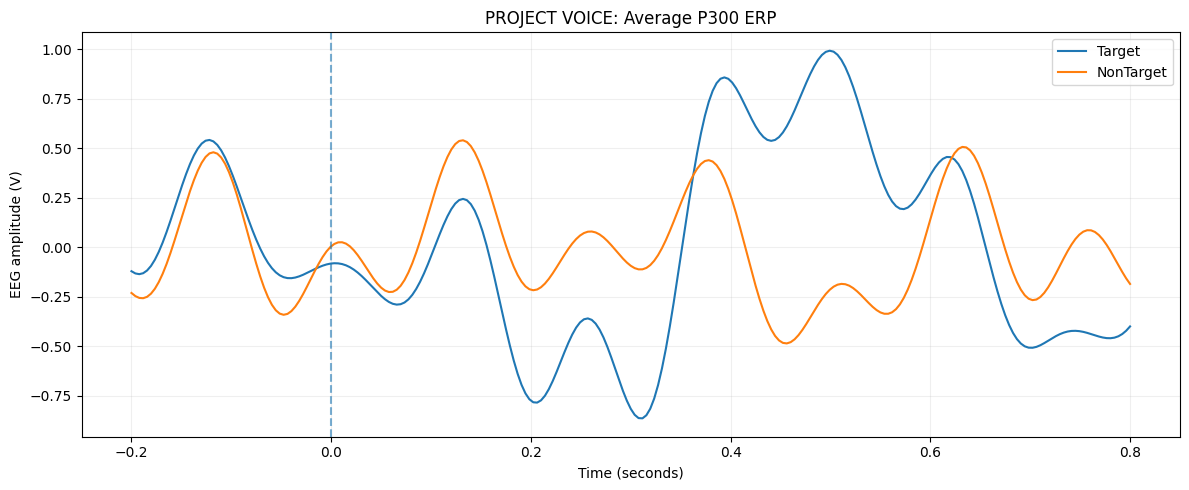

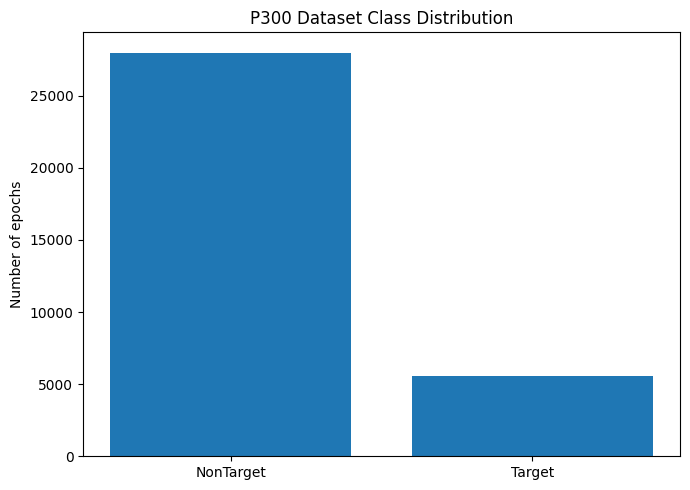


[9] Saving processed dataset...
EEG dataset saved.
Metadata saved.

[10] Preserving global project variables...
X: (33600, 8, 257)
y: (33600,)
metadata: (33600, 3)
dataset: BNCI2014_008
subject_indices: 8 subjects

PROJECT VOICE | MODULE 2 COMPLETE

Final dataset shape: (33600, 8, 257)
Training shape: (25200, 8, 257)
Testing shape: (8400, 8, 257)

Saved files:
- data/processed/voice_p300_dataset.npz
- data/processed/voice_metadata.csv
- results/figures/average_erp.png
- results/figures/class_distribution.png
- logs/module_2_report.json

GLOBAL VARIABLES READY:
- X
- y
- y_encoded
- metadata
- dataset
- paradigm
- subject_indices

STATUS: READY FOR CLASSIFICATION


In [ ]:
# ============================================================
# PROJECT VOICE
# MODULE 2: REAL EEG DATASET INTEGRATION
#
# Dataset: BNCI2014_008
# Paradigm: P300 / Event-Related Potential
# Classes: Target vs NonTarget
#
# Objective:
# Load, inspect, organize, validate, visualize and save
# real EEG epochs for downstream VOICE modules.
# ============================================================

# -------------------- 1. IMPORTS ----------------------------

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from datetime import datetime

from moabb.datasets import BNCI2014_008
from moabb.paradigms import P300

from sklearn.model_selection import train_test_split

# -------------------- 2. CONFIGURATION -----------------------

DATASET_NAME = "BNCI2014_008"

SUBJECTS = [1, 2, 3, 4, 5, 6, 7, 8]

RANDOM_STATE = 42
TEST_SIZE = 0.25

# BNCI2014_008 data is sampled at 256 Hz.
SAMPLING_RATE = 256.0

EPOCH_START = -0.2

OUTPUT_DIR = "data/processed"
FIGURE_DIR = "results/figures"
LOG_DIR = "logs"

for folder in [OUTPUT_DIR, FIGURE_DIR, LOG_DIR]:
    os.makedirs(folder, exist_ok=True)

print("=" * 70)
print("PROJECT VOICE | MODULE 2")
print("REAL EEG DATASET INTEGRATION")
print("=" * 70)

# -------------------- 3. LOAD DATASET ------------------------

print("\n[1] Initializing dataset...")

dataset = BNCI2014_008()

print("Dataset:", DATASET_NAME)
print("Available subjects:", dataset.subject_list)

# -------------------- 4. DEFINE P300 PARADIGM ----------------

print("\n[2] Configuring P300 paradigm...")

paradigm = P300(
    fmin=0.5,
    fmax=10.0,
    tmin=EPOCH_START,
    tmax=0.8
)

print("Paradigm initialized.")
print("Sampling rate:", SAMPLING_RATE, "Hz")

# -------------------- 5. LOAD EEG DATA -----------------------

print("\n[3] Loading EEG recordings...")
print("This may take a while on the first run.")

X, y_raw, metadata = paradigm.get_data(
    dataset=dataset,
    subjects=SUBJECTS
)

X = np.asarray(X)
y_raw = np.asarray(y_raw)
metadata = metadata.reset_index(drop=True)

print("\nDATA LOADED SUCCESSFULLY")

print("EEG shape:", X.shape)
print("Labels shape:", y_raw.shape)
print("Metadata shape:", metadata.shape)
print("Unique labels:", np.unique(y_raw))

# -------------------- 6. INSPECT DATA ------------------------

print("\n[4] DATASET STRUCTURE")

print("EEG dimensions:", X.shape)
print("Number of epochs:", X.shape[0])
print("Number of channels:", X.shape[1])
print("Samples per epoch:", X.shape[2])

print("Unique labels:", np.unique(y_raw))

print("\nMetadata columns:")
print(metadata.columns.tolist())

# -------------------- 7. LABEL ENCODING ----------------------

print("\n[5] Encoding target classes...")

normalized_labels = np.array([
    str(label).strip().lower()
    for label in y_raw
])

label_mapping = {
    "target": 1,
    "nontarget": 0,
    "non-target": 0
}

unknown_labels = set(normalized_labels) - set(label_mapping)

if unknown_labels:
    raise ValueError(
        f"Unexpected labels detected: {unknown_labels}"
    )

y = np.array([
    label_mapping[label]
    for label in normalized_labels
], dtype=np.int64)

y_encoded = y.copy()

print("Target = 1")
print("NonTarget = 0")

# -------------------- 8. CLASS DISTRIBUTION ------------------

class_counts = Counter(y)

print("\nCLASS DISTRIBUTION")

for label, count in sorted(class_counts.items()):

    class_name = "Target" if label == 1 else "NonTarget"

    percentage = 100 * count / len(y)

    print(
        f"{class_name}: {count} epochs "
        f"({percentage:.2f}%)"
    )

# -------------------- 9. DATA VALIDATION ---------------------

print("\n[6] Validating EEG data...")

assert X.ndim == 3, \
    "EEG array must have 3 dimensions."

assert len(X) == len(y), \
    "Mismatch between epochs and labels."

assert len(X) == len(metadata), \
    "Mismatch between EEG data and metadata."

assert np.isfinite(X).all(), \
    "EEG data contains NaN or infinite values."

assert set(np.unique(y)) == {0, 1}, \
    "Both target classes must be present."

assert X.shape[1] == 8, \
    "Unexpected EEG channel count."

assert X.shape[2] == 257, \
    "Unexpected samples per epoch."

print("Shape validation: PASS")
print("Label validation: PASS")
print("Metadata validation: PASS")
print("Numerical validation: PASS")

# -------------------- 10. TRAIN / TEST PARTITION -------------

print("\n[7] Creating stratified partitions...")

indices = np.arange(len(y))

train_indices, test_indices = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training epochs:", len(X_train))
print("Testing epochs:", len(X_test))

print("Training class distribution:", Counter(y_train))
print("Testing class distribution:", Counter(y_test))

# -------------------- 11. ERP VISUALIZATION ------------------

print("\n[8] Generating ERP visualizations...")

target_epochs = X[y == 1]
nontarget_epochs = X[y == 0]

# Descriptive overview averaged over epochs and channels.
target_erp = target_epochs.mean(axis=(0, 1))
nontarget_erp = nontarget_epochs.mean(axis=(0, 1))

time_axis = (
    np.arange(X.shape[-1]) / SAMPLING_RATE
    + EPOCH_START
)

plt.figure(figsize=(12, 5))

plt.plot(
    time_axis,
    target_erp,
    label="Target"
)

plt.plot(
    time_axis,
    nontarget_erp,
    label="NonTarget"
)

plt.axvline(0, linestyle="--", alpha=0.6)

plt.xlabel("Time (seconds)")
plt.ylabel("EEG amplitude (V)")
plt.title("PROJECT VOICE: Average P300 ERP")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "average_erp.png"),
    dpi=200
)

plt.show()
plt.close()

# -------------------- 12. CLASS DISTRIBUTION PLOT ------------

plt.figure(figsize=(7, 5))

plt.bar(
    ["NonTarget", "Target"],
    [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
)

plt.title("P300 Dataset Class Distribution")
plt.ylabel("Number of epochs")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "class_distribution.png"),
    dpi=200
)

plt.show()
plt.close()

# -------------------- 13. SAVE PROCESSED DATA ----------------

print("\n[9] Saving processed dataset...")

dataset_path = os.path.join(
    OUTPUT_DIR,
    "voice_p300_dataset.npz"
)

np.savez_compressed(
    dataset_path,

    X=X,
    y=y,

    X_train=X_train,
    X_test=X_test,

    y_train=y_train,
    y_test=y_test,

    train_indices=train_indices,
    test_indices=test_indices,

    sampling_rate=SAMPLING_RATE,
    epoch_start=EPOCH_START
)

metadata.to_csv(
    os.path.join(OUTPUT_DIR, "voice_metadata.csv"),
    index=False
)

print("EEG dataset saved.")
print("Metadata saved.")

# -------------------- 14. EXPERIMENT REPORT ------------------

report = {

    "project": "PROJECT VOICE",

    "module": 2,

    "dataset": DATASET_NAME,

    "subjects": SUBJECTS,

    "total_epochs": int(len(X)),

    "channels": int(X.shape[1]),

    "samples_per_epoch": int(X.shape[2]),

    "sampling_rate_hz": SAMPLING_RATE,

    "epoch_start_seconds": EPOCH_START,

    "target_epochs": int(class_counts.get(1, 0)),

    "nontarget_epochs": int(class_counts.get(0, 0)),

    "training_epochs": int(len(X_train)),

    "testing_epochs": int(len(X_test)),

    "metadata_columns": metadata.columns.tolist(),

    "timestamp": datetime.now().isoformat(),

    "status": "DATASET_LOADED_AND_VALIDATED"

}

report_path = os.path.join(
    LOG_DIR,
    "module_2_report.json"
)

with open(report_path, "w") as file:
    json.dump(report, file, indent=4)

# -------------------- 15. GLOBAL VARIABLE PRESERVATION -------

print("\n[10] Preserving global project variables...")

# These names are used by downstream modules.
X = np.asarray(X)
y = np.asarray(y, dtype=np.int64)
metadata = metadata.reset_index(drop=True)

y_encoded = y.copy()

# Subject-level indices, without inventing trial or flash labels.
subject_indices = {
    subject: np.flatnonzero(
        metadata["subject"].to_numpy() == subject
    )
    for subject in SUBJECTS
}

print("X:", X.shape)
print("y:", y.shape)
print("metadata:", metadata.shape)
print("dataset:", type(dataset).__name__)
print("subject_indices:", len(subject_indices), "subjects")

# -------------------- 16. FINAL STATUS -----------------------

print("\n" + "=" * 70)

print("PROJECT VOICE | MODULE 2 COMPLETE")

print("=" * 70)

print("\nFinal dataset shape:", X.shape)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nSaved files:")
print("- data/processed/voice_p300_dataset.npz")
print("- data/processed/voice_metadata.csv")
print("- results/figures/average_erp.png")
print("- results/figures/class_distribution.png")
print("- logs/module_2_report.json")

print("\nGLOBAL VARIABLES READY:")
print("- X")
print("- y")
print("- y_encoded")
print("- metadata")
print("- dataset")
print("- paradigm")
print("- subject_indices")

print("\nSTATUS: READY FOR CLASSIFICATION")

print("=" * 70)

In [ ]:
print("EEG shape:", X.shape)
print("Unique labels:", np.unique(y))
print("Metadata columns:", metadata.columns.tolist())

EEG shape: (33600, 8, 257)
Unique labels: [0 1]
Metadata columns: ['subject', 'session', 'run']


PROJECT VOICE | MODULE 3
P300 CLASSIFICATION ENGINE

[1] Validating input data...
EEG shape: (33600, 8, 257)
Labels: [0 1]
Metadata: (33600, 3)

[2] Validating classification labels...
Label encoding: PASS
NonTarget = 0
Target = 1
Class distribution: Counter({np.int64(0): 28000, np.int64(1): 5600})

[3] Extracting temporal EEG features...
Original dimensions: (33600, 8, 257)
Feature dimensions: (33600, 520)
Feature extraction complete.

[4] Initializing classifiers...
Regularized LDA initialized.
Dummy baseline initialized.

[5] EXPERIMENT A: WITHIN-DATASET CLASSIFICATION
Training samples: 25200
Testing samples: 8400
Training distribution: Counter({np.int64(0): 21000, np.int64(1): 4200})
Testing distribution: Counter({np.int64(0): 7000, np.int64(1): 1400})

Training regularized LDA...
LDA training complete.

Training Dummy Classifier...
Dummy training complete.

------------------------------------------------------------
Regularized LDA
------------------------------------------------

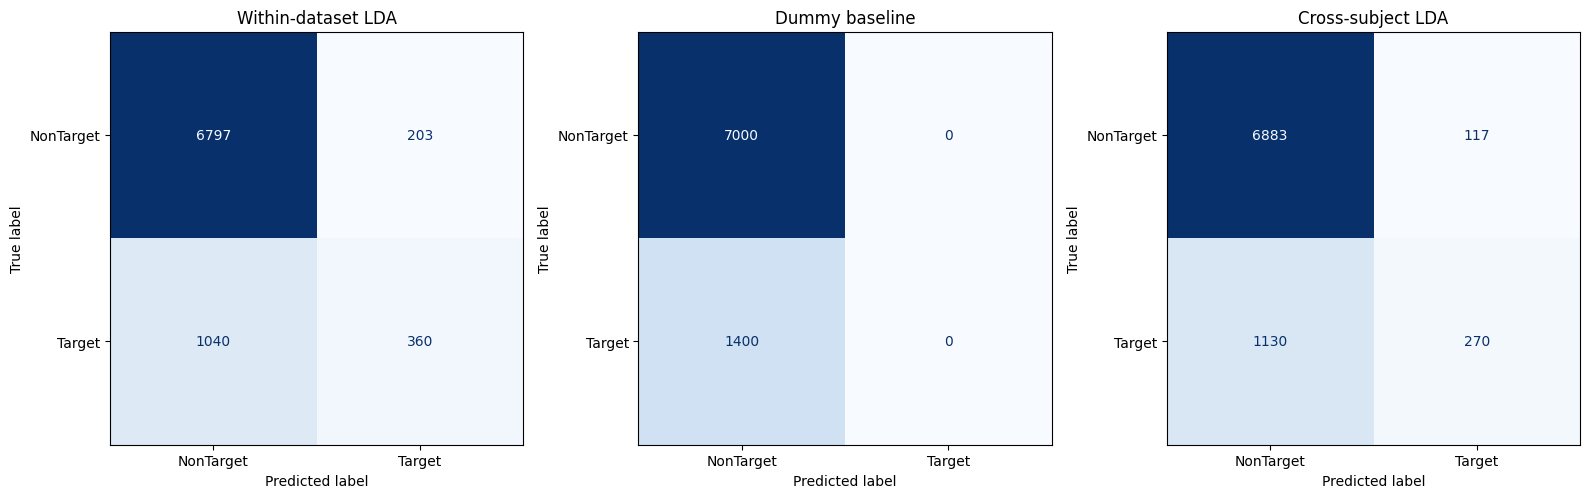


[9] MODEL PERFORMANCE COMPARISON
            model  accuracy  balanced_accuracy  precision   recall  f1_score  roc_auc
  Regularized LDA  0.852024           0.614071   0.639432 0.257143  0.366786 0.820923
 Dummy Classifier  0.833333           0.500000   0.000000 0.000000  0.000000 0.500000
Cross-Subject LDA  0.851548           0.588071   0.697674 0.192857  0.302182 0.816913

[10] GENERATING ROC-AUC COMPARISON


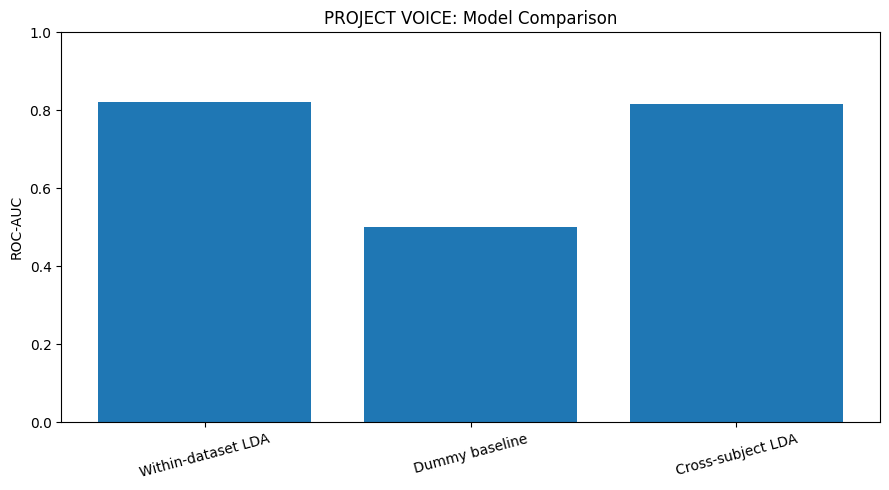


[11] SAVING TRAINED MODELS
All models saved successfully.

[12] SAVING CLASSIFICATION PREDICTIONS

[13] GENERATING EXPERIMENT REPORT

[14] PRESERVING MODULE OUTPUTS
Classification results preserved.
Cross-validation results preserved.
Prediction outputs preserved.

PROJECT VOICE | MODULE 3 COMPLETE

Experiments completed:
1. Within-dataset classification
2. Dummy baseline comparison
3. Five-fold cross-validation
4. Cross-subject generalization
5. Confusion matrix analysis
6. ROC-AUC comparison
7. Prediction export
8. Model serialization

Saved artifacts:
- model_comparison.csv
- experiment_report.json
- confusion_matrices.png
- roc_auc_comparison.png
- within_dataset_predictions.csv
- cross_subject_predictions.csv
- voice_within_dataset_lda.pkl
- voice_cross_subject_lda.pkl
- voice_dummy_baseline.pkl

STATUS: CLASSIFICATION EXPERIMENTS COMPLETE


In [ ]:
# ============================================================
# PROJECT VOICE
# MODULE 3: P300 CLASSIFICATION ENGINE
#
# Research objectives:
# 1. Binary P300 classification
# 2. Within-dataset evaluation
# 3. Cross-subject generalization
# 4. LDA vs Dummy Classifier comparison
# 5. Cross-validation
# 6. Quantitative reliability evaluation
# ============================================================

# -------------------- 1. IMPORTS ----------------------------

import os
import json
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime
from collections import Counter

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# -------------------- 2. CONFIGURATION -----------------------

PROJECT = "PROJECT VOICE"

RANDOM_STATE = 42
TEST_SIZE = 0.25
N_SPLITS = 5

HELD_OUT_SUBJECTS = ["7", "8"]

RESULT_DIR = "results/module_3"
MODEL_DIR = "models"

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("=" * 70)
print("PROJECT VOICE | MODULE 3")
print("P300 CLASSIFICATION ENGINE")
print("=" * 70)

# -------------------- 3. DATA VALIDATION ---------------------

print("\n[1] Validating input data...")

if "X" not in globals():
    raise NameError("EEG variable X is missing. Run Module 2 first.")

if "y" not in globals():
    raise NameError("Label variable y is missing. Run Module 2 first.")

if "metadata" not in globals():
    raise NameError("Metadata is missing. Run Module 2 first.")

X = np.asarray(X)
y = np.asarray(y)
metadata = metadata.reset_index(drop=True)

assert X.ndim == 3, "EEG data must have 3 dimensions."
assert len(X) == len(y), "EEG and label lengths differ."
assert len(metadata) == len(y), "Metadata and label lengths differ."
assert np.isfinite(X).all(), "EEG data contains invalid values."

print("EEG shape:", X.shape)
print("Labels:", np.unique(y))
print("Metadata:", metadata.shape)

# -------------------- 4. LABEL ENCODING ----------------------

print("\n[2] Validating classification labels...")

# Module 2 already encodes:
# NonTarget = 0
# Target = 1
#
# This section also supports original text labels.

if np.issubdtype(y.dtype, np.number):

    if not set(np.unique(y)).issubset({0, 1}):
        raise ValueError(
            f"Unexpected numeric labels: {np.unique(y)}"
        )

    y_encoded = y.astype(np.int64)

else:

    normalized_labels = [
        str(label).strip().lower()
        for label in y
    ]

    label_mapping = {
        "nontarget": 0,
        "non-target": 0,
        "target": 1
    }

    unknown_labels = (
        set(normalized_labels) - set(label_mapping)
    )

    if unknown_labels:
        raise ValueError(
            f"Unknown classification labels: {unknown_labels}"
        )

    y_encoded = np.array([
        label_mapping[label]
        for label in normalized_labels
    ], dtype=np.int64)

y = y_encoded.copy()

assert set(np.unique(y_encoded)) == {0, 1}

class_counts = Counter(y_encoded)

print("Label encoding: PASS")
print("NonTarget = 0")
print("Target = 1")
print("Class distribution:", class_counts)

# -------------------- 5. FEATURE ENGINEERING ----------------

print("\n[3] Extracting temporal EEG features...")

def extract_temporal_features(eeg_data):

    """
    Reduce temporal dimensionality while preserving
    information distributed across EEG channels.

    Input:
        epochs x channels x timepoints

    Output:
        epochs x flattened_features
    """

    reduced = eeg_data[:, :, ::4]

    features = reduced.reshape(
        reduced.shape[0],
        -1
    )

    return features


X_features = extract_temporal_features(X)

assert X_features.ndim == 2
assert np.isfinite(X_features).all()

print("Original dimensions:", X.shape)
print("Feature dimensions:", X_features.shape)
print("Feature extraction complete.")

# -------------------- 6. MODEL DEFINITIONS -------------------

print("\n[4] Initializing classifiers...")

lda_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )
    )
])

dummy_model = DummyClassifier(
    strategy="prior"
)

print("Regularized LDA initialized.")
print("Dummy baseline initialized.")

# -------------------- 7. EVALUATION FUNCTION ----------------

def evaluate_model(model, X_eval, y_eval, name):

    predictions = model.predict(X_eval)

    probabilities = model.predict_proba(X_eval)[:, 1]

    results = {

        "model": name,

        "accuracy": float(
            accuracy_score(y_eval, predictions)
        ),

        "balanced_accuracy": float(
            balanced_accuracy_score(y_eval, predictions)
        ),

        "precision": float(
            precision_score(
                y_eval,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                y_eval,
                predictions,
                zero_division=0
            )
        ),

        "f1_score": float(
            f1_score(
                y_eval,
                predictions,
                zero_division=0
            )
        ),

        "roc_auc": float(
            roc_auc_score(
                y_eval,
                probabilities
            )
        )
    }

    print("\n" + "-" * 60)
    print(name)
    print("-" * 60)

    for metric, value in results.items():

        if isinstance(value, (int, float, np.number)):
            print(f"{metric}: {value:.4f}")

    print("\nClassification report:")

    print(
        classification_report(
            y_eval,
            predictions,
            labels=[0, 1],
            target_names=["NonTarget", "Target"],
            zero_division=0
        )
    )

    return results, predictions, probabilities


# ============================================================
# EXPERIMENT A: WITHIN-DATASET CLASSIFICATION
# ============================================================

print("\n[5] EXPERIMENT A: WITHIN-DATASET CLASSIFICATION")

indices = np.arange(len(y_encoded))

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

XA_train = X_features[train_idx]
XA_test = X_features[test_idx]

yA_train = y_encoded[train_idx]
yA_test = y_encoded[test_idx]

print("Training samples:", len(XA_train))
print("Testing samples:", len(XA_test))

print("Training distribution:", Counter(yA_train))
print("Testing distribution:", Counter(yA_test))

# -------------------- TRAIN LDA ------------------------------

print("\nTraining regularized LDA...")

lda_model.fit(
    XA_train,
    yA_train
)

print("LDA training complete.")

# -------------------- TRAIN DUMMY BASELINE -------------------

print("\nTraining Dummy Classifier...")

dummy_model.fit(
    XA_train,
    yA_train
)

print("Dummy training complete.")

# -------------------- EVALUATE MODELS ------------------------

lda_results, lda_predictions, lda_probabilities = (
    evaluate_model(
        lda_model,
        XA_test,
        yA_test,
        "Regularized LDA"
    )
)

dummy_results, dummy_predictions, dummy_probabilities = (
    evaluate_model(
        dummy_model,
        XA_test,
        yA_test,
        "Dummy Classifier"
    )
)

# -------------------- 8. CROSS-VALIDATION -------------------

print("\n[6] FIVE-FOLD CROSS-VALIDATION")

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    lda_model,
    XA_train,
    yA_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

cv_summary = {}

for metric in scoring:

    values = cv_results["test_" + metric]

    cv_summary[metric] = {
        "mean": float(np.mean(values)),
        "std": float(np.std(values)),
        "individual_folds": [
            float(value) for value in values
        ]
    }

    print(
        f"{metric}: "
        f"{np.mean(values):.4f} "
        f"+/- {np.std(values):.4f}"
    )

# ============================================================
# EXPERIMENT B: CROSS-SUBJECT GENERALIZATION
# ============================================================

print("\n[7] EXPERIMENT B: CROSS-SUBJECT GENERALIZATION")

if "subject" not in metadata.columns:
    raise ValueError(
        "Metadata does not contain the required subject column."
    )

subject_ids = (
    metadata["subject"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
)

if subject_ids.isna().any():
    raise ValueError(
        "Could not identify all participant IDs."
    )

subject_ids = subject_ids.to_numpy()

available_subjects = sorted(
    set(subject_ids)
)

missing_held_out = (
    set(HELD_OUT_SUBJECTS) - set(available_subjects)
)

if missing_held_out:
    raise ValueError(
        f"Held-out subjects not found: {missing_held_out}. "
        f"Available subjects: {available_subjects}"
    )

held_out_mask = np.isin(
    subject_ids,
    HELD_OUT_SUBJECTS
)

train_subject_mask = ~held_out_mask

XB_train = X_features[train_subject_mask]
XB_test = X_features[held_out_mask]

yB_train = y_encoded[train_subject_mask]
yB_test = y_encoded[held_out_mask]

print(
    "Training participants:",
    sorted(set(subject_ids[train_subject_mask]))
)

print(
    "Held-out participants:",
    sorted(set(subject_ids[held_out_mask]))
)

print("Training samples:", len(XB_train))
print("Testing samples:", len(XB_test))

print("Training distribution:", Counter(yB_train))
print("Testing distribution:", Counter(yB_test))

if len(np.unique(yB_train)) < 2:
    raise ValueError(
        "Cross-subject training data must contain both classes."
    )

if len(np.unique(yB_test)) < 2:
    raise ValueError(
        "Held-out data must contain both classes."
    )

# -------------------- CROSS-SUBJECT MODEL --------------------

cross_subject_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )
    )
])

print("\nTraining cross-subject model...")

cross_subject_model.fit(
    XB_train,
    yB_train
)

print("Cross-subject training complete.")

cross_subject_results, cross_subject_predictions, cross_subject_probabilities = (
    evaluate_model(
        cross_subject_model,
        XB_test,
        yB_test,
        "Cross-Subject LDA"
    )
)

# -------------------- 9. CONFUSION MATRICES -----------------

print("\n[8] GENERATING CONFUSION MATRICES")

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

experiments = [
    (yA_test, lda_predictions, "Within-dataset LDA"),
    (yA_test, dummy_predictions, "Dummy baseline"),
    (yB_test, cross_subject_predictions, "Cross-subject LDA")
]

for ax, (actual, predicted, title) in zip(
    axes,
    experiments
):

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=[0, 1],
        display_labels=["NonTarget", "Target"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(title)

plt.tight_layout()

plt.savefig(
    RESULT_DIR + "/confusion_matrices.png",
    dpi=200
)

plt.show()
plt.close()

# -------------------- 10. MODEL COMPARISON ------------------

print("\n[9] MODEL PERFORMANCE COMPARISON")

comparison = pd.DataFrame([
    lda_results,
    dummy_results,
    cross_subject_results
])

print(comparison.to_string(index=False))

comparison.to_csv(
    RESULT_DIR + "/model_comparison.csv",
    index=False
)

# -------------------- 11. ROC-AUC COMPARISON ----------------

print("\n[10] GENERATING ROC-AUC COMPARISON")

model_names = [
    "Within-dataset LDA",
    "Dummy baseline",
    "Cross-subject LDA"
]

auc_values = [
    lda_results["roc_auc"],
    dummy_results["roc_auc"],
    cross_subject_results["roc_auc"]
]

plt.figure(figsize=(9, 5))

plt.bar(
    model_names,
    auc_values
)

plt.ylabel("ROC-AUC")
plt.title("PROJECT VOICE: Model Comparison")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    RESULT_DIR + "/roc_auc_comparison.png",
    dpi=200
)

plt.show()
plt.close()

# -------------------- 12. SAVE MODELS -----------------------

print("\n[11] SAVING TRAINED MODELS")

joblib.dump(
    lda_model,
    MODEL_DIR + "/voice_within_dataset_lda.pkl"
)

joblib.dump(
    cross_subject_model,
    MODEL_DIR + "/voice_cross_subject_lda.pkl"
)

joblib.dump(
    dummy_model,
    MODEL_DIR + "/voice_dummy_baseline.pkl"
)

print("All models saved successfully.")

# -------------------- 13. SAVE PREDICTIONS -------------------

print("\n[12] SAVING CLASSIFICATION PREDICTIONS")

within_predictions_df = pd.DataFrame({

    "actual_label": yA_test,

    "predicted_label": lda_predictions,

    "target_probability": lda_probabilities

})

cross_subject_predictions_df = pd.DataFrame({

    "actual_label": yB_test,

    "predicted_label": cross_subject_predictions,

    "target_probability": cross_subject_probabilities

})

within_predictions_df.to_csv(
    RESULT_DIR + "/within_dataset_predictions.csv",
    index=False
)

cross_subject_predictions_df.to_csv(
    RESULT_DIR + "/cross_subject_predictions.csv",
    index=False
)

# -------------------- 14. EXPERIMENT REPORT -----------------

print("\n[13] GENERATING EXPERIMENT REPORT")

report = {

    "project": PROJECT,

    "module": 3,

    "timestamp": datetime.now().isoformat(),

    "dataset_shape": list(X.shape),

    "feature_shape": list(X_features.shape),

    "class_distribution": {
        "NonTarget": int(class_counts.get(0, 0)),
        "Target": int(class_counts.get(1, 0))
    },

    "within_dataset": lda_results,

    "dummy_baseline": dummy_results,

    "cross_subject": cross_subject_results,

    "cross_validation": cv_summary,

    "held_out_subjects": HELD_OUT_SUBJECTS,

    "training_subjects": sorted(
        set(subject_ids[train_subject_mask])
    ),

    "status": "COMPLETED"

}

with open(
    RESULT_DIR + "/experiment_report.json",
    "w"
) as file:

    json.dump(report, file, indent=4)

# -------------------- 15. GLOBAL VARIABLE PRESERVATION -------

print("\n[14] PRESERVING MODULE OUTPUTS")

# Keep these variables available for later modules.

module3_results = comparison.copy()

stage3_cv_summary = cv_summary.copy()

stage3_predictions_df = within_predictions_df.copy()

stage3_cross_subject_predictions_df = (
    cross_subject_predictions_df.copy()
)

stage3_report = report.copy()

print("Classification results preserved.")
print("Cross-validation results preserved.")
print("Prediction outputs preserved.")

# -------------------- 16. FINAL STATUS ----------------------

print("\n" + "=" * 70)

print("PROJECT VOICE | MODULE 3 COMPLETE")

print("=" * 70)

print("\nExperiments completed:")

print("1. Within-dataset classification")
print("2. Dummy baseline comparison")
print("3. Five-fold cross-validation")
print("4. Cross-subject generalization")
print("5. Confusion matrix analysis")
print("6. ROC-AUC comparison")
print("7. Prediction export")
print("8. Model serialization")

print("\nSaved artifacts:")

print("- model_comparison.csv")
print("- experiment_report.json")
print("- confusion_matrices.png")
print("- roc_auc_comparison.png")
print("- within_dataset_predictions.csv")
print("- cross_subject_predictions.csv")
print("- voice_within_dataset_lda.pkl")
print("- voice_cross_subject_lda.pkl")
print("- voice_dummy_baseline.pkl")

print("\nSTATUS: CLASSIFICATION EXPERIMENTS COMPLETE")

print("=" * 70)

In [ ]:
print("CROSS-SUBJECT RESULTS")
print(cross_subject_results)

print("\nMODEL COMPARISON")
print(comparison.to_string(index=False))

print("\nCROSS-VALIDATION")
print(cv_summary)

CROSS-SUBJECT RESULTS
{'model': 'Cross-Subject LDA', 'accuracy': 0.851547619047619, 'balanced_accuracy': 0.5880714285714286, 'precision': 0.6976744186046512, 'recall': 0.19285714285714287, 'f1_score': 0.302182428651371, 'roc_auc': 0.8169130612244898}

MODEL COMPARISON
            model  accuracy  balanced_accuracy  precision   recall  f1_score  roc_auc
  Regularized LDA  0.852024           0.614071   0.639432 0.257143  0.366786 0.820923
 Dummy Classifier  0.833333           0.500000   0.000000 0.000000  0.000000 0.500000
Cross-Subject LDA  0.851548           0.588071   0.697674 0.192857  0.302182 0.816913

CROSS-VALIDATION
{'accuracy': {'mean': 0.8532936507936508, 'std': 0.0017233373611593957, 'individual_folds': [0.8535714285714285, 0.8543650793650793, 0.8517857142857143, 0.8557539682539682, 0.8509920634920635]}, 'balanced_accuracy': {'mean': 0.6175, 'std': 0.005257000515671366, 'individual_folds': [0.6121428571428571, 0.6192857142857143, 0.6186904761904762, 0.6258333333333334, 0.6115

In [ ]:
# ============================================================
# PROJECT VOICE — MODULE 4
# STAGE 1: DATASET EVENT / STIMULUS INSPECTION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 55)
print("PROJECT VOICE | MODULE 4")
print("STAGE 1: DATASET INSPECTION")
print("=" * 55)

# 1. Check epoch data
print("\n1. EPOCH DATA")
print("X shape:", X.shape)
print("y shape:", np.asarray(y).shape)
print("X data type:", X.dtype)

# 2. Check labels
print("\n2. CLASS DISTRIBUTION")
print(pd.Series(y).value_counts())

# 3. Inspect metadata
print("\n3. METADATA")
print("Columns:", metadata.columns.tolist())
print(metadata.head(10).to_string(index=False))

# 4. Inspect participant/session/run structure
print("\n4. DATASET STRUCTURE")

for column in ["subject", "session", "run"]:
    if column in metadata.columns:
        print(f"\n{column}:")
        print("Unique values:", metadata[column].nunique())
        print(metadata[column].value_counts().head(15))

# 5. Inspect the original raw data for ONE participant
print("\n5. ORIGINAL RAW DATA")

raw_data = dataset.get_data(subjects=[1])

subject_data = raw_data[1]
print("Sessions:", list(subject_data.keys()))

for session_name, runs in subject_data.items():
    print(f"\nSession: {session_name}")

    for run_name, raw in runs.items():
        print("Run:", run_name)
        print("Sampling frequency:", raw.info["sfreq"])
        print("Channels:", raw.ch_names)

        descriptions = np.unique(raw.annotations.description)
        print("Annotation descriptions:", descriptions[:50])

        print("Annotation count:", len(raw.annotations))

print("\nSTAGE 1 INSPECTION COMPLETE")

PROJECT VOICE | MODULE 4
STAGE 1: DATASET INSPECTION

1. EPOCH DATA
X shape: (33600, 8, 257)
y shape: (33600,)
X data type: float64

2. CLASS DISTRIBUTION
0    28000
1     5600
Name: count, dtype: int64

3. METADATA
Columns: ['subject', 'session', 'run']
 subject session run
       1       0   0
       1       0   0
       1       0   0
       1       0   0
       1       0   0
       1       0   0
       1       0   0
       1       0   0
       1       0   0
       1       0   0

4. DATASET STRUCTURE

subject:
Unique values: 8
subject
1    4200
2    4200
3    4200
4    4200
5    4200
6    4200
7    4200
8    4200
Name: count, dtype: int64

session:
Unique values: 1
session
0    33600
Name: count, dtype: int64

run:
Unique values: 1
run
0    33600
Name: count, dtype: int64

5. ORIGINAL RAW DATA
Sessions: ['0']

Session: 0
Run: 0
Sampling frequency: 256.0
Channels: ['Fz', 'Cz', 'Pz', 'Oz', 'P3', 'P4', 'PO7', 'PO8', 'Target stim', 'Flash stim']
Annotation descriptions: ['NonTarget' 'Tar

In [ ]:
# ============================================================
# PROJECT VOICE — MODULE 4
# STAGE 2: STIMULUS CHANNEL INVESTIGATION
# ============================================================

import numpy as np
import pandas as pd
import mne

print("=" * 60)
print("PROJECT VOICE | STAGE 2")
print("STIMULUS CHANNEL INVESTIGATION")
print("=" * 60)

# 1. Channel information
print("\n1. CHANNEL INFORMATION")

print("Channels:", raw.ch_names)
print("Channel types:", raw.get_channel_types())

# 2. Inspect stimulus channels
print("\n2. STIMULUS CHANNEL VALUES")

for channel in ["Target stim", "Flash stim"]:

    if channel in raw.ch_names:

        signal = raw.get_data(picks=[channel])[0]

        print(f"\nChannel: {channel}")
        print("Minimum:", np.min(signal))
        print("Maximum:", np.max(signal))
        print("Unique values:", np.unique(signal)[:30])
        print("Non-zero samples:", np.count_nonzero(signal))

        # Find changes in the signal
        changes = np.where(np.diff(signal) != 0)[0]

        print("Number of signal transitions:", len(changes))
        print("First 20 transition samples:", changes[:20])

# 3. Inspect annotations
print("\n3. ANNOTATIONS")

annotation_df = pd.DataFrame({
    "onset": raw.annotations.onset,
    "duration": raw.annotations.duration,
    "description": raw.annotations.description
})

print(annotation_df.head(20).to_string(index=False))
print("\nAnnotation descriptions:")
print(annotation_df["description"].value_counts())

# 4. Check event extraction
print("\n4. EVENT EXTRACTION")

try:
    events, event_id = mne.events_from_annotations(raw)

    print("Event ID:", event_id)
    print("Event array shape:", events.shape)
    print("First 20 events:")
    print(events[:20])

except Exception as error:
    print("Annotation event extraction error:", error)

# 5. Final summary
print("\n5. RECORDING SUMMARY")
print("Sampling frequency:", raw.info["sfreq"])
print("Recording duration:", raw.times[-1], "seconds")
print("Number of annotations:", len(raw.annotations))

print("\nSTAGE 2 COMPLETE")

PROJECT VOICE | STAGE 2
STIMULUS CHANNEL INVESTIGATION

1. CHANNEL INFORMATION
Channels: ['Fz', 'Cz', 'Pz', 'Oz', 'P3', 'P4', 'PO7', 'PO8', 'Target stim', 'Flash stim']
Channel types: ['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'stim', 'stim']

2. STIMULUS CHANNEL VALUES

Channel: Target stim
Minimum: 0.0
Maximum: 2.0
Unique values: [0. 1. 2.]
Non-zero samples: 134400
Number of signal transitions: 8400
First 20 transition samples: [1799 1831 1863 1895 1927 1959 1991 2023 2055 2087 2119 2151 2183 2215
 2247 2279 2311 2343 2375 2407]

Channel: Flash stim
Minimum: 0.0
Maximum: 14.0
Unique values: [ 0.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14.]
Non-zero samples: 134400
Number of signal transitions: 8400
First 20 transition samples: [1799 1831 1863 1895 1927 1959 1991 2023 2055 2087 2119 2151 2183 2215
 2247 2279 2311 2343 2375 2407]

3. ANNOTATIONS
   onset  duration description
 7.03125       1.0   NonTarget
 7.28125       1.0   NonTarget
 7.53125       1.0   NonTarget


PROJECT VOICE | MODULE 4
STAGE 3: STIMULUS RECONSTRUCTION

INPUT VALIDATION
Sampling frequency: 256.0
Recording duration: 1358.215 seconds
Recording samples: 347704
Annotations: 4200

TRANSITION ANALYSIS
Flash transitions: 8400
Target transitions: 8400

FLASH EVENT EXTRACTION
Recovered events: 4200
Unique flash codes: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

FLASH CODE COUNTS
flash_code
3     350
4     350
5     350
6     350
7     350
8     350
9     350
10    350
11    350
12    350
13    350
14    350

NUMBER OF UNIQUE FLASH CODES: 12
RESULT: 12 distinct flash codes detected.

TARGET CODE COUNTS
target_code
1    3500
2     700

ANNOTATION COUNTS
description
NonTarget    3500
Target        700
Name: count, dtype: int64

ANNOTATION ALIGNMENT
Aligned events: 4200
Unaligned events: 0
Mean alignment error: 0.0 seconds

TARGET CODE / ANNOTATION RELATIONSHIP
annotation_label  NonTarget  Target
target_code                        
1                      3500       0
2                      

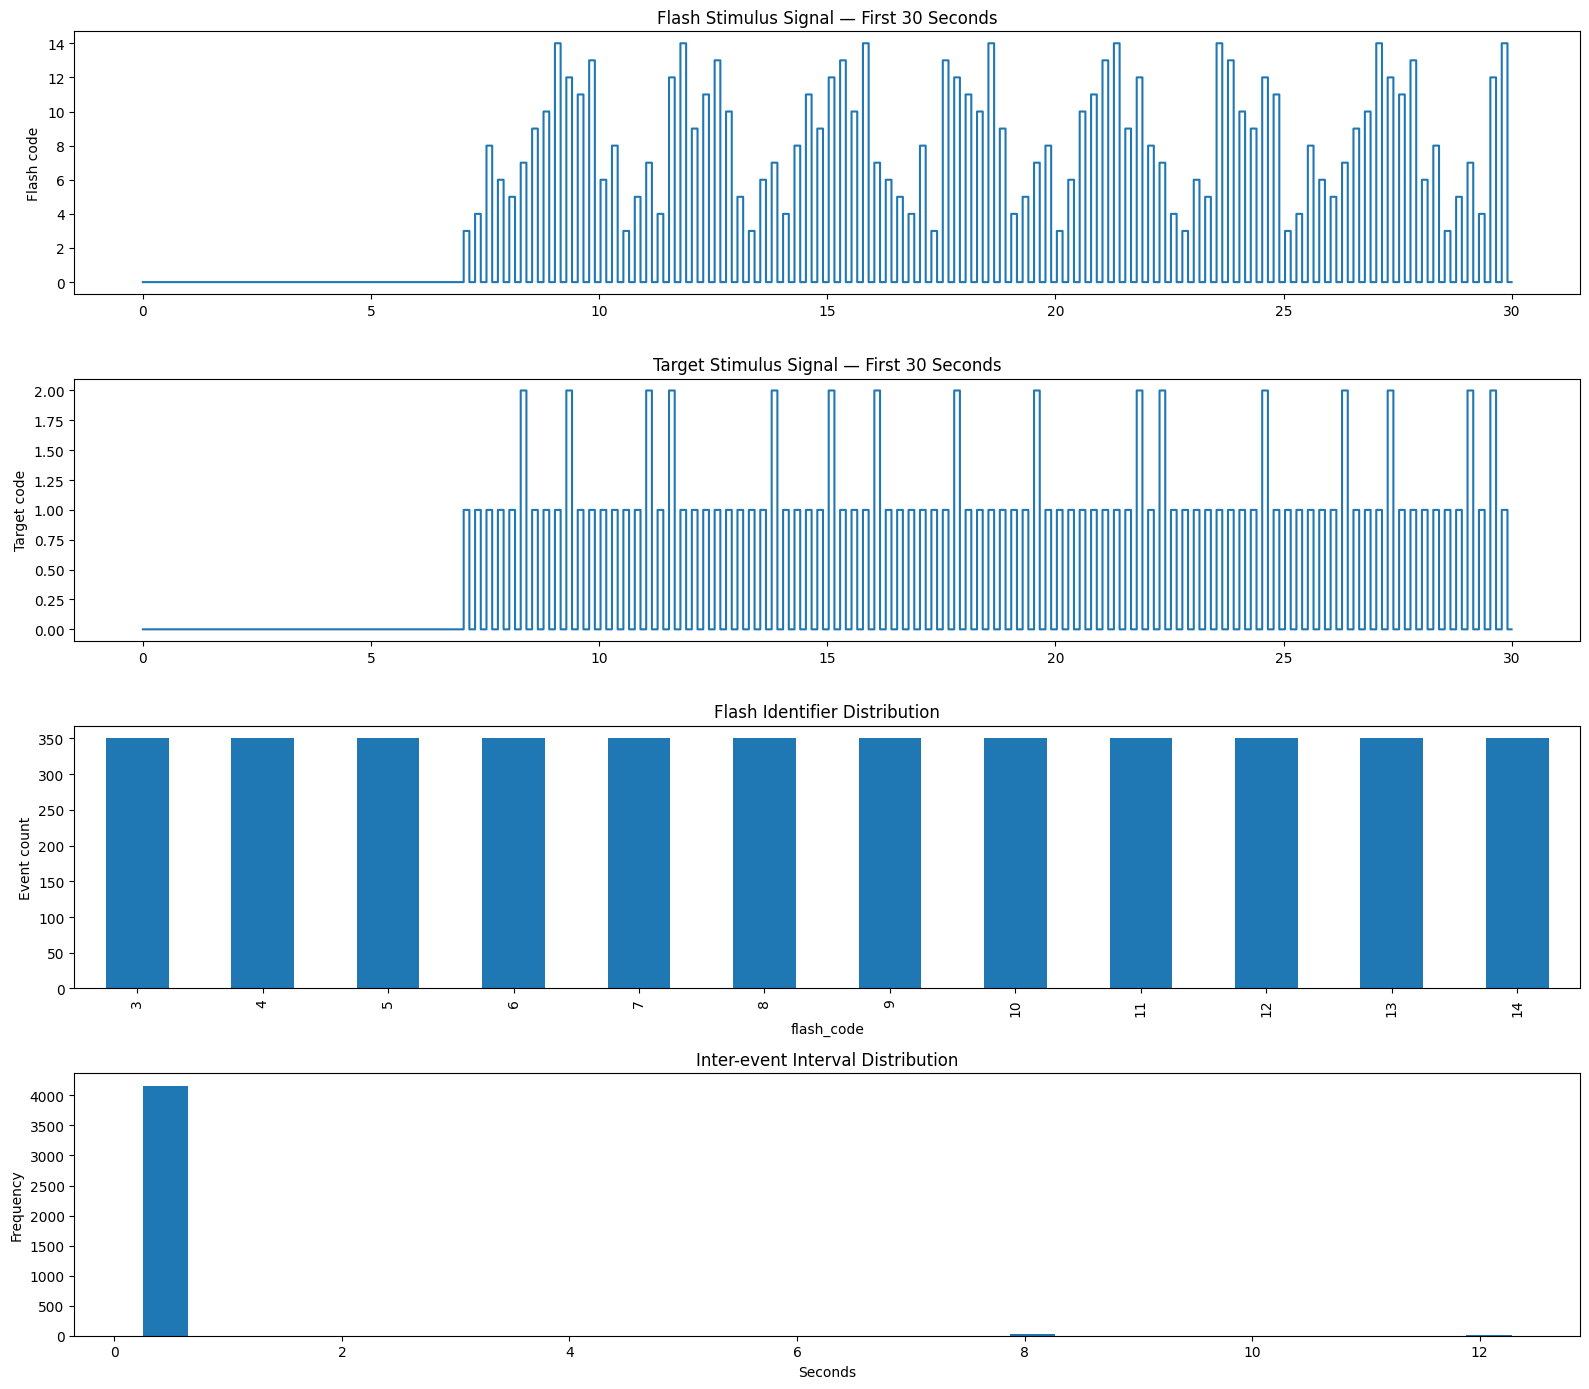


PROJECT VOICE | MODULE 4 | STAGE 3 COMPLETE

VALIDATION SUMMARY
Recovered events: 4200
Unique flash codes: 12
Annotation alignment: 100.0 %
Character mapping: NOT YET ESTABLISHED
Character decoding: NOT YET PERFORMED

EXPORTED FILES
PROJECT_VOICE_MODULE_4/module4_stimulus_diagnostics.png
PROJECT_VOICE_MODULE_4/candidate_block_analysis.csv
PROJECT_VOICE_MODULE_4/sequence_period_analysis.csv
PROJECT_VOICE_MODULE_4/target_annotation_crosstab.csv
PROJECT_VOICE_MODULE_4/reconstructed_stimulus_events.csv
PROJECT_VOICE_MODULE_4/original_annotations.csv
PROJECT_VOICE_MODULE_4/module4_stage3_validation.json

STATUS: STIMULUS RECONSTRUCTION COMPLETE


In [ ]:

# =====================================================================
# PROJECT VOICE
# MODULE 4 — CHARACTER SELECTION ENGINE
# STAGE 3 — STIMULUS RECONSTRUCTION & DECODER PREPARATION
#
# Research objectives:
# 1. Recover stimulus onset/offset events.
# 2. Extract flash and target codes.
# 3. Align stimulus events with EEG annotations.
# 4. Validate target/non-target correspondence.
# 5. Investigate 12-flash sequence structure.
# 6. Test possible repetition and character-trial structures.
# 7. Export reproducible event data and diagnostic reports.
#
# IMPORTANT:
# No assumed row/column mapping.
# No fabricated character predictions.
# =====================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

OUTPUT_DIR = "PROJECT_VOICE_MODULE_4"

os.makedirs(OUTPUT_DIR, exist_ok=True)

EXPECTED_FLASH_CODES = 12
EXPECTED_ANNOTATIONS = len(raw.annotations)

ALIGNMENT_TOLERANCE_SECONDS = 0.05

print("=" * 70)
print("PROJECT VOICE | MODULE 4")
print("STAGE 3: STIMULUS RECONSTRUCTION")
print("=" * 70)

# =====================================================================
# 2. INPUT VALIDATION
# =====================================================================

required_variables = ["raw"]

for variable in required_variables:
    if variable not in globals():
        raise RuntimeError(
            f"Required variable missing: {variable}"
        )

required_channels = [
    "Target stim",
    "Flash stim"
]

for channel in required_channels:
    if channel not in raw.ch_names:
        raise RuntimeError(
            f"Missing stimulus channel: {channel}"
        )

SFREQ = float(raw.info["sfreq"])

target_signal = raw.get_data(
    picks=["Target stim"]
)[0]

flash_signal = raw.get_data(
    picks=["Flash stim"]
)[0]

if len(target_signal) != len(flash_signal):
    raise ValueError(
        "Stimulus channel lengths do not match."
    )

print("\nINPUT VALIDATION")
print("Sampling frequency:", SFREQ)
print("Recording duration:", round(raw.times[-1], 3), "seconds")
print("Recording samples:", len(target_signal))
print("Annotations:", EXPECTED_ANNOTATIONS)

# =====================================================================
# 3. DETECT ALL STIMULUS TRANSITIONS
# =====================================================================

def detect_transitions(signal):

    transitions = np.where(
        np.diff(signal) != 0
    )[0] + 1

    return transitions


flash_transitions = detect_transitions(
    flash_signal
)

target_transitions = detect_transitions(
    target_signal
)

print("\nTRANSITION ANALYSIS")
print("Flash transitions:", len(flash_transitions))
print("Target transitions:", len(target_transitions))

# =====================================================================
# 4. DETECT FLASH EVENT ONSETS AND OFFSETS
# =====================================================================

# This method detects:
# - zero -> nonzero transitions
# - changes between different nonzero codes
#
# It therefore does not silently discard adjacent code changes.

flash_changes = np.r_[
    0,
    flash_transitions,
    len(flash_signal)
]

event_records = []

for i in range(len(flash_changes) - 1):

    start = int(flash_changes[i])
    end = int(flash_changes[i + 1])

    code = int(flash_signal[start])

    if code == 0:
        continue

    duration_samples = end - start

    event_records.append({

        "event_number": len(event_records) + 1,

        "onset_sample": start,

        "offset_sample": end,

        "onset_seconds": start / SFREQ,

        "offset_seconds": end / SFREQ,

        "duration_seconds": duration_samples / SFREQ,

        "flash_code": code,

        "target_code": int(target_signal[start])

    })


events_df = pd.DataFrame(event_records)

if events_df.empty:
    raise RuntimeError(
        "No nonzero flash events were detected."
    )

print("\nFLASH EVENT EXTRACTION")
print("Recovered events:", len(events_df))
print("Unique flash codes:", sorted(
    events_df["flash_code"].unique().tolist()
))

# =====================================================================
# 5. FLASH CODE VALIDATION
# =====================================================================

flash_distribution = (
    events_df["flash_code"]
    .value_counts()
    .sort_index()
)

print("\nFLASH CODE COUNTS")
print(flash_distribution.to_string())

unique_flash_codes = sorted(
    events_df["flash_code"].unique().tolist()
)

print("\nNUMBER OF UNIQUE FLASH CODES:",
      len(unique_flash_codes))

if len(unique_flash_codes) == EXPECTED_FLASH_CODES:
    print("RESULT: 12 distinct flash codes detected.")
else:
    print(
        "NOTICE: Number of flash codes differs from 12."
    )

# =====================================================================
# 6. TARGET CODE DISTRIBUTION
# =====================================================================

target_distribution = (
    events_df["target_code"]
    .value_counts()
    .sort_index()
)

print("\nTARGET CODE COUNTS")
print(target_distribution.to_string())

# =====================================================================
# 7. ANNOTATION EXTRACTION
# =====================================================================

annotations_df = pd.DataFrame({

    "annotation_number": np.arange(
        1,
        len(raw.annotations) + 1
    ),

    "onset_seconds": raw.annotations.onset,

    "duration_seconds": raw.annotations.duration,

    "description": raw.annotations.description

})

annotations_df["onset_sample"] = np.round(
    annotations_df["onset_seconds"] * SFREQ
).astype(int)

print("\nANNOTATION COUNTS")
print(
    annotations_df["description"]
    .value_counts()
)

# =====================================================================
# 8. ALIGN STIMULUS EVENTS WITH ANNOTATIONS
# =====================================================================

annotation_times = annotations_df[
    "onset_seconds"
].to_numpy()

annotation_labels = annotations_df[
    "description"
].to_numpy()

event_times = events_df[
    "onset_seconds"
].to_numpy()

aligned_labels = []
alignment_errors = []

for event_time in event_times:

    insertion = np.searchsorted(
        annotation_times,
        event_time
    )

    candidates = []

    if insertion < len(annotation_times):
        candidates.append(insertion)

    if insertion > 0:
        candidates.append(insertion - 1)

    if not candidates:
        aligned_labels.append(None)
        alignment_errors.append(np.nan)
        continue

    nearest = min(
        candidates,
        key=lambda idx: abs(
            annotation_times[idx] - event_time
        )
    )

    error = abs(
        annotation_times[nearest] - event_time
    )

    if error <= ALIGNMENT_TOLERANCE_SECONDS:

        aligned_labels.append(
            annotation_labels[nearest]
        )

        alignment_errors.append(error)

    else:

        aligned_labels.append(None)
        alignment_errors.append(error)


events_df["annotation_label"] = aligned_labels

events_df["alignment_error_seconds"] = (
    alignment_errors
)

events_df["annotation_aligned"] = (
    events_df["annotation_label"].notna()
)

aligned_count = int(
    events_df["annotation_aligned"].sum()
)

print("\nANNOTATION ALIGNMENT")
print("Aligned events:", aligned_count)
print("Unaligned events:", len(events_df) - aligned_count)

if aligned_count > 0:

    print(
        "Mean alignment error:",
        round(
            events_df.loc[
                events_df["annotation_aligned"],
                "alignment_error_seconds"
            ].mean(),
            6
        ),
        "seconds"
    )

# =====================================================================
# 9. TARGET CODE VS ANNOTATION VALIDATION
# =====================================================================

print("\nTARGET CODE / ANNOTATION RELATIONSHIP")

aligned_df = events_df[
    events_df["annotation_aligned"]
].copy()

if len(aligned_df) > 0:

    target_annotation_table = pd.crosstab(
        aligned_df["target_code"],
        aligned_df["annotation_label"]
    )

    print(target_annotation_table)

    target_annotation_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "target_annotation_crosstab.csv"
        )
    )

else:

    target_annotation_table = pd.DataFrame()

    print("No aligned events available.")

# =====================================================================
# 10. TIMING ANALYSIS
# =====================================================================

event_times = events_df[
    "onset_seconds"
].to_numpy()

intervals = np.diff(event_times)

timing_report = {

    "mean_interval_seconds": float(
        np.mean(intervals)
    ),

    "median_interval_seconds": float(
        np.median(intervals)
    ),

    "std_interval_seconds": float(
        np.std(intervals)
    ),

    "minimum_interval_seconds": float(
        np.min(intervals)
    ),

    "maximum_interval_seconds": float(
        np.max(intervals)
    ),

    "mean_event_duration_seconds": float(
        events_df["duration_seconds"].mean()
    )

}

print("\nTIMING REPORT")

for key, value in timing_report.items():

    print(
        key,
        ":",
        round(value, 6)
    )

# =====================================================================
# 11. FLASH SEQUENCE INVESTIGATION
# =====================================================================

flash_sequence = events_df[
    "flash_code"
].to_numpy()

sequence_report = []

for period in range(1, 241):

    if len(flash_sequence) <= period:
        break

    match_fraction = np.mean(
        flash_sequence[period:] ==
        flash_sequence[:-period]
    )

    sequence_report.append({

        "period": period,

        "matching_fraction": float(
            match_fraction
        )

    })


sequence_df = pd.DataFrame(
    sequence_report
)

print("\nTOP REPEATING PERIOD CANDIDATES")

print(
    sequence_df.sort_values(
        "matching_fraction",
        ascending=False
    ).head(15).to_string(index=False)
)

# =====================================================================
# 12. CANDIDATE BLOCK ANALYSIS
# =====================================================================

# We investigate possible blocks of 12 and 120 events.
# These are hypotheses to inspect, NOT assumed character boundaries.

candidate_block_results = []

for block_size in [12, 24, 60, 120]:

    number_of_blocks = (
        len(events_df) // block_size
    )

    if number_of_blocks == 0:
        continue

    for block_number in range(number_of_blocks):

        start = block_number * block_size
        end = start + block_size

        block = events_df.iloc[start:end]

        counts = block["flash_code"].value_counts()

        candidate_block_results.append({

            "block_size": block_size,

            "block_number": block_number + 1,

            "event_start": start + 1,

            "event_end": end,

            "unique_flash_codes": int(
                block["flash_code"].nunique()
            ),

            "target_annotations": int(
                (block["annotation_label"] == "Target").sum()
            ),

            "nontarget_annotations": int(
                (block["annotation_label"] == "NonTarget").sum()
            ),

            "flash_code_counts": json.dumps(
                counts.sort_index().to_dict()
            )

        })


block_df = pd.DataFrame(
    candidate_block_results
)

print("\nCANDIDATE BLOCK ANALYSIS")

if len(block_df) > 0:

    for block_size in [12, 24, 60, 120]:

        subset = block_df[
            block_df["block_size"] == block_size
        ]

        if len(subset) > 0:

            print(
                f"\nBlock size {block_size}:"
            )

            print(
                subset.head(3).to_string(
                    index=False
                )
            )

# =====================================================================
# 13. VISUALIZATION
# =====================================================================

fig, axes = plt.subplots(
    4,
    1,
    figsize=(16, 14)
)

# Flash code signal
plot_end = min(
    len(flash_signal),
    int(30 * SFREQ)
)

time_axis = np.arange(
    plot_end
) / SFREQ

axes[0].step(
    time_axis,
    flash_signal[:plot_end],
    where="post"
)

axes[0].set_title(
    "Flash Stimulus Signal — First 30 Seconds"
)

axes[0].set_ylabel("Flash code")

# Target signal
axes[1].step(
    time_axis,
    target_signal[:plot_end],
    where="post"
)

axes[1].set_title(
    "Target Stimulus Signal — First 30 Seconds"
)

axes[1].set_ylabel("Target code")

# Flash distribution
flash_distribution.plot(
    kind="bar",
    ax=axes[2]
)

axes[2].set_title(
    "Flash Identifier Distribution"
)

axes[2].set_ylabel("Event count")

# Event interval distribution
axes[3].hist(
    intervals,
    bins=30
)

axes[3].set_title(
    "Inter-event Interval Distribution"
)

axes[3].set_xlabel("Seconds")
axes[3].set_ylabel("Frequency")

plt.tight_layout()

plot_path = os.path.join(
    OUTPUT_DIR,
    "module4_stimulus_diagnostics.png"
)

plt.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# =====================================================================
# 14. EXPORT EVENT TABLES
# =====================================================================

events_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "reconstructed_stimulus_events.csv"
    ),
    index=False
)

annotations_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "original_annotations.csv"
    ),
    index=False
)

sequence_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "sequence_period_analysis.csv"
    ),
    index=False
)

block_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "candidate_block_analysis.csv"
    ),
    index=False
)

# =====================================================================
# 15. AUTOMATED VALIDATION REPORT
# =====================================================================

validation = {

    "module": "Project VOICE Module 4",

    "stage": "Stage 3 - Stimulus Reconstruction",

    "sampling_frequency": SFREQ,

    "recording_duration_seconds": float(
        raw.times[-1]
    ),

    "recovered_flash_events": int(
        len(events_df)
    ),

    "unique_flash_codes": unique_flash_codes,

    "unique_flash_code_count": int(
        len(unique_flash_codes)
    ),

    "expected_flash_code_count": EXPECTED_FLASH_CODES,

    "annotation_count": int(
        len(annotations_df)
    ),

    "aligned_event_count": aligned_count,

    "alignment_fraction": float(
        aligned_count / len(events_df)
    ),

    "target_code_distribution": {
        str(k): int(v)
        for k, v in target_distribution.items()
    },

    "flash_code_distribution": {
        str(k): int(v)
        for k, v in flash_distribution.items()
    },

    "timing": timing_report,

    "character_mapping_recovered": False,

    "character_decoding_performed": False

}

report_path = os.path.join(
    OUTPUT_DIR,
    "module4_stage3_validation.json"
)

with open(report_path, "w") as file:

    json.dump(
        validation,
        file,
        indent=4
    )

# =====================================================================
# 16. FINAL STATUS
# =====================================================================

print("\n" + "=" * 70)

print("PROJECT VOICE | MODULE 4 | STAGE 3 COMPLETE")

print("=" * 70)

print("\nVALIDATION SUMMARY")

print(
    "Recovered events:",
    validation["recovered_flash_events"]
)

print(
    "Unique flash codes:",
    validation["unique_flash_code_count"]
)

print(
    "Annotation alignment:",
    round(
        validation["alignment_fraction"] * 100,
        2
    ),
    "%"
)

print(
    "Character mapping:",
    "NOT YET ESTABLISHED"
)

print(
    "Character decoding:",
    "NOT YET PERFORMED"
)

print("\nEXPORTED FILES")

for filename in os.listdir(OUTPUT_DIR):

    print(
        os.path.join(
            OUTPUT_DIR,
            filename
        )
    )

print("\nSTATUS: STIMULUS RECONSTRUCTION COMPLETE")


PROJECT VOICE | MODULE 4
STAGE 4: CROSS-SUBJECT CODE-PAIR DECODER

DATASET
X: (33600, 8, 257)
y: (33600,)
Participants: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

CLASS COUNTS
0    28000
1     5600
Name: count, dtype: int64

FEATURE EXTRACTION
Feature matrix: (33600, 520)

HELD-OUT PARTICIPANT: 1
Training epochs: 29400
Testing epochs: 4200
Valid 120-event trials: 35 / 35
Participant ROC-AUC: 0.7685
Completed decoding: 35 trials

HELD-OUT PARTICIPANT: 2
Training epochs: 29400
Testing epochs: 4200
Valid 120-event trials: 35 / 35
Participant ROC-AUC: 0.7572
Completed decoding: 35 trials

HELD-OUT PARTICIPANT: 3
Training epochs: 29400
Testing epochs: 4200
Valid 120-event trials: 35 / 35
Participant ROC-AUC: 0.8365
Completed decoding: 35 trials

HELD-OUT PARTICIPANT: 4
Training epochs: 29400
Testing epochs: 4200
Valid 120-event trials: 35 / 35
Participant ROC-AUC: 0.7423
Completed decoding: 35 trials

HELD-OUT PARTICIPANT: 5
Tra

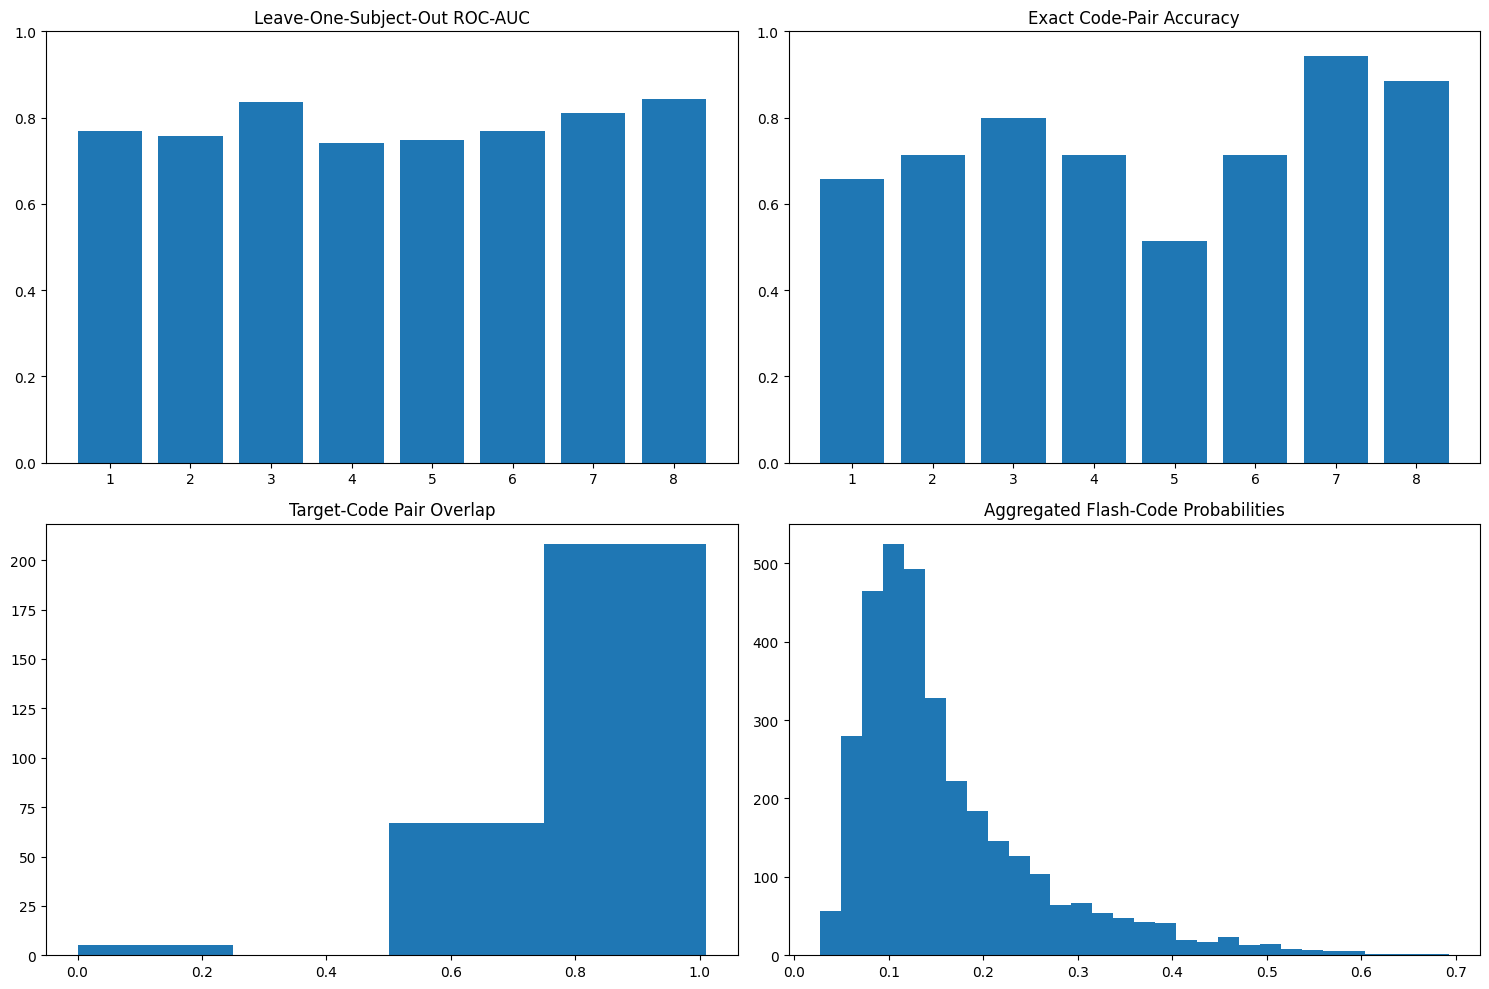


PROJECT VOICE | MODULE 4 | STAGE 4 COMPLETE
Participants: 8
Decoded trials: 280
Exact code-pair accuracy: 74.29 %
Mean code-pair overlap: 86.25 %
Mean subject ROC-AUC: 0.7845
Character decoding: NOT CLAIMED — grid mapping still required

STATUS: CODE-PAIR DECODING EXPERIMENT COMPLETE


In [ ]:

# =====================================================================
# PROJECT VOICE
# MODULE 4 — STAGE 4
# CROSS-SUBJECT P300 EVIDENCE AGGREGATION & CODE-PAIR DECODER
#
# Objectives:
# 1. Train participant-independent P300 classifiers.
# 2. Predict target probabilities for held-out participants.
# 3. Organize events into 120-event character trials.
# 4. Aggregate evidence across 10 repetitions per flash code.
# 5. Select the two highest-scoring stimulus codes.
# 6. Evaluate target-code pair accuracy.
#
# Output is a code pair, NOT a decoded character.
# =====================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

OUTPUT_DIR = "PROJECT_VOICE_MODULE_4_STAGE4"

os.makedirs(OUTPUT_DIR, exist_ok=True)

EVENTS_PER_TRIAL = 120
EXPECTED_REPETITIONS = 10
EXPECTED_FLASHES = 12
EXPECTED_TARGET_CODES = 2

SUBJECTS = sorted(
    metadata["subject"].unique(),
    key=lambda x: int(x)
)

print("=" * 72)
print("PROJECT VOICE | MODULE 4")
print("STAGE 4: CROSS-SUBJECT CODE-PAIR DECODER")
print("=" * 72)

# =====================================================================
# 2. INPUT VALIDATION
# =====================================================================

X_array = np.asarray(X)
y_array = np.asarray(y)
metadata_df = metadata.reset_index(drop=True).copy()

if len(X_array) != len(y_array):
    raise ValueError("X and y lengths do not match.")

if len(X_array) != len(metadata_df):
    raise ValueError("X and metadata lengths do not match.")

if X_array.ndim != 3:
    raise ValueError("Expected X shape: epochs x channels x samples.")

if not {"subject", "session", "run"}.issubset(
    metadata_df.columns
):
    raise ValueError("Required metadata columns are missing.")

print("\nDATASET")
print("X:", X_array.shape)
print("y:", y_array.shape)
print("Participants:", SUBJECTS)

# =====================================================================
# 3. LABEL ENCODING
# =====================================================================

unique_labels = set(
    str(value) for value in np.unique(y_array)
)

if unique_labels == {"Target", "NonTarget"}:

    y_binary = np.array([
        1 if str(value) == "Target" else 0
        for value in y_array
    ])

elif unique_labels == {"0", "1"}:

    y_binary = y_array.astype(int)

else:
    raise ValueError(
        f"Unexpected label set: {unique_labels}"
    )

print("\nCLASS COUNTS")
print(pd.Series(y_binary).value_counts().sort_index())

# =====================================================================
# 4. FEATURE EXTRACTION
# =====================================================================

def extract_features(eeg_epochs):

    eeg_epochs = np.asarray(eeg_epochs)

    if eeg_epochs.ndim != 3:
        raise ValueError("Expected 3D EEG epoch array.")

    # Preserve Module 3's temporal subsampling approach.
    subsampled = eeg_epochs[:, :, ::4]

    features = subsampled.reshape(
        len(subsampled),
        -1
    )

    return features


X_features = extract_features(X_array)

print("\nFEATURE EXTRACTION")
print("Feature matrix:", X_features.shape)

# =====================================================================
# 5. BUILD CLASSIFIER
# =====================================================================

def build_classifier():

    return Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "lda",
            LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage="auto"
            )
        )

    ])


# =====================================================================
# 6. HELPER: EXTRACT FLASH CODES FROM RAW RECORDING
# =====================================================================

def extract_flash_events(subject_id):

    subject_recordings = dataset.get_data(
        subjects=[int(subject_id)]
    )

    if int(subject_id) not in subject_recordings:
        raise RuntimeError(
            f"Raw data unavailable for subject {subject_id}"
        )

    sessions = subject_recordings[int(subject_id)]

    if len(sessions) != 1:
        raise RuntimeError(
            f"Expected one session for subject {subject_id}"
        )

    session_name = list(sessions.keys())[0]
    runs = sessions[session_name]

    if len(runs) != 1:
        raise RuntimeError(
            f"Expected one run for subject {subject_id}"
        )

    run_name = list(runs.keys())[0]
    subject_raw = runs[run_name]

    if "Flash stim" not in subject_raw.ch_names:
        raise RuntimeError(
            "Flash stim channel unavailable."
        )

    flash = subject_raw.get_data(
        picks=["Flash stim"]
    )[0]

    sfreq = float(subject_raw.info["sfreq"])

    onsets = np.where(
        (flash != 0) &
        (np.r_[True, flash[:-1] == 0])
    )[0]

    codes = flash[onsets].astype(int)

    return {
        "codes": codes,
        "onsets": onsets,
        "sfreq": sfreq,
        "raw": subject_raw
    }


# =====================================================================
# 7. HELPER: VALIDATE TRIAL STRUCTURE
# =====================================================================

def validate_trial_structure(
    codes,
    labels,
    subject_id
):

    if len(codes) != len(labels):
        raise ValueError(
            f"Subject {subject_id}: flash and label counts differ."
        )

    if len(codes) % EVENTS_PER_TRIAL != 0:
        raise ValueError(
            f"Subject {subject_id}: event count not divisible by 120."
        )

    number_of_trials = (
        len(codes) // EVENTS_PER_TRIAL
    )

    report = []

    for trial_index in range(number_of_trials):

        start = trial_index * EVENTS_PER_TRIAL
        end = start + EVENTS_PER_TRIAL

        trial_codes = codes[start:end]
        trial_labels = labels[start:end]

        unique_codes, code_counts = np.unique(
            trial_codes,
            return_counts=True
        )

        target_codes = np.unique(
            trial_codes[trial_labels == 1]
        )

        valid = (

            len(unique_codes) == EXPECTED_FLASHES

            and np.all(
                code_counts == EXPECTED_REPETITIONS
            )

            and len(target_codes) == EXPECTED_TARGET_CODES

            and np.sum(trial_labels == 1) == 20

        )

        report.append({

            "trial": trial_index + 1,

            "valid_structure": bool(valid),

            "unique_flash_codes": len(unique_codes),

            "target_event_count": int(
                np.sum(trial_labels == 1)
            ),

            "target_code_count": len(target_codes),

            "target_codes": target_codes.tolist()

        })

    return pd.DataFrame(report)


# =====================================================================
# 8. HELPER: AGGREGATE CLASSIFIER EVIDENCE
# =====================================================================

def decode_trial(
    probabilities,
    codes,
    labels,
    subject_id,
    trial_number
):

    unique_codes = np.sort(
        np.unique(codes)
    )

    score_records = []

    for code in unique_codes:

        mask = codes == code

        code_probabilities = probabilities[mask]

        mean_score = float(
            np.mean(code_probabilities)
        )

        median_score = float(
            np.median(code_probabilities)
        )

        true_target_events = int(
            np.sum(labels[mask] == 1)
        )

        score_records.append({

            "subject": int(subject_id),

            "trial": int(trial_number),

            "flash_code": int(code),

            "mean_target_probability": mean_score,

            "median_target_probability": median_score,

            "event_count": int(np.sum(mask)),

            "ground_truth_target_events": true_target_events

        })

    scores_df = pd.DataFrame(score_records)

    # Highest average target probability wins.
    ranked = scores_df.sort_values(
        "mean_target_probability",
        ascending=False
    )

    predicted_pair = set(
        ranked.head(2)["flash_code"].astype(int)
    )

    true_pair = set(
        scores_df.loc[
            scores_df["ground_truth_target_events"] > 0,
            "flash_code"
        ].astype(int)
    )

    exact_pair_match = (
        predicted_pair == true_pair
    )

    # Pair-wise overlap score.
    overlap = len(
        predicted_pair.intersection(true_pair)
    ) / EXPECTED_TARGET_CODES

    scores_df["predicted_rank"] = (
        scores_df["mean_target_probability"]
        .rank(ascending=False, method="min")
        .astype(int)
    )

    scores_df["predicted_target_code"] = (
        scores_df["flash_code"].isin(predicted_pair)
    )

    scores_df["actual_target_code"] = (
        scores_df["ground_truth_target_events"] > 0
    )

    result = {

        "subject": int(subject_id),

        "trial": int(trial_number),

        "predicted_pair": sorted(predicted_pair),

        "true_pair": sorted(true_pair),

        "exact_pair_match": bool(exact_pair_match),

        "pair_overlap": float(overlap)

    }

    return result, scores_df


# =====================================================================
# 9. LEAVE-ONE-SUBJECT-OUT EXPERIMENT
# =====================================================================

all_decoding_results = []
all_code_scores = []
all_subject_metrics = []
all_structure_reports = []

for held_out_subject in SUBJECTS:

    print("\n" + "=" * 65)
    print("HELD-OUT PARTICIPANT:", held_out_subject)
    print("=" * 65)

    train_mask = (
        metadata_df["subject"] != held_out_subject
    ).to_numpy()

    test_mask = (
        metadata_df["subject"] == held_out_subject
    ).to_numpy()

    X_train = X_features[train_mask]
    y_train = y_binary[train_mask]

    X_test = X_features[test_mask]
    y_test = y_binary[test_mask]

    print("Training epochs:", len(X_train))
    print("Testing epochs:", len(X_test))

    # Fit on other seven participants only.
    model = build_classifier()

    model.fit(
        X_train,
        y_train
    )

    # Predict held-out participant.
    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    subject_auc = roc_auc_score(
        y_test,
        probabilities
    )

    subject_metrics = {

        "subject": int(held_out_subject),

        "accuracy": float(
            accuracy_score(y_test, predictions)
        ),

        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_test,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                y_test,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                y_test,
                predictions,
                zero_division=0
            )
        ),

        "f1": float(
            f1_score(
                y_test,
                predictions,
                zero_division=0
            )
        ),

        "roc_auc": float(subject_auc)

    }

    all_subject_metrics.append(
        subject_metrics
    )

    # Extract flash identifiers for this participant.
    raw_info = extract_flash_events(
        held_out_subject
    )

    flash_codes = raw_info["codes"]

    if len(flash_codes) != len(y_test):
        raise RuntimeError(
            f"Subject {held_out_subject}: "
            "raw flash events do not match epoch count."
        )

    # Verify raw annotations correspond to epoch labels.
    annotation_labels = (
        raw_info["raw"].annotations.description
    )

    annotation_binary = np.array([
        1 if str(label) == "Target" else 0
        for label in annotation_labels
    ])

    if not np.array_equal(
        annotation_binary,
        y_test
    ):
        raise RuntimeError(
            f"Subject {held_out_subject}: "
            "annotation ordering does not match X/y."
        )

    # Validate 120-event blocks.
    structure_df = validate_trial_structure(
        flash_codes,
        y_test,
        held_out_subject
    )

    structure_df["subject"] = int(
        held_out_subject
    )

    all_structure_reports.append(
        structure_df
    )

    valid_trials = structure_df[
        structure_df["valid_structure"]
    ]

    print(
        "Valid 120-event trials:",
        len(valid_trials),
        "/",
        len(structure_df)
    )

    # Decode every valid character trial.
    for trial_number in valid_trials["trial"]:

        start = (
            int(trial_number) - 1
        ) * EVENTS_PER_TRIAL

        end = start + EVENTS_PER_TRIAL

        trial_codes = flash_codes[start:end]
        trial_labels = y_test[start:end]

        trial_probabilities = probabilities[start:end]

        result, score_table = decode_trial(
            trial_probabilities,
            trial_codes,
            trial_labels,
            held_out_subject,
            trial_number
        )

        all_decoding_results.append(result)

        all_code_scores.append(score_table)

    print(
        "Participant ROC-AUC:",
        round(subject_auc, 4)
    )

    print(
        "Completed decoding:",
        len(valid_trials),
        "trials"
    )


# =====================================================================
# 10. COMBINE RESULTS
# =====================================================================

decoding_df = pd.DataFrame(
    all_decoding_results
)

code_scores_df = pd.concat(
    all_code_scores,
    ignore_index=True
)

subject_metrics_df = pd.DataFrame(
    all_subject_metrics
)

structure_df = pd.concat(
    all_structure_reports,
    ignore_index=True
)

print("\n" + "=" * 72)
print("DECODING RESULTS")
print("=" * 72)

print("\nSUBJECT CLASSIFICATION METRICS")

print(
    subject_metrics_df.to_string(
        index=False
    )
)

print("\nTRIAL STRUCTURE")

print(
    structure_df.groupby(
        "subject"
    )["valid_structure"].agg(
        ["sum", "count"]
    )
)

# =====================================================================
# 11. CODE-PAIR PERFORMANCE
# =====================================================================

if len(decoding_df) == 0:
    raise RuntimeError(
        "No valid trials were decoded."
    )

pair_accuracy = float(
    decoding_df["exact_pair_match"].mean()
)

mean_pair_overlap = float(
    decoding_df["pair_overlap"].mean()
)

print("\nCODE-PAIR DECODING")

print(
    "Exact target-code pair accuracy:",
    round(pair_accuracy * 100, 2),
    "%"
)

print(
    "Mean target-code overlap:",
    round(mean_pair_overlap * 100, 2),
    "%"
)

print(
    "Total decoded trials:",
    len(decoding_df)
)

print(
    "Correct pairs:",
    int(decoding_df["exact_pair_match"].sum())
)

# =====================================================================
# 12. SUBJECT-LEVEL DECODING PERFORMANCE
# =====================================================================

subject_pair_performance = (
    decoding_df.groupby("subject")
    .agg(
        trials=("trial", "count"),

        exact_pair_accuracy=(
            "exact_pair_match",
            "mean"
        ),

        mean_pair_overlap=(
            "pair_overlap",
            "mean"
        )
    )
    .reset_index()
)

print("\nSUBJECT-LEVEL PAIR ACCURACY")

print(
    subject_pair_performance.to_string(
        index=False
    )
)

# =====================================================================
# 13. DIAGNOSTIC VISUALIZATIONS
# =====================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10)
)

# A. Subject ROC-AUC
axes[0, 0].bar(
    subject_metrics_df["subject"].astype(str),
    subject_metrics_df["roc_auc"]
)

axes[0, 0].set_title(
    "Leave-One-Subject-Out ROC-AUC"
)

axes[0, 0].set_ylim(0, 1)

# B. Subject pair accuracy
axes[0, 1].bar(
    subject_pair_performance["subject"].astype(str),
    subject_pair_performance["exact_pair_accuracy"]
)

axes[0, 1].set_title(
    "Exact Code-Pair Accuracy"
)

axes[0, 1].set_ylim(0, 1)

# C. Pair overlap distribution
axes[1, 0].hist(
    decoding_df["pair_overlap"],
    bins=[0, 0.25, 0.5, 0.75, 1.01]
)

axes[1, 0].set_title(
    "Target-Code Pair Overlap"
)

# D. Predicted probability distribution
axes[1, 1].hist(
    code_scores_df[
        "mean_target_probability"
    ],
    bins=30
)

axes[1, 1].set_title(
    "Aggregated Flash-Code Probabilities"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "stage4_decoder_diagnostics.png"
    ),
    dpi=180
)

plt.show()

# =====================================================================
# 14. EXPORT RESULTS
# =====================================================================

decoding_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "trial_code_pair_predictions.csv"
    ),
    index=False
)

code_scores_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "flash_code_probability_scores.csv"
    ),
    index=False
)

subject_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "subject_classification_metrics.csv"
    ),
    index=False
)

subject_pair_performance.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "subject_pair_performance.csv"
    ),
    index=False
)

structure_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "trial_structure_validation.csv"
    ),
    index=False
)

# =====================================================================
# 15. FINAL REPORT
# =====================================================================

final_report = {

    "project": "PROJECT VOICE",

    "module": 4,

    "stage": 4,

    "experiment": "Leave-One-Subject-Out Code-Pair Decoding",

    "participants": [
        int(subject) for subject in SUBJECTS
    ],

    "events_per_character_trial": EVENTS_PER_TRIAL,

    "flash_identifiers_per_trial": EXPECTED_FLASHES,

    "repetitions_per_identifier": EXPECTED_REPETITIONS,

    "valid_trials": int(
        structure_df["valid_structure"].sum()
    ),

    "total_trials": int(
        len(structure_df)
    ),

    "decoded_trials": int(
        len(decoding_df)
    ),

    "exact_pair_accuracy": pair_accuracy,

    "mean_pair_overlap": mean_pair_overlap,

    "mean_subject_roc_auc": float(
        subject_metrics_df["roc_auc"].mean()
    ),

    "character_mapping_established": False,

    "literal_character_accuracy_measured": False

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "stage4_final_report.json"
    ),
    "w"
) as file:

    json.dump(
        final_report,
        file,
        indent=4
    )

print("\n" + "=" * 72)
print("PROJECT VOICE | MODULE 4 | STAGE 4 COMPLETE")
print("=" * 72)

print(
    "Participants:",
    len(SUBJECTS)
)

print(
    "Decoded trials:",
    len(decoding_df)
)

print(
    "Exact code-pair accuracy:",
    round(pair_accuracy * 100, 2),
    "%"
)

print(
    "Mean code-pair overlap:",
    round(mean_pair_overlap * 100, 2),
    "%"
)

print(
    "Mean subject ROC-AUC:",
    round(
        subject_metrics_df["roc_auc"].mean(),
        4
    )
)

print(
    "Character decoding:",
    "NOT CLAIMED — grid mapping still required"
)

print("\nSTATUS: CODE-PAIR DECODING EXPERIMENT COMPLETE")


PROJECT VOICE | MODULE 4
STAGE 5: DECODER OPTIMISATION

DATASET VALIDATION
Epochs: 33600
EEG channels: 8
Samples per epoch: 257
Participants: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

FEATURES
Feature matrix: (33600, 520)

----------------------------------------------------------------------
HELD-OUT SUBJECT: 1
----------------------------------------------------------------------
Training epochs: 29400
Testing epochs: 4200
Held-out ROC-AUC: 0.7685
Trials: 35
Completed trials: 35

----------------------------------------------------------------------
HELD-OUT SUBJECT: 2
----------------------------------------------------------------------
Training epochs: 29400
Testing epochs: 4200
Held-out ROC-AUC: 0.7572
Trials: 35
Completed trials: 35

----------------------------------------------------------------------
HELD-OUT SUBJECT: 3
----------------------------------------------------------------------
Training epochs: 29400


,method,macro_precision,macro_recall,macro_f1
0,mean,0.825593,0.830288,0.820753
1,median,0.809807,0.811901,0.807344
2,top3_mean,0.735918,0.770288,0.743506
3,maximum,0.578080,0.598690,0.580178



PARTICIPANT-LEVEL BOOTSTRAP INTERVALS
   method  participant_mean_accuracy  ci_95_lower  ci_95_upper
     mean                   0.742857     0.657143     0.828571
   median                   0.714286     0.632143     0.800000
top3_mean                   0.600000     0.525000     0.685714
  maximum                   0.385714     0.310714     0.471429

RANDOM BASELINE
Possible two-code pairs: 66
Theoretical random exact-pair accuracy: 1.515 %

BEST AGGREGATION METHOD
Method: mean
Exact pair accuracy: 74.29 %
Mean overlap: 86.25 %


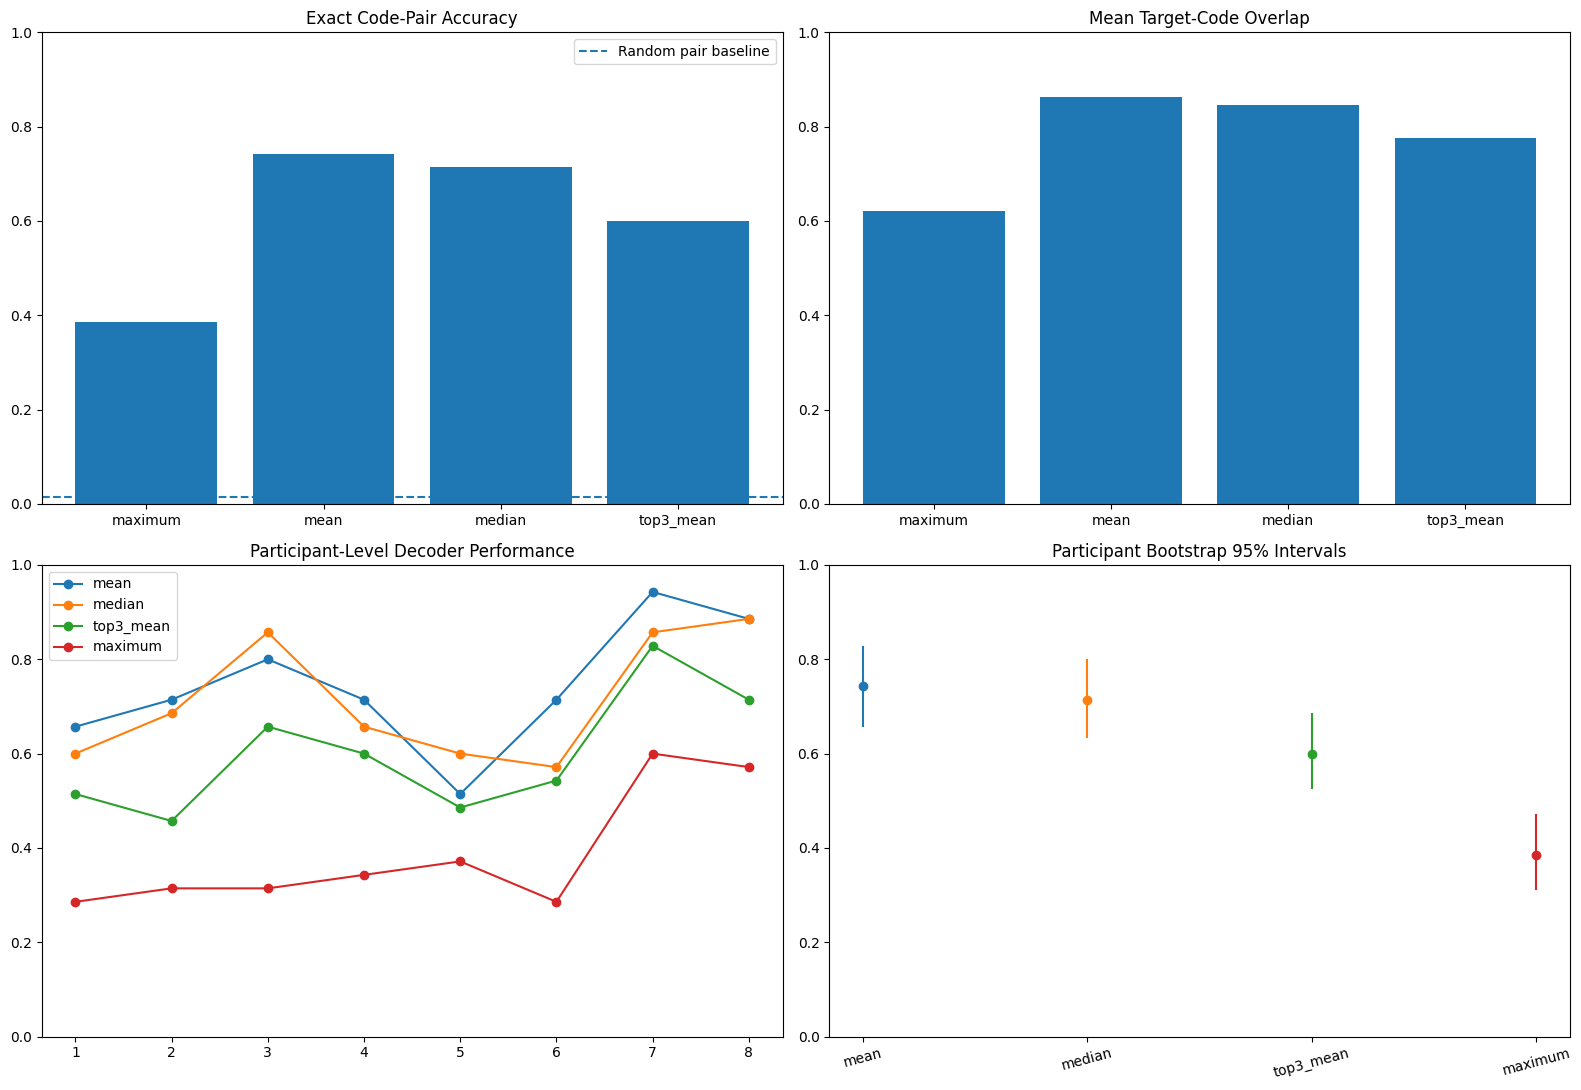


PROJECT VOICE | MODULE 4 | STAGE 5 COMPLETE
Participants: 8
Decoded trials: 280
Best aggregation: mean
Best exact pair accuracy: 74.29 %
Random pair baseline: 1.515 %
Literal character decoding: NOT CLAIMED

OUTPUT DIRECTORY: PROJECT_VOICE_MODULE_4_STAGE5

STATUS: DECODER BENCHMARK COMPLETE


In [ ]:

# =====================================================================
# PROJECT VOICE
# MODULE 4 — STAGE 5
# DECODER OPTIMISATION & RELIABILITY BENCHMARK
#
# EXPERIMENTS:
# 1. Leave-one-subject-out classification
# 2. Mean-probability aggregation
# 3. Median-probability aggregation
# 4. Top-three probability aggregation
# 5. Maximum-probability aggregation
# 6. Exact two-code selection accuracy
# 7. Code-level precision, recall and F1
# 8. Participant-level bootstrap confidence intervals
# 9. Theoretical random-pair baseline
# 10. Reproducible CSV, JSON and plot exports
#
# IMPORTANT:
# This evaluates stimulus-code pairs, not literal characters.
# =====================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

OUTPUT_DIR = "PROJECT_VOICE_MODULE_4_STAGE5"

os.makedirs(OUTPUT_DIR, exist_ok=True)

EVENTS_PER_TRIAL = 120
FLASHES_PER_TRIAL = 12
REPETITIONS_PER_FLASH = 10
TARGET_CODES_PER_TRIAL = 2

N_BOOTSTRAPS = 5000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

AGGREGATION_METHODS = [
    "mean",
    "median",
    "top3_mean",
    "maximum"
]

print("=" * 75)
print("PROJECT VOICE | MODULE 4")
print("STAGE 5: DECODER OPTIMISATION")
print("=" * 75)

# =====================================================================
# 2. VALIDATE EXISTING DATA
# =====================================================================

X_array = np.asarray(X)
y_array = np.asarray(y)
metadata_df = metadata.reset_index(drop=True).copy()

if X_array.ndim != 3:
    raise ValueError("X must have three dimensions.")

if len(X_array) != len(y_array):
    raise ValueError("X and y length mismatch.")

if len(X_array) != len(metadata_df):
    raise ValueError("X and metadata length mismatch.")

required_columns = ["subject"]

for column in required_columns:
    if column not in metadata_df.columns:
        raise ValueError(
            f"Missing metadata column: {column}"
        )

if set(map(str, np.unique(y_array))) == {
    "Target", "NonTarget"
}:

    y_binary = np.array([
        1 if str(label) == "Target" else 0
        for label in y_array
    ])

elif set(map(str, np.unique(y_array))) == {"0", "1"}:

    y_binary = y_array.astype(int)

else:
    raise ValueError(
        "Unexpected classification labels."
    )

subject_ids = sorted(
    metadata_df["subject"].unique(),
    key=lambda value: int(value)
)

print("\nDATASET VALIDATION")
print("Epochs:", len(X_array))
print("EEG channels:", X_array.shape[1])
print("Samples per epoch:", X_array.shape[2])
print("Participants:", subject_ids)

# =====================================================================
# 3. FEATURE EXTRACTION
# =====================================================================

def make_features(eeg):

    eeg = np.asarray(eeg)

    # Same temporal subsampling approach as Module 3.
    eeg_subsampled = eeg[:, :, ::4]

    return eeg_subsampled.reshape(
        len(eeg_subsampled),
        -1
    )


X_features = make_features(X_array)

print("\nFEATURES")
print("Feature matrix:", X_features.shape)

# =====================================================================
# 4. CLASSIFIER
# =====================================================================

def create_model():

    return Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "classifier",
            LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage="auto"
            )
        )

    ])


# =====================================================================
# 5. RAW FLASH EXTRACTION
# =====================================================================

def get_subject_flash_data(subject_id):

    raw_subjects = dataset.get_data(
        subjects=[int(subject_id)]
    )

    subject_key = int(subject_id)

    if subject_key not in raw_subjects:
        raise RuntimeError(
            f"Subject {subject_id} not found in raw dataset."
        )

    sessions = raw_subjects[subject_key]

    if len(sessions) != 1:
        raise RuntimeError(
            f"Unexpected session count for {subject_id}."
        )

    session = list(sessions.keys())[0]
    runs = sessions[session]

    if len(runs) != 1:
        raise RuntimeError(
            f"Unexpected run count for {subject_id}."
        )

    run_name = list(runs.keys())[0]
    subject_raw = runs[run_name]

    if "Flash stim" not in subject_raw.ch_names:
        raise RuntimeError(
            "Flash stim channel missing."
        )

    flash_signal = subject_raw.get_data(
        picks=["Flash stim"]
    )[0]

    flash_onsets = np.where(
        (flash_signal != 0) &
        (np.r_[True, flash_signal[:-1] == 0])
    )[0]

    flash_codes = flash_signal[
        flash_onsets
    ].astype(int)

    annotation_labels = np.asarray(
        subject_raw.annotations.description
    )

    annotation_binary = np.array([
        1 if str(label) == "Target" else 0
        for label in annotation_labels
    ])

    return {
        "raw": subject_raw,
        "flash_codes": flash_codes,
        "flash_onsets": flash_onsets,
        "annotation_binary": annotation_binary
    }


# =====================================================================
# 6. AGGREGATION FUNCTIONS
# =====================================================================

def aggregate_probabilities(values):

    values = np.asarray(
        values,
        dtype=float
    )

    if len(values) != REPETITIONS_PER_FLASH:
        raise ValueError(
            "Unexpected number of repetitions."
        )

    results = {

        "mean": float(
            np.mean(values)
        ),

        "median": float(
            np.median(values)
        ),

        "top3_mean": float(
            np.mean(
                np.sort(values)[-3:]
            )
        ),

        "maximum": float(
            np.max(values)
        )

    }

    return results


# =====================================================================
# 7. TRIAL-LEVEL DECODER
# =====================================================================

def decode_one_trial(
    probabilities,
    flash_codes,
    actual_labels,
    subject_id,
    trial_number
):

    unique_codes = np.sort(
        np.unique(flash_codes)
    )

    if len(unique_codes) != FLASHES_PER_TRIAL:
        raise ValueError(
            f"Trial {trial_number}: expected 12 flash codes."
        )

    score_rows = []

    for code in unique_codes:

        mask = flash_codes == code

        code_probabilities = probabilities[mask]
        code_labels = actual_labels[mask]

        if len(code_probabilities) != REPETITIONS_PER_FLASH:
            raise ValueError(
                f"Flash {code} has incorrect repetition count."
            )

        aggregated = aggregate_probabilities(
            code_probabilities
        )

        actual_target = bool(
            np.any(code_labels == 1)
        )

        score_rows.append({

            "subject": int(subject_id),

            "trial": int(trial_number),

            "flash_code": int(code),

            "actual_target": actual_target,

            "event_count": int(
                len(code_probabilities)
            ),

            **aggregated

        })

    scores = pd.DataFrame(score_rows)

    true_pair = set(
        scores.loc[
            scores["actual_target"],
            "flash_code"
        ].astype(int)
    )

    if len(true_pair) != TARGET_CODES_PER_TRIAL:
        raise ValueError(
            f"Trial {trial_number}: "
            "expected two actual target codes."
        )

    predictions = []

    for method in AGGREGATION_METHODS:

        ranked = scores.sort_values(
            method,
            ascending=False
        )

        predicted_pair = set(
            ranked.head(2)["flash_code"].astype(int)
        )

        overlap = len(
            predicted_pair.intersection(true_pair)
        )

        predictions.append({

            "subject": int(subject_id),

            "trial": int(trial_number),

            "method": method,

            "predicted_pair": sorted(
                predicted_pair
            ),

            "true_pair": sorted(
                true_pair
            ),

            "exact_match": (
                predicted_pair == true_pair
            ),

            "correct_codes": int(overlap),

            "pair_overlap": (
                overlap / TARGET_CODES_PER_TRIAL
            )

        })

    scores["subject"] = int(subject_id)
    scores["trial"] = int(trial_number)

    return predictions, scores


# =====================================================================
# 8. LEAVE-ONE-SUBJECT-OUT EXPERIMENT
# =====================================================================

all_predictions = []
all_flash_scores = []
all_classifier_metrics = []

for held_out_subject in subject_ids:

    print("\n" + "-" * 70)
    print("HELD-OUT SUBJECT:", held_out_subject)
    print("-" * 70)

    subject_values = (
        metadata_df["subject"].astype(str)
    )

    test_mask = (
        subject_values ==
        str(held_out_subject)
    ).to_numpy()

    train_mask = ~test_mask

    X_train = X_features[train_mask]
    y_train = y_binary[train_mask]

    X_test = X_features[test_mask]
    y_test = y_binary[test_mask]

    if len(np.unique(y_train)) != 2:
        raise RuntimeError(
            "Training data does not contain both classes."
        )

    model = create_model()

    model.fit(
        X_train,
        y_train
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    binary_predictions = (
        probabilities >= 0.5
    ).astype(int)

    subject_metrics = {

        "subject": int(held_out_subject),

        "accuracy": float(
            accuracy_score(
                y_test,
                binary_predictions
            )
        ),

        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_test,
                binary_predictions
            )
        ),

        "precision": float(
            precision_score(
                y_test,
                binary_predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                y_test,
                binary_predictions,
                zero_division=0
            )
        ),

        "f1": float(
            f1_score(
                y_test,
                binary_predictions,
                zero_division=0
            )
        ),

        "roc_auc": float(
            roc_auc_score(
                y_test,
                probabilities
            )
        )

    }

    all_classifier_metrics.append(
        subject_metrics
    )

    # Recover original flash identities.
    raw_info = get_subject_flash_data(
        held_out_subject
    )

    flash_codes = raw_info["flash_codes"]

    if len(flash_codes) != len(y_test):
        raise RuntimeError(
            "Flash event count does not match EEG epoch count."
        )

    if not np.array_equal(
        raw_info["annotation_binary"],
        y_test
    ):
        raise RuntimeError(
            "Raw annotation ordering differs from EEG epoch ordering."
        )

    if len(flash_codes) % EVENTS_PER_TRIAL != 0:
        raise RuntimeError(
            "Event count is not divisible by trial size."
        )

    number_of_trials = (
        len(flash_codes) // EVENTS_PER_TRIAL
    )

    print("Training epochs:", len(X_train))
    print("Testing epochs:", len(X_test))
    print("Held-out ROC-AUC:", round(
        subject_metrics["roc_auc"], 4
    ))
    print("Trials:", number_of_trials)

    # Decode every 120-event block.
    for trial_index in range(number_of_trials):

        start = (
            trial_index * EVENTS_PER_TRIAL
        )

        end = (
            start + EVENTS_PER_TRIAL
        )

        trial_codes = flash_codes[start:end]
        trial_labels = y_test[start:end]
        trial_probabilities = probabilities[start:end]

        # Check 12 codes x 10 repetitions.
        code_counts = pd.Series(
            trial_codes
        ).value_counts()

        if len(code_counts) != FLASHES_PER_TRIAL:
            raise RuntimeError(
                "Trial does not contain 12 unique flash codes."
            )

        if not np.all(
            code_counts.values == REPETITIONS_PER_FLASH
        ):
            raise RuntimeError(
                "Trial does not contain 10 repetitions per code."
            )

        predictions, scores = decode_one_trial(
            trial_probabilities,
            trial_codes,
            trial_labels,
            held_out_subject,
            trial_index + 1
        )

        all_predictions.extend(
            predictions
        )

        all_flash_scores.append(
            scores
        )

    print(
        "Completed trials:",
        number_of_trials
    )


# =====================================================================
# 9. COMBINE EXPERIMENTAL RESULTS
# =====================================================================

predictions_df = pd.DataFrame(
    all_predictions
)

flash_scores_df = pd.concat(
    all_flash_scores,
    ignore_index=True
)

classifier_metrics_df = pd.DataFrame(
    all_classifier_metrics
)

print("\n" + "=" * 75)
print("CLASSIFIER PERFORMANCE")
print("=" * 75)

print(
    classifier_metrics_df.to_string(
        index=False
    )
)

# =====================================================================
# 10. AGGREGATION STRATEGY COMPARISON
# =====================================================================

strategy_summary = (
    predictions_df.groupby("method")
    .agg(

        trials=("trial", "count"),

        exact_pair_accuracy=(
            "exact_match",
            "mean"
        ),

        mean_pair_overlap=(
            "pair_overlap",
            "mean"
        ),

        mean_correct_codes=(
            "correct_codes",
            "mean"
        )

    )
    .reset_index()
)

strategy_summary[
    "exact_pair_accuracy_percent"
] = (
    strategy_summary["exact_pair_accuracy"] * 100
)

strategy_summary[
    "mean_pair_overlap_percent"
] = (
    strategy_summary["mean_pair_overlap"] * 100
)

print("\nAGGREGATION COMPARISON")

print(
    strategy_summary.to_string(
        index=False
    )
)

# =====================================================================
# 11. PARTICIPANT-LEVEL PERFORMANCE
# =====================================================================

participant_summary = (
    predictions_df.groupby(
        ["subject", "method"]
    )
    .agg(

        trials=("trial", "count"),

        exact_pair_accuracy=(
            "exact_match",
            "mean"
        ),

        mean_pair_overlap=(
            "pair_overlap",
            "mean"
        )

    )
    .reset_index()
)

print("\nPARTICIPANT-LEVEL PERFORMANCE")

print(
    participant_summary.to_string(
        index=False
    )
)

# =====================================================================
# 12. CODE-LEVEL PRECISION / RECALL
# =====================================================================


# ============================================================
# 12. CORRECTED CODE-LEVEL MULTILABEL PERFORMANCE
# ============================================================

code_metrics = []

FLASH_LABELS = np.arange(3, 15)

for method in AGGREGATION_METHODS:

    subset = predictions_df[
        predictions_df["method"] == method
    ]

    y_true_multi = []
    y_pred_multi = []

    for _, row in subset.iterrows():

        true_pair = set(row["true_pair"])
        predicted_pair = set(row["predicted_pair"])

        y_true_multi.append([
            int(code in true_pair)
            for code in FLASH_LABELS
        ])

        y_pred_multi.append([
            int(code in predicted_pair)
            for code in FLASH_LABELS
        ])

    y_true_multi = np.asarray(y_true_multi)
    y_pred_multi = np.asarray(y_pred_multi)

    code_metrics.append({

        "method": method,

        "macro_precision": precision_score(
            y_true_multi,
            y_pred_multi,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true_multi,
            y_pred_multi,
            average="macro",
            zero_division=0
        ),

        "macro_f1": f1_score(
            y_true_multi,
            y_pred_multi,
            average="macro",
            zero_division=0
        )

    })

code_metrics_df = pd.DataFrame(code_metrics)

print("\nCORRECTED CODE-LEVEL MULTILABEL PERFORMANCE")
display(code_metrics_df)

# =====================================================================
# 12. CODE-LEVEL PRECISION / RECALL — CORRECTED
# =====================================================================




    # Each stimulus code is a multiclass lab averaging calculates metrics independently per code
    #
# =====================================================================
# 13. PARTICIPANT-LEVEL BOOTSTRAP CONFIDENCE INTERVALS
# =====================================================================

bootstrap_records = []

for method in AGGREGATION_METHODS:

    method_data = participant_summary[
        participant_summary["method"] == method
    ]

    participant_values = (
        method_data["exact_pair_accuracy"].to_numpy()
    )

    bootstrap_means = []

    for _ in range(N_BOOTSTRAPS):

        sampled = rng.choice(
            participant_values,
            size=len(participant_values),
            replace=True
        )

        bootstrap_means.append(
            np.mean(sampled)
        )

    lower = float(
        np.percentile(
            bootstrap_means,
            2.5
        )
    )

    upper = float(
        np.percentile(
            bootstrap_means,
            97.5
        )
    )

    bootstrap_records.append({

        "method": method,

        "participant_mean_accuracy": float(
            np.mean(participant_values)
        ),

        "ci_95_lower": lower,

        "ci_95_upper": upper

    })


bootstrap_df = pd.DataFrame(
    bootstrap_records
)

print("\nPARTICIPANT-LEVEL BOOTSTRAP INTERVALS")

print(
    bootstrap_df.to_string(
        index=False
    )
)

# =====================================================================
# 14. RANDOM-PAIR BASELINE
# =====================================================================

# There are 12 possible stimulus codes.
# Selecting exactly 2 without replacement gives 66 possible pairs.
#
# If there is exactly one correct pair, the theoretical random
# exact-pair probability is 1/66.

number_of_possible_pairs = (
    FLASHES_PER_TRIAL *
    (FLASHES_PER_TRIAL - 1) // 2
)

random_pair_accuracy = (
    1 / number_of_possible_pairs
)

print("\nRANDOM BASELINE")

print(
    "Possible two-code pairs:",
    number_of_possible_pairs
)

print(
    "Theoretical random exact-pair accuracy:",
    round(
        random_pair_accuracy * 100,
        3
    ),
    "%"
)

# =====================================================================
# 15. BEST AGGREGATION METHOD
# =====================================================================

best_strategy = strategy_summary.sort_values(
    ["exact_pair_accuracy", "mean_pair_overlap"],
    ascending=False
).iloc[0]

best_method = str(
    best_strategy["method"]
)

print("\nBEST AGGREGATION METHOD")

print("Method:", best_method)

print(
    "Exact pair accuracy:",
    round(
        best_strategy["exact_pair_accuracy"] * 100,
        2
    ),
    "%"
)

print(
    "Mean overlap:",
    round(
        best_strategy["mean_pair_overlap"] * 100,
        2
    ),
    "%"
)

# =====================================================================
# 16. VISUALIZATION
# =====================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

# A. Aggregation strategy accuracy
axes[0, 0].bar(
    strategy_summary["method"],
    strategy_summary["exact_pair_accuracy"]
)

axes[0, 0].axhline(
    random_pair_accuracy,
    linestyle="--",
    label="Random pair baseline"
)

axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_title(
    "Exact Code-Pair Accuracy"
)

axes[0, 0].legend()

# B. Mean overlap
axes[0, 1].bar(
    strategy_summary["method"],
    strategy_summary["mean_pair_overlap"]
)

axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_title(
    "Mean Target-Code Overlap"
)

# C. Participant-level accuracy
for method in AGGREGATION_METHODS:

    subset = participant_summary[
        participant_summary["method"] == method
    ]

    axes[1, 0].plot(
        subset["subject"].astype(str),
        subset["exact_pair_accuracy"],
        marker="o",
        label=method
    )

axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_title(
    "Participant-Level Decoder Performance"
)

axes[1, 0].legend()

# D. Confidence intervals
for index, row in bootstrap_df.iterrows():

    axes[1, 1].errorbar(
        x=index,

        y=row["participant_mean_accuracy"],

        yerr=[[
            row["participant_mean_accuracy"] -
            row["ci_95_lower"]
        ], [
            row["ci_95_upper"] -
            row["participant_mean_accuracy"]
        ]],

        fmt="o"
    )

axes[1, 1].set_xticks(
    range(len(bootstrap_df))
)

axes[1, 1].set_xticklabels(
    bootstrap_df["method"],
    rotation=15
)

axes[1, 1].set_ylim(0, 1)

axes[1, 1].set_title(
    "Participant Bootstrap 95% Intervals"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "stage5_aggregation_benchmark.png"
    ),
    dpi=180
)

plt.show()

# =====================================================================
# 17. EXPORT RESULTS
# =====================================================================

predictions_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "all_trial_predictions.csv"
    ),
    index=False
)

flash_scores_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "all_flash_aggregation_scores.csv"
    ),
    index=False
)

classifier_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "classifier_metrics.csv"
    ),
    index=False
)

strategy_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "aggregation_strategy_comparison.csv"
    ),
    index=False
)

participant_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "participant_level_performance.csv"
    ),
    index=False
)

code_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "code_level_metrics.csv"
    ),
    index=False
)

bootstrap_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "bootstrap_confidence_intervals.csv"
    ),
    index=False
)

# =====================================================================
# 18. FINAL REPORT
# =====================================================================

final_report = {

    "project": "PROJECT VOICE",

    "module": 4,

    "stage": 5,

    "experiment": (
        "Leave-One-Subject-Out "
        "Aggregation Strategy Benchmark"
    ),

    "participants": [
        int(value) for value in subject_ids
    ],

    "events_per_trial": EVENTS_PER_TRIAL,

    "flash_codes_per_trial": FLASHES_PER_TRIAL,

    "repetitions_per_flash": REPETITIONS_PER_FLASH,

    "decoded_trial_count": int(
        len(predictions_df) /
        len(AGGREGATION_METHODS)
    ),

    "aggregation_methods": AGGREGATION_METHODS,

    "best_method": best_method,

    "best_exact_pair_accuracy": float(
        best_strategy["exact_pair_accuracy"]
    ),

    "best_mean_pair_overlap": float(
        best_strategy["mean_pair_overlap"]
    ),

    "random_pair_baseline": float(
        random_pair_accuracy
    ),

    "bootstrap_confidence_intervals": (
        bootstrap_df.to_dict(
            orient="records"
        )
    ),

    "literal_character_mapping_established": False,

    "literal_character_accuracy_claimed": False

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "stage5_final_report.json"
    ),
    "w"
) as file:

    json.dump(
        final_report,
        file,
        indent=4
    )

# =====================================================================
# 19. COMPLETION
# =====================================================================

print("\n" + "=" * 75)
print("PROJECT VOICE | MODULE 4 | STAGE 5 COMPLETE")
print("=" * 75)

print("Participants:", len(subject_ids))

print(
    "Decoded trials:",
    final_report["decoded_trial_count"]
)

print(
    "Best aggregation:",
    best_method
)

print(
    "Best exact pair accuracy:",
    round(
        final_report["best_exact_pair_accuracy"] * 100,
        2
    ),
    "%"
)

print(
    "Random pair baseline:",
    round(
        random_pair_accuracy * 100,
        3
    ),
    "%"
)

print(
    "Literal character decoding:",
    "NOT CLAIMED"
)

print("\nOUTPUT DIRECTORY:", OUTPUT_DIR)

print("\nSTATUS: DECODER BENCHMARK COMPLETE")


In [ ]:

print("PROJECT VOICE — MODULE 4 — STAGE 5 FINAL RESULTS")

print("\n1. CLASSIFIER RESULTS")
display(classifier_metrics_df)

print("\n2. DECODER COMPARISON")
display(strategy_summary)

print("\n3. PARTICIPANT PERFORMANCE")
display(participant_summary)

print("\n4. CODE-LEVEL METRICS")
display(code_metrics_df)

print("\n5. BOOTSTRAP INTERVALS")
display(bootstrap_df)

print("\n6. BEST DECODER")
print("Method:", best_method)
print("Exact pair accuracy:",
      round(best_strategy["exact_pair_accuracy"] * 100, 2), "%")
print("Mean overlap:",
      round(best_strategy["mean_pair_overlap"] * 100, 2), "%")

print("\n7. TOTAL DECODED TRIALS")
print(predictions_df["trial"].count() // 4)


PROJECT VOICE — MODULE 4 — STAGE 5 FINAL RESULTS

1. CLASSIFIER RESULTS


,subject,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,1,0.830000,0.540286,0.456790,0.105714,0.171694,0.768463
1,2,0.836429,0.604714,0.518732,0.257143,0.343840,0.757194
2,3,0.849286,0.635286,0.589812,0.314286,0.410065,0.836468
3,4,0.813095,0.660429,0.438316,0.431429,0.434845,0.742267
4,5,0.838095,0.540000,0.590909,0.092857,0.160494,0.748707
5,6,0.839762,0.549000,0.603053,0.112857,0.190132,0.768064
6,7,0.856905,0.632429,0.657143,0.295714,0.407882,0.811510
7,8,0.851905,0.568857,0.814516,0.144286,0.245146,0.843713



2. DECODER COMPARISON


,method,trials,exact_pair_accuracy,mean_pair_overlap,mean_correct_codes,exact_pair_accuracy_percent,mean_pair_overlap_percent
0,maximum,280,0.385714,0.621429,1.242857,38.571429,62.142857
1,mean,280,0.742857,0.862500,1.725000,74.285714,86.250000
2,median,280,0.714286,0.846429,1.692857,71.428571,84.642857
3,top3_mean,280,0.600000,0.776786,1.553571,60.000000,77.678571



3. PARTICIPANT PERFORMANCE


,subject,method,trials,exact_pair_accuracy,mean_pair_overlap
0,1,maximum,35,0.285714,0.557143
1,1,mean,35,0.657143,0.828571
2,1,median,35,0.600000,0.800000
3,1,top3_mean,35,0.514286,0.728571
4,2,maximum,35,0.314286,0.514286
5,2,mean,35,0.714286,0.857143
6,2,median,35,0.685714,0.842857
7,2,top3_mean,35,0.457143,0.714286
8,3,maximum,35,0.314286,0.585714
9,3,mean,35,0.800000,0.900000



4. CODE-LEVEL METRICS


,method,macro_precision,macro_recall,macro_f1
0,mean,0.825593,0.830288,0.820753
1,median,0.809807,0.811901,0.807344
2,top3_mean,0.735918,0.770288,0.743506
3,maximum,0.578080,0.598690,0.580178



5. BOOTSTRAP INTERVALS


,method,participant_mean_accuracy,ci_95_lower,ci_95_upper
0,mean,0.742857,0.657143,0.828571
1,median,0.714286,0.632143,0.800000
2,top3_mean,0.600000,0.525000,0.685714
3,maximum,0.385714,0.310714,0.471429



6. BEST DECODER
Method: mean
Exact pair accuracy: 74.29 %
Mean overlap: 86.25 %

7. TOTAL DECODED TRIALS
280


PROJECT VOICE | MODULE 4 | STAGE 6
SUBJECT CALIBRATION AND ADAPTIVE DECODER

DATA VALIDATION
Epochs: 33600
EEG channels: 8
Samples per epoch: 257
Participants: 8
Subjects: [1, 2, 3, 4, 5, 6, 7, 8]
Detected label format: Numeric
Binary labels: [0 1]
NonTarget: 28000
Target: 5600

FEATURE MATRIX
Original EEG shape: (33600, 8, 257)
Feature matrix: (33600, 520)

SUBJECT INDEXING COMPLETE
Subject 1: 4200 epochs
Subject 2: 4200 epochs
Subject 3: 4200 epochs
Subject 4: 4200 epochs
Subject 5: 4200 epochs
Subject 6: 4200 epochs
Subject 7: 4200 epochs
Subject 8: 4200 epochs

RECONSTRUCTING FLASH EVENTS

Validating subject 1...

Validating subject 2...

Validating subject 3...

Validating subject 4...

Validating subject 5...

Validating subject 6...

Validating subject 7...

Validating subject 8...

FLASH VALIDATION COMPLETE
All 8 participants validated.
All 280 trials have valid stimulus structures.

STARTING CALIBRATION EXPERIMENT

-------------------------------------------------------
HELD-O

,subject,trial,predicted_pair,true_pair,exact_pair_accuracy,pair_overlap,correct_codes,calibration_trials,model_type
0,1,0,"[7, 12]","[7, 12]",1,1.0,2,0,baseline
1,1,1,"[3, 10]","[3, 10]",1,1.0,2,0,baseline
2,1,2,"[3, 9]","[3, 9]",1,1.0,2,0,baseline
3,1,3,"[3, 11]","[3, 11]",1,1.0,2,0,baseline
4,1,4,"[4, 11]","[4, 11]",1,1.0,2,0,baseline



STAGE 6 OVERALL RESULTS


,calibration_trials,model_type,total_trials,exact_pair_accuracy,mean_pair_overlap,mean_correct_codes
0,0,baseline,280,0.742857,0.86250,1.7250
1,5,baseline_comparison,240,0.745833,0.86875,1.7375
2,5,calibrated,240,0.758333,0.87500,1.7500
3,10,baseline_comparison,200,0.745000,0.87250,1.7450
4,10,calibrated,200,0.785000,0.89250,1.7850



PARTICIPANT-LEVEL RESULTS


,subject,calibration_trials,model_type,trials,exact_pair_accuracy,mean_pair_overlap
0,1,0,baseline,35,0.657143,0.828571
1,2,0,baseline,35,0.714286,0.857143
2,3,0,baseline,35,0.800000,0.900000
3,4,0,baseline,35,0.714286,0.800000
4,5,0,baseline,35,0.514286,0.757143
5,6,0,baseline,35,0.714286,0.842857
6,7,0,baseline,35,0.942857,0.971429
7,8,0,baseline,35,0.885714,0.942857
8,1,5,baseline_comparison,30,0.600000,0.800000
9,2,5,baseline_comparison,30,0.700000,0.850000



PARTICIPANT-LEVEL CALIBRATION IMPROVEMENTS


,subject,calibration_trials,baseline_accuracy,calibrated_accuracy,improvement_percentage_points
0,1,5,0.600000,0.633333,3.333333
1,2,5,0.700000,0.733333,3.333333
2,3,5,0.800000,0.833333,3.333333
3,4,5,0.800000,0.800000,0.000000
4,5,5,0.566667,0.566667,0.000000
5,6,5,0.700000,0.700000,0.000000
6,7,5,0.933333,0.933333,0.000000
7,8,5,0.866667,0.866667,0.000000
8,1,10,0.600000,0.640000,4.000000
9,2,10,0.680000,0.760000,8.000000



BOOTSTRAP CONFIDENCE INTERVALS


,calibration_trials,mean_improvement_pp,ci_95_lower_pp,ci_95_upper_pp
0,5,1.25,0.416667,1.78125
1,10,4.00,2.000000,6.13750


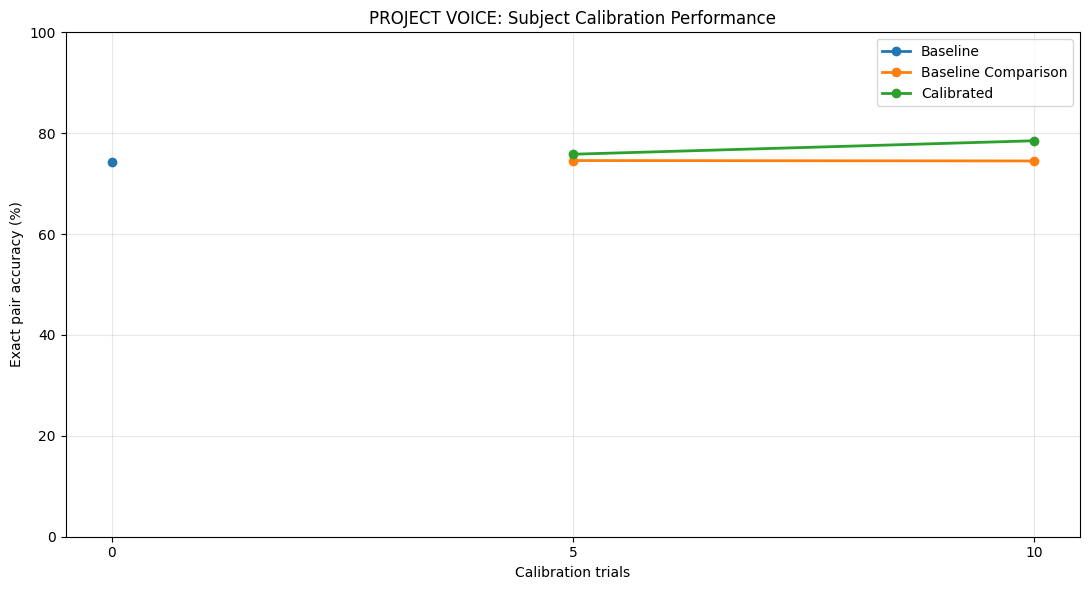

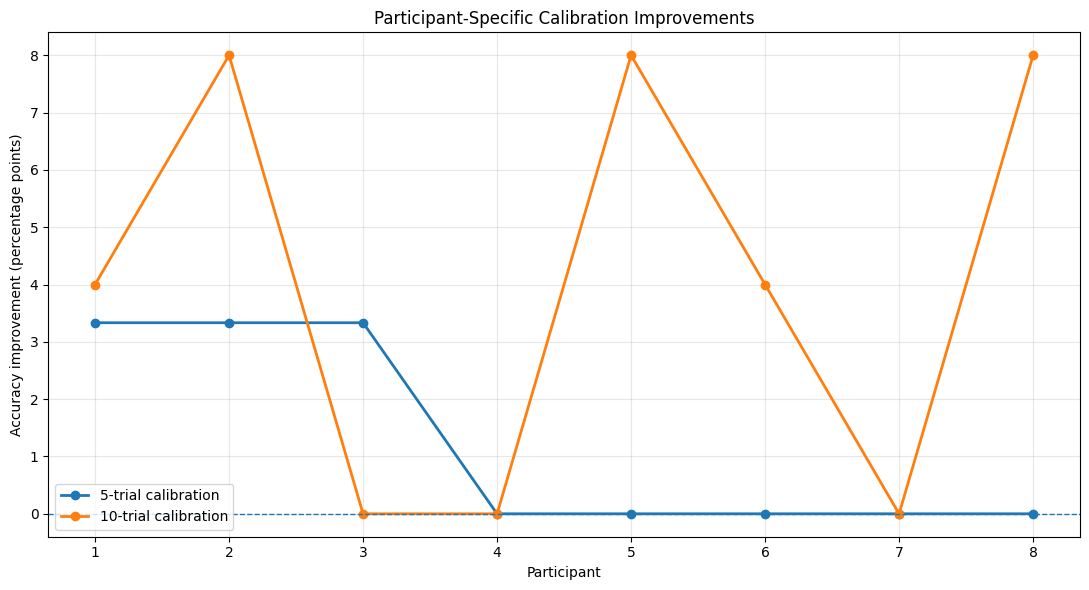


PROJECT VOICE — MODULE 4 — STAGE 6 COMPLETE

1. CALIBRATION SUMMARY


,calibration_trials,model_type,total_trials,exact_pair_accuracy,mean_pair_overlap,mean_correct_codes
0,0,baseline,280,0.742857,0.86250,1.7250
1,5,baseline_comparison,240,0.745833,0.86875,1.7375
2,5,calibrated,240,0.758333,0.87500,1.7500
3,10,baseline_comparison,200,0.745000,0.87250,1.7450
4,10,calibrated,200,0.785000,0.89250,1.7850



2. PARTICIPANT RESULTS


,subject,calibration_trials,model_type,trials,exact_pair_accuracy,mean_pair_overlap
0,1,0,baseline,35,0.657143,0.828571
1,2,0,baseline,35,0.714286,0.857143
2,3,0,baseline,35,0.800000,0.900000
3,4,0,baseline,35,0.714286,0.800000
4,5,0,baseline,35,0.514286,0.757143
5,6,0,baseline,35,0.714286,0.842857
6,7,0,baseline,35,0.942857,0.971429
7,8,0,baseline,35,0.885714,0.942857
8,1,5,baseline_comparison,30,0.600000,0.800000
9,2,5,baseline_comparison,30,0.700000,0.850000



3. CALIBRATION IMPROVEMENTS


,subject,calibration_trials,baseline_accuracy,calibrated_accuracy,improvement_percentage_points
0,1,5,0.600000,0.633333,3.333333
1,2,5,0.700000,0.733333,3.333333
2,3,5,0.800000,0.833333,3.333333
3,4,5,0.800000,0.800000,0.000000
4,5,5,0.566667,0.566667,0.000000
5,6,5,0.700000,0.700000,0.000000
6,7,5,0.933333,0.933333,0.000000
7,8,5,0.866667,0.866667,0.000000
8,1,10,0.600000,0.640000,4.000000
9,2,10,0.680000,0.760000,8.000000



4. BOOTSTRAP INTERVALS


,calibration_trials,mean_improvement_pp,ci_95_lower_pp,ci_95_upper_pp
0,5,1.25,0.416667,1.78125
1,10,4.00,2.000000,6.13750



5. OUTPUT FILES
PROJECT_VOICE_MODULE_4_STAGE6

EXPERIMENTAL STATUS: COMPLETED
Interpretation requires review of the results.


In [ ]:

# ============================================================
# PROJECT VOICE | MODULE 4 | STAGE 6
# SUBJECT CALIBRATION AND ADAPTIVE DECODER
#
# OBJECTIVES:
# 1. Establish zero-calibration baseline
# 2. Test 5-trial subject calibration
# 3. Test 10-trial subject calibration
# 4. Compare calibrated and uncalibrated models
# 5. Evaluate exact stimulus-code pair accuracy
# 6. Calculate participant-level improvements
# 7. Bootstrap confidence intervals
#
# LABEL FORMAT:
# Original MOABB labels: "NonTarget", "Target"
# Binary labels:         0, 1
#
# EVALUATION:
# Stimulus-code pairs, NOT literal characters.
# ============================================================


# -------------------- 1. IMPORTS -----------------------------

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from IPython.display import display

warnings.filterwarnings("ignore")


print("=" * 65)
print("PROJECT VOICE | MODULE 4 | STAGE 6")
print("SUBJECT CALIBRATION AND ADAPTIVE DECODER")
print("=" * 65)


# -------------------- 2. CONFIGURATION -----------------------

CALIBRATION_TRIALS = [0, 5, 10]

TRIALS_PER_SUBJECT = 35
EVENTS_PER_TRIAL = 120

FLASH_CODES = np.arange(3, 15)

# Reduced from 5000 for faster execution.
N_BOOTSTRAPS = 30

RANDOM_STATE = 42

OUTPUT_DIR = "PROJECT_VOICE_MODULE_4_STAGE6"

os.makedirs(OUTPUT_DIR, exist_ok=True)

rng = np.random.default_rng(RANDOM_STATE)


# -------------------- 3. DATA VALIDATION ---------------------

assert "X" in globals(), "X is missing."
assert "y" in globals(), "y is missing."
assert "metadata" in globals(), "metadata is missing."
assert "dataset" in globals(), "dataset is missing."

assert X.shape[0] == len(y)
assert len(metadata) == len(y)
assert X.ndim == 3
assert "subject" in metadata.columns
assert len(X) == 33600

# Accept either numeric or original MOABB text labels.
original_labels = set(np.unique(y))

if original_labels == {0, 1}:
    y_array = np.asarray(y).astype(int)
    label_format = "Numeric"

elif original_labels == {"NonTarget", "Target"}:
    label_mapping = {
        "NonTarget": 0,
        "Target": 1
    }

    y_array = np.array(
        [label_mapping[label] for label in y],
        dtype=int
    )

    label_format = "Original MOABB text"

elif original_labels == {"0", "1"}:
    y_array = np.asarray(y).astype(int)
    label_format = "Numeric strings"

else:
    raise ValueError(
        f"Unexpected labels: {original_labels}. "
        "Expected {0, 1} or {'NonTarget', 'Target'}."
    )

assert set(np.unique(y_array)) == {0, 1}

# Normalize subject IDs to integers.
metadata_subjects = pd.to_numeric(
    metadata["subject"],
    errors="raise"
).astype(int).to_numpy()

subjects = sorted(np.unique(metadata_subjects).tolist())

assert len(subjects) == 8, (
    f"Expected 8 subjects, found {len(subjects)}."
)

assert np.all(np.isin(subjects, np.arange(1, 9))), (
    f"Unexpected subject IDs: {subjects}"
)

print("\nDATA VALIDATION")
print("Epochs:", len(X))
print("EEG channels:", X.shape[1])
print("Samples per epoch:", X.shape[2])
print("Participants:", len(subjects))
print("Subjects:", subjects)
print("Detected label format:", label_format)
print("Binary labels:", np.unique(y_array))
print("NonTarget:", int(np.sum(y_array == 0)))
print("Target:", int(np.sum(y_array == 1)))


# -------------------- 4. FEATURE EXTRACTION ------------------

X_features = X[:, :, ::4].reshape(len(X), -1)

print("\nFEATURE MATRIX")
print("Original EEG shape:", X.shape)
print("Feature matrix:", X_features.shape)

assert X_features.shape[0] == len(y_array)


# -------------------- 5. SUBJECT INDEXING --------------------

subject_indices = {}

for subject_id in subjects:

    indices = np.flatnonzero(
        metadata_subjects == subject_id
    )

    assert len(indices) == 4200, (
        f"Subject {subject_id}: expected 4200 epochs, "
        f"found {len(indices)}."
    )

    subject_indices[subject_id] = indices

print("\nSUBJECT INDEXING COMPLETE")
for subject_id in subjects:
    print(
        f"Subject {subject_id}: "
        f"{len(subject_indices[subject_id])} epochs"
    )


# -------------------- 6. RECONSTRUCT FLASH CODES -------------

subject_flash_codes = {}
subject_labels = {}

print("\nRECONSTRUCTING FLASH EVENTS")

for subject_id in subjects:

    print(f"\nValidating subject {subject_id}...")

    # Retrieve original raw recording.
    subject_data = dataset.get_data(
        subjects=[subject_id]
    )

    assert subject_id in subject_data, (
        f"Subject {subject_id} missing from raw dataset."
    )

    # Navigate subject -> session -> run -> Raw.
    session_data = next(
        iter(subject_data[subject_id].values())
    )

    raw_obj = next(
        iter(session_data.values())
    )

    # Retrieve flash stimulus channel.
    flash_signal = raw_obj.get_data(
        picks=["Flash stim"]
    )[0]

    previous_signal = np.r_[
        0,
        flash_signal[:-1]
    ]

    flash_onsets = np.flatnonzero(
        (flash_signal != 0) &
        (previous_signal == 0)
    )

    flash_codes = flash_signal[
        flash_onsets
    ].astype(int)

    assert len(flash_codes) == 4200, (
        f"Subject {subject_id}: expected 4200 flash events, "
        f"found {len(flash_codes)}."
    )

    # Retrieve annotation labels.
    annotation_descriptions = list(
        raw_obj.annotations.description
    )

    assert len(annotation_descriptions) == 4200, (
        f"Subject {subject_id}: expected 4200 annotations, "
        f"found {len(annotation_descriptions)}."
    )

    annotation_labels = np.array([
        1 if str(description).lower() == "target"
        else 0 if str(description).lower() == "nontarget"
        else -1
        for description in annotation_descriptions
    ])

    assert np.all(annotation_labels != -1), (
        f"Subject {subject_id}: unexpected annotation labels."
    )

    subject_y = y_array[
        subject_indices[subject_id]
    ]

    # Verify annotation ordering against MOABB labels.
    assert np.array_equal(
        annotation_labels,
        subject_y
    ), (
        f"Subject {subject_id}: annotation/label order mismatch."
    )

    # Validate 35 trials and 120 events per trial.
    for trial in range(TRIALS_PER_SUBJECT):

        start = trial * EVENTS_PER_TRIAL
        end = start + EVENTS_PER_TRIAL

        trial_codes = flash_codes[start:end]
        trial_labels = subject_y[start:end]

        assert len(trial_codes) == EVENTS_PER_TRIAL

        assert set(np.unique(trial_codes)) == set(FLASH_CODES), (
            f"Subject {subject_id}, trial {trial}: "
            "unexpected flash codes."
        )

        code_counts = pd.Series(
            trial_codes
        ).value_counts()

        assert all(
            code_counts.get(code, 0) == 10
            for code in FLASH_CODES
        ), (
            f"Subject {subject_id}, trial {trial}: "
            "flash repetition mismatch."
        )

        true_pair = set(
            trial_codes[trial_labels == 1]
        )

        assert len(true_pair) == 2, (
            f"Subject {subject_id}, trial {trial}: "
            "expected exactly two target codes."
        )

    subject_flash_codes[subject_id] = flash_codes
    subject_labels[subject_id] = subject_y

print("\nFLASH VALIDATION COMPLETE")
print("All 8 participants validated.")
print("All 280 trials have valid stimulus structures.")


# -------------------- 7. CLASSIFIER --------------------------

def build_classifier():

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "lda",
            LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage="auto"
            )
        )
    ])


# -------------------- 8. TRIAL DECODER -----------------------

def decode_trials(model, subject_id, trial_numbers):

    indices = subject_indices[subject_id]
    flash_codes = subject_flash_codes[subject_id]
    labels = subject_labels[subject_id]

    records = []

    positive_class_index = list(
        model.classes_
    ).index(1)

    for trial in trial_numbers:

        start = trial * EVENTS_PER_TRIAL
        end = start + EVENTS_PER_TRIAL

        global_trial_indices = indices[start:end]

        trial_codes = flash_codes[start:end]
        trial_labels = labels[start:end]

        probabilities = model.predict_proba(
            X_features[global_trial_indices]
        )

        target_probabilities = probabilities[
            :, positive_class_index
        ]

        # Average probability across 10 repetitions.
        code_scores = {}

        for code in FLASH_CODES:

            mask = trial_codes == code

            assert mask.sum() == 10

            code_scores[int(code)] = float(
                np.mean(target_probabilities[mask])
            )

        predicted_pair = set(
            sorted(
                code_scores,
                key=lambda code: code_scores[code],
                reverse=True
            )[:2]
        )

        true_pair = set(
            trial_codes[trial_labels == 1].tolist()
        )

        assert len(true_pair) == 2

        overlap = len(
            predicted_pair.intersection(true_pair)
        )

        records.append({

            "subject": int(subject_id),
            "trial": int(trial),

            "predicted_pair": sorted(predicted_pair),
            "true_pair": sorted(true_pair),

            "exact_pair_accuracy": int(
                predicted_pair == true_pair
            ),

            "pair_overlap": overlap / 2,
            "correct_codes": overlap

        })

    return records


# -------------------- 9. CALIBRATION EXPERIMENT --------------

all_predictions = []

print("\nSTARTING CALIBRATION EXPERIMENT")

for subject_id in subjects:

    print("\n" + "-" * 55)
    print("HELD-OUT SUBJECT:", subject_id)
    print("-" * 55)

    heldout_indices = subject_indices[subject_id]

    other_subjects = [
        s for s in subjects
        if s != subject_id
    ]

    other_indices = np.concatenate([
        subject_indices[s]
        for s in other_subjects
    ])

    # ZERO-CALIBRATION MODEL.
    baseline_model = build_classifier()

    baseline_model.fit(
        X_features[other_indices],
        y_array[other_indices]
    )

    print("Baseline model trained.")

    # Evaluate baseline across all 35 trials.
    baseline_records = decode_trials(
        baseline_model,
        subject_id,
        range(0, TRIALS_PER_SUBJECT)
    )

    for record in baseline_records:
        record["calibration_trials"] = 0
        record["model_type"] = "baseline"

    all_predictions.extend(baseline_records)

    # FIVE-TRIAL AND TEN-TRIAL CALIBRATION.
    for calibration_count in [5, 10]:

        print(
            f"\nTesting {calibration_count}-trial calibration..."
        )

        calibration_end = (
            calibration_count * EVENTS_PER_TRIAL
        )

        calibration_indices = heldout_indices[
            :calibration_end
        ]

        evaluation_trials = range(
            calibration_count,
            TRIALS_PER_SUBJECT
        )

        adapted_training_indices = np.concatenate([
            other_indices,
            calibration_indices
        ])

        adapted_model = build_classifier()

        adapted_model.fit(
            X_features[adapted_training_indices],
            y_array[adapted_training_indices]
        )

        # Both models evaluated on identical unseen trials.
        baseline_comparison_records = decode_trials(
            baseline_model,
            subject_id,
            evaluation_trials
        )

        adapted_records = decode_trials(
            adapted_model,
            subject_id,
            evaluation_trials
        )

        for record in baseline_comparison_records:
            record["calibration_trials"] = calibration_count
            record["model_type"] = "baseline_comparison"

        for record in adapted_records:
            record["calibration_trials"] = calibration_count
            record["model_type"] = "calibrated"

        all_predictions.extend(
            baseline_comparison_records
        )

        all_predictions.extend(
            adapted_records
        )

        baseline_accuracy = np.mean([
            r["exact_pair_accuracy"]
            for r in baseline_comparison_records
        ])

        adapted_accuracy = np.mean([
            r["exact_pair_accuracy"]
            for r in adapted_records
        ])

        print(
            "Baseline:",
            round(baseline_accuracy * 100, 2),
            "%"
        )

        print(
            "Calibrated:",
            round(adapted_accuracy * 100, 2),
            "%"
        )

        print(
            "Difference:",
            round(
                (adapted_accuracy - baseline_accuracy) * 100,
                2
            ),
            "percentage points"
        )


# -------------------- 10. PREDICTION TABLE -------------------

stage6_predictions_df = pd.DataFrame(
    all_predictions
)

print("\nPREDICTIONS GENERATED")
print("Total evaluation records:", len(stage6_predictions_df))

display(stage6_predictions_df.head())


# -------------------- 11. SUMMARY METRICS -------------------

summary_rows = []

for calibration_count in [0, 5, 10]:

    if calibration_count == 0:
        model_types = ["baseline"]
    else:
        model_types = [
            "baseline_comparison",
            "calibrated"
        ]

    for model_type in model_types:

        model_subset = stage6_predictions_df[
            (stage6_predictions_df["calibration_trials"]
             == calibration_count) &
            (stage6_predictions_df["model_type"]
             == model_type)
        ]

        summary_rows.append({

            "calibration_trials": calibration_count,
            "model_type": model_type,
            "total_trials": len(model_subset),

            "exact_pair_accuracy":
                model_subset["exact_pair_accuracy"].mean(),

            "mean_pair_overlap":
                model_subset["pair_overlap"].mean(),

            "mean_correct_codes":
                model_subset["correct_codes"].mean()

        })

stage6_summary_df = pd.DataFrame(summary_rows)

print("\nSTAGE 6 OVERALL RESULTS")
display(stage6_summary_df)


# -------------------- 12. PARTICIPANT RESULTS ----------------

participant_rows = []

for calibration_count in [0, 5, 10]:

    model_types = (
        ["baseline"]
        if calibration_count == 0
        else ["baseline_comparison", "calibrated"]
    )

    for model_type in model_types:

        subset = stage6_predictions_df[
            (stage6_predictions_df["calibration_trials"]
             == calibration_count) &
            (stage6_predictions_df["model_type"]
             == model_type)
        ]

        for subject_id, group in subset.groupby("subject"):

            participant_rows.append({

                "subject": int(subject_id),
                "calibration_trials": calibration_count,
                "model_type": model_type,
                "trials": len(group),

                "exact_pair_accuracy":
                    group["exact_pair_accuracy"].mean(),

                "mean_pair_overlap":
                    group["pair_overlap"].mean()

            })

stage6_participant_df = pd.DataFrame(
    participant_rows
)

print("\nPARTICIPANT-LEVEL RESULTS")
display(stage6_participant_df)


# -------------------- 13. PAIRED IMPROVEMENTS ----------------

improvement_rows = []

for calibration_count in [5, 10]:

    baseline = stage6_participant_df[
        (stage6_participant_df["calibration_trials"]
         == calibration_count) &
        (stage6_participant_df["model_type"]
         == "baseline_comparison")
    ]

    calibrated = stage6_participant_df[
        (stage6_participant_df["calibration_trials"]
         == calibration_count) &
        (stage6_participant_df["model_type"]
         == "calibrated")
    ]

    merged = baseline.merge(
        calibrated,
        on="subject",
        suffixes=("_baseline", "_calibrated")
    )

    for _, row in merged.iterrows():

        improvement_rows.append({

            "subject": int(row["subject"]),
            "calibration_trials": calibration_count,

            "baseline_accuracy":
                row["exact_pair_accuracy_baseline"],

            "calibrated_accuracy":
                row["exact_pair_accuracy_calibrated"],

            "improvement_percentage_points": (
                row["exact_pair_accuracy_calibrated"]
                - row["exact_pair_accuracy_baseline"]
            ) * 100

        })

stage6_improvements_df = pd.DataFrame(
    improvement_rows
)

print("\nPARTICIPANT-LEVEL CALIBRATION IMPROVEMENTS")
display(stage6_improvements_df)


# -------------------- 14. BOOTSTRAP IMPROVEMENTS -------------

bootstrap_rows = []

for calibration_count in [5, 10]:

    differences = stage6_improvements_df.loc[
        stage6_improvements_df["calibration_trials"]
        == calibration_count,
        "improvement_percentage_points"
    ].to_numpy()

    assert len(differences) == 8

    bootstrap_means = np.array([

        np.mean(
            rng.choice(
                differences,
                size=len(differences),
                replace=True
            )
        )

        for _ in range(N_BOOTSTRAPS)

    ])

    bootstrap_rows.append({

        "calibration_trials": calibration_count,

        "mean_improvement_pp": np.mean(differences),

        "ci_95_lower_pp": np.percentile(
            bootstrap_means, 2.5
        ),

        "ci_95_upper_pp": np.percentile(
            bootstrap_means, 97.5
        )

    })

stage6_bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

print("\nBOOTSTRAP CONFIDENCE INTERVALS")
display(stage6_bootstrap_df)


# -------------------- 15. VISUALISATIONS ---------------------

plot_data = stage6_summary_df.copy()

plot_data["accuracy_percent"] = (
    plot_data["exact_pair_accuracy"] * 100
)

plt.figure(figsize=(11, 6))

for model_type in [
    "baseline",
    "baseline_comparison",
    "calibrated"
]:

    subset = plot_data[
        plot_data["model_type"] == model_type
    ]

    if len(subset) > 0:

        plt.plot(
            subset["calibration_trials"],
            subset["accuracy_percent"],
            marker="o",
            linewidth=2,
            label=model_type.replace("_", " ").title()
        )

plt.xlabel("Calibration trials")
plt.ylabel("Exact pair accuracy (%)")
plt.title("PROJECT VOICE: Subject Calibration Performance")
plt.xticks([0, 5, 10])
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "stage6_calibration_comparison.png"
    ),
    dpi=200
)

plt.show()


plt.figure(figsize=(11, 6))

for calibration_count in [5, 10]:

    subset = stage6_improvements_df[
        stage6_improvements_df["calibration_trials"]
        == calibration_count
    ]

    plt.plot(
        subset["subject"],
        subset["improvement_percentage_points"],
        marker="o",
        linewidth=2,
        label=f"{calibration_count}-trial calibration"
    )

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Participant")
plt.ylabel("Accuracy improvement (percentage points)")
plt.title("Participant-Specific Calibration Improvements")
plt.xticks(subjects)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "stage6_participant_improvements.png"
    ),
    dpi=200
)

plt.show()


# -------------------- 16. EXPORT RESULTS ---------------------

stage6_predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "stage6_trial_predictions.csv"),
    index=False
)

stage6_summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "stage6_summary.csv"),
    index=False
)

stage6_participant_df.to_csv(
    os.path.join(OUTPUT_DIR, "stage6_participant_results.csv"),
    index=False
)

stage6_improvements_df.to_csv(
    os.path.join(OUTPUT_DIR, "stage6_calibration_improvements.csv"),
    index=False
)

stage6_bootstrap_df.to_csv(
    os.path.join(OUTPUT_DIR, "stage6_bootstrap_intervals.csv"),
    index=False
)


# -------------------- 17. FINAL JSON -------------------------

stage6_json = {

    "project": "PROJECT VOICE",
    "module": 4,
    "stage": 6,

    "experiment":
        "Subject Calibration and Adaptive Decoder",

    "participants": len(subjects),

    "calibration_conditions": CALIBRATION_TRIALS,

    "trials_per_subject": TRIALS_PER_SUBJECT,

    "events_per_trial": EVENTS_PER_TRIAL,

    "aggregation":
        "Mean target probability across repetitions",

    "evaluation":
        "Held-out trials after calibration",

    "original_label_encoding": [
        "NonTarget",
        "Target"
    ],

    "binary_label_encoding": {
        "NonTarget": 0,
        "Target": 1
    },

    "bootstrap_iterations": N_BOOTSTRAPS,

    "results": stage6_summary_df.to_dict(
        orient="records"
    ),

    "bootstrap": stage6_bootstrap_df.to_dict(
        orient="records"
    )

}

with open(
    os.path.join(OUTPUT_DIR, "stage6_validation.json"),
    "w"
) as file:

    json.dump(stage6_json, file, indent=4)


# -------------------- 18. FINAL VALIDATION -------------------

assert len(subjects) == 8

assert len(stage6_predictions_df) == 1160, (
    f"Expected 1160 evaluation records, got "
    f"{len(stage6_predictions_df)}"
)

assert stage6_predictions_df[
    "exact_pair_accuracy"
].isin([0, 1]).all()

assert stage6_predictions_df[
    "pair_overlap"
].between(0, 1).all()

assert set(
    stage6_predictions_df["model_type"].unique()
) == {
    "baseline",
    "baseline_comparison",
    "calibrated"
}

assert len(stage6_improvements_df) == 16

assert len(stage6_bootstrap_df) == 2

print("\n" + "=" * 65)
print("PROJECT VOICE — MODULE 4 — STAGE 6 COMPLETE")
print("=" * 65)

print("\n1. CALIBRATION SUMMARY")
display(stage6_summary_df)

print("\n2. PARTICIPANT RESULTS")
display(stage6_participant_df)

print("\n3. CALIBRATION IMPROVEMENTS")
display(stage6_improvements_df)

print("\n4. BOOTSTRAP INTERVALS")
display(stage6_bootstrap_df)

print("\n5. OUTPUT FILES")
print(OUTPUT_DIR)

print("\nEXPERIMENTAL STATUS: COMPLETED")
print("Interpretation requires review of the results.")


In [ ]:
print("\n=== STAGE 6 OVERALL RESULTS ===")
display(stage6_summary_df)

print("\n=== PARTICIPANT RESULTS ===")
display(stage6_participant_df)

print("\n=== CALIBRATION IMPROVEMENTS ===")
display(stage6_improvements_df)

print("\n=== BOOTSTRAP INTERVALS ===")
display(stage6_bootstrap_df)


=== STAGE 6 OVERALL RESULTS ===


,calibration_trials,model_type,total_trials,exact_pair_accuracy,mean_pair_overlap,mean_correct_codes
0,0,baseline,280,0.742857,0.86250,1.7250
1,5,baseline_comparison,240,0.745833,0.86875,1.7375
2,5,calibrated,240,0.758333,0.87500,1.7500
3,10,baseline_comparison,200,0.745000,0.87250,1.7450
4,10,calibrated,200,0.785000,0.89250,1.7850



=== PARTICIPANT RESULTS ===


,subject,calibration_trials,model_type,trials,exact_pair_accuracy,mean_pair_overlap
0,1,0,baseline,35,0.657143,0.828571
1,2,0,baseline,35,0.714286,0.857143
2,3,0,baseline,35,0.800000,0.900000
3,4,0,baseline,35,0.714286,0.800000
4,5,0,baseline,35,0.514286,0.757143
5,6,0,baseline,35,0.714286,0.842857
6,7,0,baseline,35,0.942857,0.971429
7,8,0,baseline,35,0.885714,0.942857
8,1,5,baseline_comparison,30,0.600000,0.800000
9,2,5,baseline_comparison,30,0.700000,0.850000



=== CALIBRATION IMPROVEMENTS ===


,subject,calibration_trials,baseline_accuracy,calibrated_accuracy,improvement_percentage_points
0,1,5,0.600000,0.633333,3.333333
1,2,5,0.700000,0.733333,3.333333
2,3,5,0.800000,0.833333,3.333333
3,4,5,0.800000,0.800000,0.000000
4,5,5,0.566667,0.566667,0.000000
5,6,5,0.700000,0.700000,0.000000
6,7,5,0.933333,0.933333,0.000000
7,8,5,0.866667,0.866667,0.000000
8,1,10,0.600000,0.640000,4.000000
9,2,10,0.680000,0.760000,8.000000



=== BOOTSTRAP INTERVALS ===


,calibration_trials,mean_improvement_pp,ci_95_lower_pp,ci_95_upper_pp
0,5,1.25,0.416667,1.78125
1,10,4.00,2.000000,6.13750


PROJECT VOICE | MODULE 4 FINAL COMPLETION

DATASET VALIDATION: PASS
EEG shape: (33600, 8, 257)
Participants: [1, 2, 3, 4, 5, 6, 7, 8]
Label format: Numeric labels
NonTarget: 28000
Target: 5600
Stage 6 records: 1160

SUBJECT STRUCTURES: PASS

STAGE 6: VALIDATED


,calibration_trials,model_type,total_trials,exact_pair_accuracy,mean_pair_overlap,mean_correct_codes
0,0,baseline,280,0.742857,0.86250,1.7250
1,5,baseline_comparison,240,0.745833,0.86875,1.7375
2,5,calibrated,240,0.758333,0.87500,1.7500
3,10,baseline_comparison,200,0.745000,0.87250,1.7450
4,10,calibrated,200,0.785000,0.89250,1.7850


,subject,calibration_trials,baseline_accuracy,calibrated_accuracy,improvement_percentage_points
0,1,5,0.600000,0.633333,3.333333
1,2,5,0.700000,0.733333,3.333333
2,3,5,0.800000,0.833333,3.333333
3,4,5,0.800000,0.800000,0.000000
4,5,5,0.566667,0.566667,0.000000
5,6,5,0.700000,0.700000,0.000000
6,7,5,0.933333,0.933333,0.000000
7,8,5,0.866667,0.866667,0.000000
8,1,10,0.600000,0.640000,4.000000
9,2,10,0.680000,0.760000,8.000000


,calibration_trials,mean_improvement_pp,ci_95_lower_pp,ci_95_upper_pp
0,5,1.25,0.416667,1.78125
1,10,4.00,2.000000,6.13750



FEATURE EXTRACTION: PASS
Feature matrix: (33600, 520)

STAGE 7: NOISE ROBUSTNESS

Training held-out model for subject 1...
Subject 1 | Clean: 0.6571
Subject 1: noise experiments completed.

Training held-out model for subject 2...
Subject 2 | Clean: 0.7143
Subject 2: noise experiments completed.

Training held-out model for subject 3...
Subject 3 | Clean: 0.8000
Subject 3: noise experiments completed.

Training held-out model for subject 4...
Subject 4 | Clean: 0.7143
Subject 4: noise experiments completed.

Training held-out model for subject 5...
Subject 5 | Clean: 0.5143
Subject 5: noise experiments completed.

Training held-out model for subject 6...
Subject 6 | Clean: 0.7143
Subject 6: noise experiments completed.

Training held-out model for subject 7...
Subject 7 | Clean: 0.9429
Subject 7: noise experiments completed.

Training held-out model for subject 8...
Subject 8 | Clean: 0.8857
Subject 8: noise experiments completed.

NOISE EXPERIMENT RECORDS: 128

NOISE ROBUSTNESS SUMMA

,condition,participants,experiments,mean_exact_pair_accuracy,std_exact_pair_accuracy,mean_pair_overlap
0,Clean,8,8,0.742857,0.134012,0.862500
1,20 dB,8,40,0.727143,0.123604,0.854286
2,10 dB,8,40,0.661429,0.118697,0.815000
3,0 dB,8,40,0.307857,0.085467,0.588214


... (7 outputs left out)

,subject,calibration_trials,baseline_accuracy,calibrated_accuracy,improvement_percentage_points
0,1,5,0.600000,0.633333,3.333333
1,2,5,0.700000,0.733333,3.333333
2,3,5,0.800000,0.833333,3.333333
3,4,5,0.800000,0.800000,0.000000
4,5,5,0.566667,0.566667,0.000000
5,6,5,0.700000,0.700000,0.000000
6,7,5,0.933333,0.933333,0.000000
7,8,5,0.866667,0.866667,0.000000
8,1,10,0.600000,0.640000,4.000000
9,2,10,0.680000,0.760000,8.000000



CALIBRATION CONFIDENCE INTERVALS


,calibration_trials,mean_improvement_pp,ci_95_lower_pp,ci_95_upper_pp
0,5,1.25,0.416667,1.78125
1,10,4.00,2.000000,6.13750



Stage 6 improvement columns:
['subject', 'calibration_trials', 'baseline_accuracy', 'calibrated_accuracy', 'improvement_percentage_points']

Stage 6 summary columns:
['calibration_trials', 'model_type', 'total_trials', 'exact_pair_accuracy', 'mean_pair_overlap', 'mean_correct_codes']


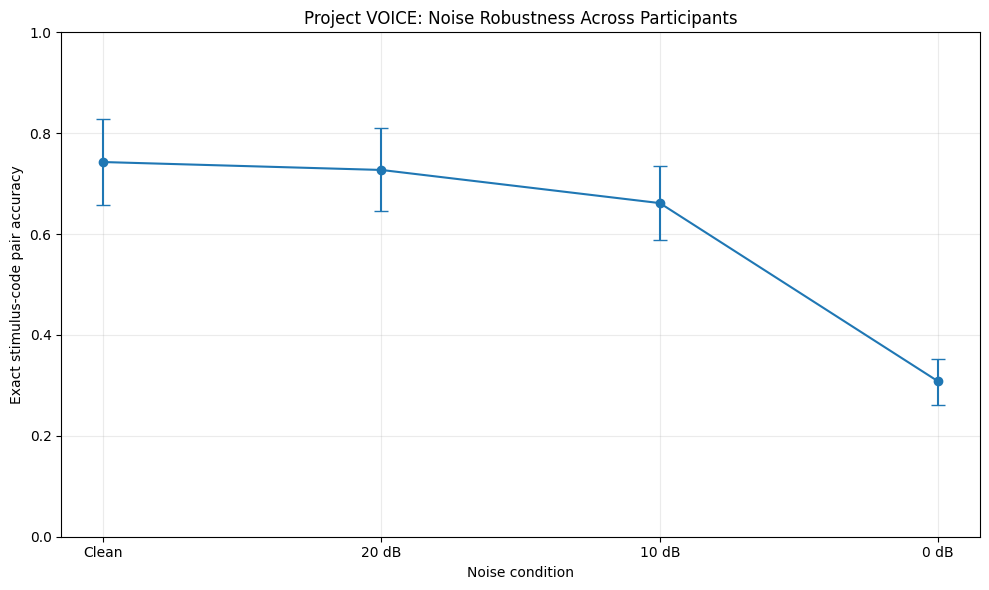

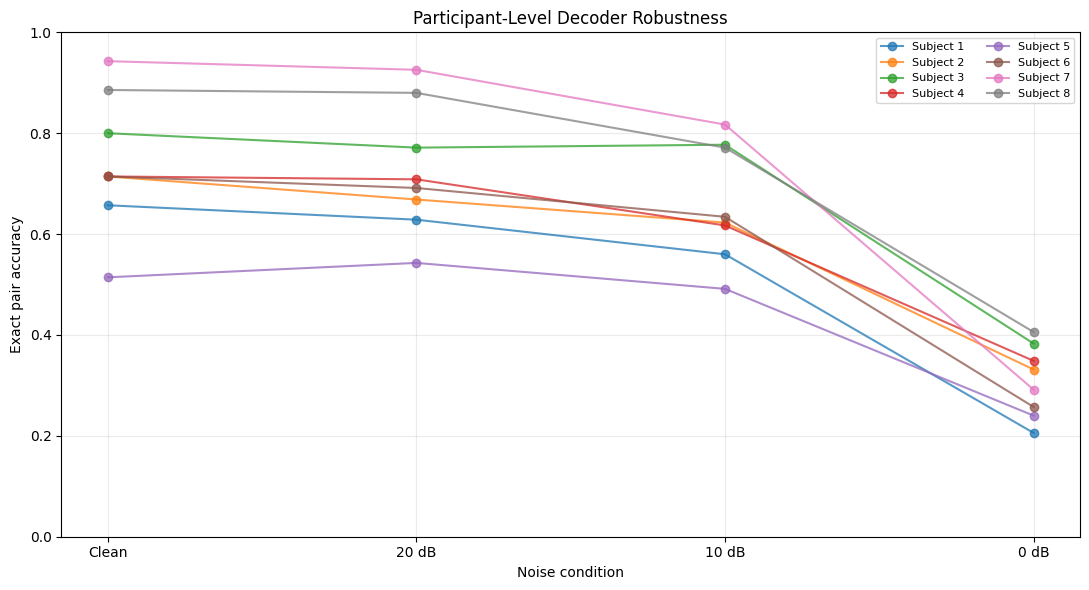


PROJECT VOICE | MODULE 4 | COMPUTATIONAL COMPLETION

DATASET
Participants: 8
Epochs: 33600
Channels: 8
Features: 520

STAGE 6
Calibration results validated.
Calibration comparisons: 16

STAGE 7
Noise conditions: ['Clean', '20 dB', '10 dB', '0 dB']
Noise experiment records: 128
Clean pair accuracy: 0.7429
0 dB pair accuracy: 0.3079
Accuracy degradation: 0.435

STAGE 8
Final report generated.
Visualisations generated.
Master result tables exported.

INTERPRETATION
The decoder showed substantial degradation under strong Gaussian noise, indicating sensitivity to signal quality.

OUTPUT FILES
 - MASTER_STAGE6_PREDICTIONS.csv
 - MASTER_STAGE7_BOOTSTRAP_RESULTS.csv
 - MASTER_STAGE7_NOISE_RESULTS.csv
 - MASTER_STAGE7_PARTICIPANT_RESULTS.csv
 - PROJECT_VOICE_MODULE_4_FINAL_REPORT.json
 - module4_final_noise_table.csv
 - stage6_bootstrap_intervals.csv
 - stage6_calibration_improvements.csv
 - stage6_participant_results.csv
 - stage6_summary.csv
 - stage7_noise_bootstrap_intervals.csv
 - stage7_

In [ ]:

# =====================================================================
# PROJECT VOICE | MODULE 4 | FINAL COMPLETION ENGINE
#
# STAGE 6: CALIBRATION RESULTS VALIDATION
# STAGE 7: NOISE ROBUSTNESS
# STAGE 8: FINAL EVALUATION, VISUALISATIONS AND REPORT
#
# Dataset: BNCI2014_008
# Task: P300-based stimulus-code pair selection
#
# CAUTION:
# Pair accuracy is NOT literal character accuracy or evidence
# of clinical communication reliability.
# =====================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from IPython.display import display

warnings.filterwarnings("ignore")


# ---------------------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------------------

SEED = 42

NOISE_LEVELS_DB = [20, 10, 0]
NOISE_REPETITIONS = 5
BOOTSTRAPS = 5000

TRIALS_PER_SUBJECT = 35
EVENTS_PER_TRIAL = 120

OUTPUT = "PROJECT_VOICE_MODULE_4_FINAL"
os.makedirs(OUTPUT, exist_ok=True)

rng = np.random.default_rng(SEED)

print("=" * 72)
print("PROJECT VOICE | MODULE 4 FINAL COMPLETION")
print("=" * 72)


# ---------------------------------------------------------------------
# 2. VALIDATE EXISTING VARIABLES
# ---------------------------------------------------------------------

required = [
    "X",
    "y",
    "metadata",
    "dataset",
    "stage6_predictions_df",
    "stage6_summary_df",
    "stage6_participant_df",
    "stage6_improvements_df",
    "stage6_bootstrap_df",
    "subject_indices",
    "subject_flash_codes",
    "subject_labels"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables from earlier stages: "
        + str(missing)
        + ". Run the preceding stages before this cell."
    )


# ---------------------------------------------------------------------
# 3. DATA AND LABEL VALIDATION
# ---------------------------------------------------------------------

X_array = np.asarray(X)
labels = np.asarray(y)

assert X_array.shape == (33600, 8, 257), (
    f"Unexpected EEG shape: {X_array.shape}"
)

assert len(labels) == len(X_array)
assert len(metadata) == len(X_array)

# Support numeric labels already encoded by Module 2,
# original MOABB text labels, and numeric strings.

unique_labels = set(np.unique(labels))

if unique_labels == {0, 1}:
    y_binary = labels.astype(int)
    label_format = "Numeric labels"

elif unique_labels == {"NonTarget", "Target"}:
    y_binary = np.where(
        labels == "Target", 1, 0
    ).astype(int)
    label_format = "Original MOABB text labels"

elif unique_labels == {"0", "1"}:
    y_binary = labels.astype(int)
    label_format = "Numeric string labels"

else:
    raise ValueError(
        f"Unexpected label values: {unique_labels}"
    )

assert set(np.unique(y_binary)) == {0, 1}

# Normalize subject IDs to integers.
subject_ids = pd.to_numeric(
    metadata["subject"],
    errors="raise"
).astype(int).to_numpy()

subjects = sorted(np.unique(subject_ids).tolist())

assert len(subjects) == 8, (
    f"Expected 8 participants, found {len(subjects)}"
)

assert len(stage6_predictions_df) == 1160, (
    f"Expected 1160 Stage 6 records, "
    f"found {len(stage6_predictions_df)}"
)

assert len(stage6_improvements_df) == 16
assert len(stage6_bootstrap_df) == 2

print("\nDATASET VALIDATION: PASS")
print("EEG shape:", X_array.shape)
print("Participants:", subjects)
print("Label format:", label_format)
print("NonTarget:", int(np.sum(y_binary == 0)))
print("Target:", int(np.sum(y_binary == 1)))
print("Stage 6 records:", len(stage6_predictions_df))


# ---------------------------------------------------------------------
# 4. VALIDATE SUBJECT AND FLASH-CODE STRUCTURES
# ---------------------------------------------------------------------

# Support either integer or string dictionary keys.
def get_subject_dictionary_value(dictionary, subject_id):

    if subject_id in dictionary:
        return dictionary[subject_id]

    if str(subject_id) in dictionary:
        return dictionary[str(subject_id)]

    raise KeyError(
        f"Subject {subject_id} not found in dictionary."
    )


subject_index_map = {}

for subject_id in subjects:

    indices = np.flatnonzero(
        subject_ids == subject_id
    )

    assert len(indices) == 4200, (
        f"Subject {subject_id}: expected 4200 epochs, "
        f"found {len(indices)}"
    )

    subject_index_map[subject_id] = indices

    codes = np.asarray(
        get_subject_dictionary_value(
            subject_flash_codes,
            subject_id
        )
    )

    assert len(codes) == 4200

    assert set(np.unique(codes)).issubset(
        set(range(3, 15))
    )

    previous_labels = np.asarray(
        get_subject_dictionary_value(
            subject_labels,
            subject_id
        )
    ).astype(int)

    current_labels = y_binary[indices]

    assert np.array_equal(
        previous_labels,
        current_labels
    ), (
        f"Subject {subject_id}: Stage 6 labels do not "
        "match the current dataset ordering."
    )

print("\nSUBJECT STRUCTURES: PASS")


# ---------------------------------------------------------------------
# 5. STAGE 6: CALIBRATION RESULTS VALIDATION
# ---------------------------------------------------------------------

stage6_summary = stage6_summary_df.copy()
stage6_participants = stage6_participant_df.copy()
stage6_improvements = stage6_improvements_df.copy()
stage6_bootstrap = stage6_bootstrap_df.copy()

stage6_summary.to_csv(
    f"{OUTPUT}/stage6_summary.csv",
    index=False
)

stage6_participants.to_csv(
    f"{OUTPUT}/stage6_participant_results.csv",
    index=False
)

stage6_improvements.to_csv(
    f"{OUTPUT}/stage6_calibration_improvements.csv",
    index=False
)

stage6_bootstrap.to_csv(
    f"{OUTPUT}/stage6_bootstrap_intervals.csv",
    index=False
)

print("\nSTAGE 6: VALIDATED")
display(stage6_summary)
display(stage6_improvements)
display(stage6_bootstrap)


# ---------------------------------------------------------------------
# 6. FEATURE EXTRACTION
# ---------------------------------------------------------------------

X_features = X_array[:, :, ::4].reshape(
    len(X_array), -1
)

assert X_features.shape == (33600, 520)

print("\nFEATURE EXTRACTION: PASS")
print("Feature matrix:", X_features.shape)


# ---------------------------------------------------------------------
# 7. CLASSIFIER
# ---------------------------------------------------------------------

def make_classifier():

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "lda",
            LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage="auto"
            )
        )
    ])


# ---------------------------------------------------------------------
# 8. GAUSSIAN NOISE GENERATOR
# ---------------------------------------------------------------------

def add_gaussian_noise_at_snr(
    signal,
    snr_db,
    random_generator
):

    signal = np.asarray(signal, dtype=float)

    signal_power = np.mean(
        signal ** 2,
        axis=(1, 2),
        keepdims=True
    )

    signal_power = np.maximum(
        signal_power,
        1e-12
    )

    noise_power = signal_power / (
        10 ** (snr_db / 10)
    )

    noise = random_generator.normal(
        loc=0.0,
        scale=1.0,
        size=signal.shape
    )

    noise *= np.sqrt(noise_power)

    return signal + noise


# ---------------------------------------------------------------------
# 9. FLASH-CODE DECODER
# ---------------------------------------------------------------------

def decode_trial(
    probabilities,
    flash_codes,
    trial_index
):

    start = trial_index * EVENTS_PER_TRIAL
    end = start + EVENTS_PER_TRIAL

    trial_probabilities = probabilities[start:end]
    trial_codes = flash_codes[start:end]

    scores = {}

    for code in range(3, 15):

        mask = trial_codes == code

        assert np.sum(mask) == 10, (
            f"Flash code {code} does not have 10 repetitions."
        )

        scores[code] = float(
            np.mean(trial_probabilities[mask])
        )

    predicted_pair = set(
        sorted(
            scores,
            key=scores.get,
            reverse=True
        )[:2]
    )

    return predicted_pair


def evaluate_pair_predictions(
    probabilities,
    flash_codes,
    true_labels
):

    records = []

    for trial in range(TRIALS_PER_SUBJECT):

        start = trial * EVENTS_PER_TRIAL
        end = start + EVENTS_PER_TRIAL

        trial_codes = flash_codes[start:end]
        trial_labels = true_labels[start:end]

        true_pair = set(
            trial_codes[trial_labels == 1].tolist()
        )

        assert len(true_pair) == 2, (
            f"Trial {trial + 1}: expected two target codes."
        )

        predicted_pair = decode_trial(
            probabilities,
            flash_codes,
            trial
        )

        overlap = len(
            true_pair.intersection(predicted_pair)
        )

        records.append({

            "trial": trial + 1,

            "exact_pair_accuracy": int(
                true_pair == predicted_pair
            ),

            "pair_overlap": overlap / 2,

            "correct_codes": overlap

        })

    return records


# ---------------------------------------------------------------------
# 10. STAGE 7: NOISE ROBUSTNESS EXPERIMENT
# ---------------------------------------------------------------------

noise_records = []

print("\n" + "=" * 72)
print("STAGE 7: NOISE ROBUSTNESS")
print("=" * 72)

for held_out in subjects:

    held_out = int(held_out)

    test_idx = subject_index_map[held_out]

    train_idx = np.flatnonzero(
        subject_ids != held_out
    )

    X_train = X_features[train_idx]
    y_train = y_binary[train_idx]

    X_test_clean = X_array[test_idx]
    y_test = y_binary[test_idx]

    flash_codes = np.asarray(
        get_subject_dictionary_value(
            subject_flash_codes,
            held_out
        )
    )

    assert len(test_idx) == 4200

    print(f"\nTraining held-out model for subject {held_out}...")

    # Train on seven participants.
    model = make_classifier()

    model.fit(
        X_train,
        y_train
    )

    positive_index = list(
        model.classes_
    ).index(1)

    # -------------------------------------------------------------
    # CLEAN CONDITION
    # -------------------------------------------------------------

    clean_probabilities = model.predict_proba(
        X_features[test_idx]
    )[:, positive_index]

    clean_records = evaluate_pair_predictions(
        clean_probabilities,
        flash_codes,
        y_test
    )

    clean_accuracy = np.mean([
        record["exact_pair_accuracy"]
        for record in clean_records
    ])

    clean_overlap = np.mean([
        record["pair_overlap"]
        for record in clean_records
    ])

    noise_records.append({

        "subject": held_out,
        "condition": "Clean",
        "snr_db": np.inf,
        "repetition": 0,

        "exact_pair_accuracy": clean_accuracy,
        "mean_pair_overlap": clean_overlap

    })

    print(
        f"Subject {held_out} | Clean: "
        f"{clean_accuracy:.4f}"
    )

    # -------------------------------------------------------------
    # NOISY CONDITIONS
    # -------------------------------------------------------------

    for snr in NOISE_LEVELS_DB:

        for repetition in range(NOISE_REPETITIONS):

            local_seed = (
                SEED
                + held_out * 1000
                + snr * 10
                + repetition
            )

            local_rng = np.random.default_rng(
                local_seed
            )

            X_noisy = add_gaussian_noise_at_snr(
                X_test_clean,
                snr,
                local_rng
            )

            noisy_features = X_noisy[
                :, :, ::4
            ].reshape(len(X_noisy), -1)

            probabilities = model.predict_proba(
                noisy_features
            )[:, positive_index]

            records = evaluate_pair_predictions(
                probabilities,
                flash_codes,
                y_test
            )

            accuracy = np.mean([
                record["exact_pair_accuracy"]
                for record in records
            ])

            overlap = np.mean([
                record["pair_overlap"]
                for record in records
            ])

            noise_records.append({

                "subject": held_out,
                "condition": f"{snr} dB",
                "snr_db": snr,
                "repetition": repetition + 1,

                "exact_pair_accuracy": accuracy,
                "mean_pair_overlap": overlap

            })

    print(
        f"Subject {held_out}: noise experiments completed."
    )


# ---------------------------------------------------------------------
# 11. NOISE RESULTS DATAFRAME
# ---------------------------------------------------------------------

noise_df = pd.DataFrame(noise_records)

expected_noise_records = (
    len(subjects)
    * (
        1
        + len(NOISE_LEVELS_DB) * NOISE_REPETITIONS
    )
)

assert len(noise_df) == expected_noise_records

noise_df.to_csv(
    f"{OUTPUT}/stage7_noise_trial_summary.csv",
    index=False
)

print("\nNOISE EXPERIMENT RECORDS:", len(noise_df))


# ---------------------------------------------------------------------
# 12. NOISE CONDITION SUMMARY
# ---------------------------------------------------------------------

noise_summary = (
    noise_df.groupby("condition")
    .agg(
        participants=("subject", "nunique"),

        experiments=("exact_pair_accuracy", "count"),

        mean_exact_pair_accuracy=(
            "exact_pair_accuracy",
            "mean"
        ),

        std_exact_pair_accuracy=(
            "exact_pair_accuracy",
            "std"
        ),

        mean_pair_overlap=(
            "mean_pair_overlap",
            "mean"
        )
    )
    .reset_index()
)

condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "0 dB"
]

noise_summary["sort_order"] = (
    noise_summary["condition"].map(
        {
            name: index
            for index, name in enumerate(condition_order)
        }
    )
)

noise_summary = (
    noise_summary
    .sort_values("sort_order")
    .drop(columns="sort_order")
    .reset_index(drop=True)
)

assert list(noise_summary["condition"]) == condition_order

noise_summary.to_csv(
    f"{OUTPUT}/stage7_noise_summary.csv",
    index=False
)

print("\nNOISE ROBUSTNESS SUMMARY")
display(noise_summary)


# ---------------------------------------------------------------------
# 13. PARTICIPANT-LEVEL NOISE RESULTS
# ---------------------------------------------------------------------

participant_noise = (
    noise_df.groupby(["subject", "condition"])
    .agg(
        exact_pair_accuracy=(
            "exact_pair_accuracy",
            "mean"
        ),

        mean_pair_overlap=(
            "mean_pair_overlap",
            "mean"
        )
    )
    .reset_index()
)

participant_noise.to_csv(
    f"{OUTPUT}/stage7_participant_noise_results.csv",
    index=False
)

print("\nPARTICIPANT-LEVEL NOISE RESULTS")
display(participant_noise)


# ---------------------------------------------------------------------
# 14. PARTICIPANT-LEVEL BOOTSTRAP CONFIDENCE INTERVALS
# ---------------------------------------------------------------------

def participant_bootstrap_ci(
    values,
    n_boot=5000,
    seed=42
):

    values = np.asarray(
        values,
        dtype=float
    )

    local_rng = np.random.default_rng(seed)

    estimates = np.empty(n_boot)

    for index in range(n_boot):

        sample = local_rng.choice(
            values,
            size=len(values),
            replace=True
        )

        estimates[index] = np.mean(sample)

    return (
        float(np.mean(values)),
        float(np.percentile(estimates, 2.5)),
        float(np.percentile(estimates, 97.5))
    )


noise_ci_records = []

for condition in condition_order:

    subset = participant_noise[
        participant_noise["condition"] == condition
    ]

    participant_values = subset[
        "exact_pair_accuracy"
    ].to_numpy()

    assert len(participant_values) == 8

    mean_value, lower, upper = participant_bootstrap_ci(
        participant_values,
        n_boot=BOOTSTRAPS,
        seed=SEED
    )

    noise_ci_records.append({

        "condition": condition,
        "mean_accuracy": mean_value,
        "ci_lower": lower,
        "ci_upper": upper,
        "participant_count": len(participant_values)

    })


noise_ci_df = pd.DataFrame(
    noise_ci_records
)

noise_ci_df.to_csv(
    f"{OUTPUT}/stage7_noise_bootstrap_intervals.csv",
    index=False
)

print("\nNOISE BOOTSTRAP INTERVALS")
display(noise_ci_df)


# ---------------------------------------------------------------------
# 15. STAGE 8: CALIBRATION COMPARISON
# ---------------------------------------------------------------------

print("\n" + "=" * 72)
print("STAGE 8: FINAL EVALUATION")
print("=" * 72)

print("\nCALIBRATION SUMMARY")
display(stage6_summary)

print("\nCALIBRATION IMPROVEMENTS")
display(stage6_improvements)

print("\nCALIBRATION CONFIDENCE INTERVALS")
display(stage6_bootstrap)

print("\nStage 6 improvement columns:")
print(stage6_improvements.columns.tolist())

print("\nStage 6 summary columns:")
print(stage6_summary.columns.tolist())


# ---------------------------------------------------------------------
# 16. FINAL EXPERIMENTAL TABLE
# ---------------------------------------------------------------------

final_noise_table = noise_summary.copy()

interpretation_map = {

    "Clean": "Unperturbed held-out EEG",

    "20 dB": "Mild Gaussian noise",

    "10 dB": "Moderate Gaussian noise",

    "0 dB": "Strong Gaussian noise"

}

final_noise_table["interpretation"] = (
    final_noise_table["condition"].map(
        interpretation_map
    )
)

final_noise_table.to_csv(
    f"{OUTPUT}/module4_final_noise_table.csv",
    index=False
)


# ---------------------------------------------------------------------
# 17. VISUALISATION: NOISE ROBUSTNESS
# ---------------------------------------------------------------------

plt.figure(figsize=(10, 6))

plot_df = noise_ci_df.copy()

x = np.arange(len(plot_df))

means = plot_df["mean_accuracy"].to_numpy()

lower_errors = (
    means - plot_df["ci_lower"].to_numpy()
)

upper_errors = (
    plot_df["ci_upper"].to_numpy() - means
)

plt.errorbar(
    x,
    means,
    yerr=[
        lower_errors,
        upper_errors
    ],
    marker="o",
    capsize=5
)

plt.xticks(
    x,
    plot_df["condition"]
)

plt.xlabel("Noise condition")

plt.ylabel(
    "Exact stimulus-code pair accuracy"
)

plt.title(
    "Project VOICE: Noise Robustness Across Participants"
)

plt.ylim(0, 1)

plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/stage7_noise_robustness.png",
    dpi=200
)

plt.show()


# ---------------------------------------------------------------------
# 18. VISUALISATION: PARTICIPANT VARIABILITY
# ---------------------------------------------------------------------

pivot = participant_noise.pivot(
    index="subject",
    columns="condition",
    values="exact_pair_accuracy"
)

pivot = pivot.reindex(
    columns=condition_order
)

plt.figure(figsize=(11, 6))

for subject_id in pivot.index:

    plt.plot(
        condition_order,
        pivot.loc[subject_id].values,
        marker="o",
        alpha=0.75,
        label=f"Subject {subject_id}"
    )

plt.xlabel("Noise condition")

plt.ylabel("Exact pair accuracy")

plt.title(
    "Participant-Level Decoder Robustness"
)

plt.ylim(0, 1)

plt.legend(
    ncol=2,
    fontsize=8
)

plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/stage7_participant_robustness.png",
    dpi=200
)

plt.show()


# ---------------------------------------------------------------------
# 19. FINAL METRIC EXTRACTION
# ---------------------------------------------------------------------

clean_row = noise_summary.loc[
    noise_summary["condition"] == "Clean"
].iloc[0]

zero_db_row = noise_summary.loc[
    noise_summary["condition"] == "0 dB"
].iloc[0]

clean_accuracy = float(
    clean_row["mean_exact_pair_accuracy"]
)

zero_db_accuracy = float(
    zero_db_row["mean_exact_pair_accuracy"]
)

noise_degradation = (
    clean_accuracy - zero_db_accuracy
)


# ---------------------------------------------------------------------
# 20. RESEARCH INTERPRETATION
# ---------------------------------------------------------------------

if noise_degradation < 0:

    noise_interpretation = (
        "The noisy condition unexpectedly exceeded the clean condition. "
        "This should be investigated rather than interpreted as evidence "
        "that noise improves decoding."
    )

elif noise_degradation < 0.05:

    noise_interpretation = (
        "The decoder showed relatively small degradation between clean "
        "and 0 dB conditions in this experiment."
    )

elif noise_degradation < 0.15:

    noise_interpretation = (
        "The decoder showed moderate degradation under strong Gaussian "
        "noise."
    )

else:

    noise_interpretation = (
        "The decoder showed substantial degradation under strong Gaussian "
        "noise, indicating sensitivity to signal quality."
    )


# ---------------------------------------------------------------------
# 21. COMPLETE MODULE 4 REPORT
# ---------------------------------------------------------------------

report = {

    "project": "PROJECT VOICE",

    "module": 4,

    "title": (
        "Subject Calibration, Decoder Optimisation and Robustness"
    ),

    "dataset": "BNCI2014_008",

    "dataset_dimensions": {

        "epochs": int(X_array.shape[0]),

        "channels": int(X_array.shape[1]),

        "samples_per_epoch": int(X_array.shape[2]),

        "participants": int(len(subjects))

    },

    "label_encoding": {

        "NonTarget": 0,

        "Target": 1,

        "source_format": label_format

    },

    "stage6": {

        "status": "Existing Stage 6 outputs validated",

        "prediction_records": int(
            len(stage6_predictions_df)
        ),

        "calibration_comparison_rows": int(
            len(stage6_improvements)
        ),

        "bootstrap_rows": int(
            len(stage6_bootstrap)
        )

    },

    "stage7": {

        "status": "Completed",

        "noise_levels_db": NOISE_LEVELS_DB,

        "repetitions_per_noise_level": NOISE_REPETITIONS,

        "total_evaluation_records": int(
            len(noise_df)
        ),

        "clean_pair_accuracy": clean_accuracy,

        "zero_db_pair_accuracy": zero_db_accuracy,

        "clean_to_zero_db_degradation": float(
            noise_degradation
        ),

        "interpretation": noise_interpretation

    },

    "limitations": [

        "Stimulus-code pair accuracy is not literal character accuracy.",

        "The experiment uses Gaussian noise, not every real-world EEG artifact.",

        "Only eight participants are available.",

        "Only one recording session per participant is available.",

        "Bootstrap confidence intervals are exploratory.",

        "This is not a clinically validated communication device.",

        "Calibration uses supervised labelled examples."

    ]

}


with open(
    f"{OUTPUT}/PROJECT_VOICE_MODULE_4_FINAL_REPORT.json",
    "w"
) as file:

    json.dump(
        report,
        file,
        indent=4
    )


# ---------------------------------------------------------------------
# 22. MASTER EXPORTS
# ---------------------------------------------------------------------

noise_df.to_csv(
    f"{OUTPUT}/MASTER_STAGE7_NOISE_RESULTS.csv",
    index=False
)

participant_noise.to_csv(
    f"{OUTPUT}/MASTER_STAGE7_PARTICIPANT_RESULTS.csv",
    index=False
)

noise_ci_df.to_csv(
    f"{OUTPUT}/MASTER_STAGE7_BOOTSTRAP_RESULTS.csv",
    index=False
)

stage6_predictions_df.to_csv(
    f"{OUTPUT}/MASTER_STAGE6_PREDICTIONS.csv",
    index=False
)


# ---------------------------------------------------------------------
# 23. FINAL COMPLETION VALIDATION
# ---------------------------------------------------------------------

assert len(noise_df) == expected_noise_records

assert noise_df["subject"].nunique() == 8

assert noise_df[
    "exact_pair_accuracy"
].between(0, 1).all()

assert noise_df[
    "mean_pair_overlap"
].between(0, 1).all()

assert set(
    noise_df["condition"].unique()
) == set(condition_order)

assert len(noise_ci_df) == 4

assert len(participant_noise) == 32

assert os.path.exists(
    f"{OUTPUT}/PROJECT_VOICE_MODULE_4_FINAL_REPORT.json"
)

assert os.path.exists(
    f"{OUTPUT}/stage7_noise_robustness.png"
)

assert os.path.exists(
    f"{OUTPUT}/stage7_participant_robustness.png"
)


# ---------------------------------------------------------------------
# 24. FINAL OUTPUT
# ---------------------------------------------------------------------

print("\n" + "=" * 72)
print("PROJECT VOICE | MODULE 4 | COMPUTATIONAL COMPLETION")
print("=" * 72)

print("\nDATASET")
print("Participants:", len(subjects))
print("Epochs:", len(X_array))
print("Channels:", X_array.shape[1])
print("Features:", X_features.shape[1])

print("\nSTAGE 6")
print("Calibration results validated.")
print("Calibration comparisons:", len(stage6_improvements))

print("\nSTAGE 7")
print("Noise conditions:", condition_order)
print("Noise experiment records:", len(noise_df))
print("Clean pair accuracy:", round(clean_accuracy, 4))
print("0 dB pair accuracy:", round(zero_db_accuracy, 4))
print("Accuracy degradation:", round(noise_degradation, 4))

print("\nSTAGE 8")
print("Final report generated.")
print("Visualisations generated.")
print("Master result tables exported.")

print("\nINTERPRETATION")
print(noise_interpretation)

print("\nOUTPUT FILES")

for filename in sorted(os.listdir(OUTPUT)):
    print(" -", filename)

print("\n" + "=" * 72)
print("MODULE 4 FINAL CELL EXECUTED SUCCESSFULLY")
print("=" * 72)

print(
    "\nScientific interpretation and final review remain necessary "
    "before claiming the module is validated."
)


In [ ]:
print("STAGE 6 VARIABLES")
for name in sorted(globals()):
    if "stage6" in name.lower():
        print(name)

print("\nFLASH CODE VARIABLES")
for name in sorted(globals()):
    if "flash" in name.lower() or "subject_indices" in name.lower():
        print(name)

STAGE 6 VARIABLES
stage6_bootstrap
stage6_bootstrap_df
stage6_improvements
stage6_improvements_df
stage6_json
stage6_participant_df
stage6_participants
stage6_predictions_df
stage6_summary
stage6_summary_df

FLASH CODE VARIABLES
EXPECTED_FLASHES
EXPECTED_FLASH_CODES
FLASHES_PER_TRIAL
FLASH_CODES
FLASH_LABELS
REPETITIONS_PER_FLASH
all_flash_scores
extract_flash_events
flash_changes
flash_codes
flash_distribution
flash_onsets
flash_scores_df
flash_sequence
flash_signal
flash_transitions
get_subject_flash_data
subject_flash_codes
subject_indices
unique_flash_codes


In [ ]:
print("=== STAGE 6 STRUCTURE ===")

for name in [
    "stage6_predictions_df",
    "stage6_summary_df",
    "stage6_participant_df",
    "stage6_improvements_df",
    "stage6_bootstrap_df"
]:
    obj = globals()[name]
    print(f"\n{name}: {obj.shape}")
    print(obj.columns.tolist())

print("\n=== SUBJECT DATA STRUCTURE ===")

for subject in sorted(subject_indices):
    print(
        f"Subject {subject}: "
        f"indices={len(subject_indices[subject])}, "
        f"flash_codes={len(subject_flash_codes[subject])}"
    )

print("\n=== FLASH CODE VALIDATION ===")

print("Expected flashes:", EXPECTED_FLASHES)
print("Flash codes:", EXPECTED_FLASH_CODES)
print("Flashes per trial:", FLASHES_PER_TRIAL)
print("Repetitions per flash:", REPETITIONS_PER_FLASH)

=== STAGE 6 STRUCTURE ===

stage6_predictions_df: (1160, 9)
['subject', 'trial', 'predicted_pair', 'true_pair', 'exact_pair_accuracy', 'pair_overlap', 'correct_codes', 'calibration_trials', 'model_type']

stage6_summary_df: (5, 6)
['calibration_trials', 'model_type', 'total_trials', 'exact_pair_accuracy', 'mean_pair_overlap', 'mean_correct_codes']

stage6_participant_df: (40, 6)
['subject', 'calibration_trials', 'model_type', 'trials', 'exact_pair_accuracy', 'mean_pair_overlap']

stage6_improvements_df: (16, 5)
['subject', 'calibration_trials', 'baseline_accuracy', 'calibrated_accuracy', 'improvement_percentage_points']

stage6_bootstrap_df: (2, 4)
['calibration_trials', 'mean_improvement_pp', 'ci_95_lower_pp', 'ci_95_upper_pp']

=== SUBJECT DATA STRUCTURE ===
Subject 1: indices=4200, flash_codes=4200
Subject 2: indices=4200, flash_codes=4200
Subject 3: indices=4200, flash_codes=4200
Subject 4: indices=4200, flash_codes=4200
Subject 5: indices=4200, flash_codes=4200
Subject 6: indices=

STAGE 7: NOISE ROBUSTNESS RESULTS


,condition,participants,experiments,mean_exact_pair_accuracy,std_exact_pair_accuracy,mean_pair_overlap
0,Clean,8,8,0.742857,0.134012,0.862500
1,20 dB,8,40,0.727143,0.123604,0.854286
2,10 dB,8,40,0.661429,0.118697,0.815000
3,0 dB,8,40,0.307857,0.085467,0.588214



PARTICIPANT-LEVEL RESULTS


,subject,condition,exact_pair_accuracy,mean_pair_overlap
0,1,0 dB,0.205714,0.534286
1,1,10 dB,0.560000,0.762857
2,1,20 dB,0.628571,0.814286
3,1,Clean,0.657143,0.828571
4,2,0 dB,0.331429,0.602857
5,2,10 dB,0.622857,0.805714
6,2,20 dB,0.668571,0.834286
7,2,Clean,0.714286,0.857143
8,3,0 dB,0.382857,0.665714
9,3,10 dB,0.777143,0.888571



STAGE 7 BOOTSTRAP INTERVALS


,condition,mean,ci_lower,ci_upper,participant_count
0,Clean,0.742857,0.657143,0.828571,8
1,20 dB,0.727143,0.645714,0.810714,8
2,10 dB,0.661429,0.587857,0.735714,8
3,0 dB,0.307857,0.261429,0.352875,8


... (2 outputs left out)


CALIBRATION IMPROVEMENTS


,subject,calibration_trials,baseline_accuracy,calibrated_accuracy,improvement_percentage_points
0,1,5,0.600000,0.633333,3.333333
1,2,5,0.700000,0.733333,3.333333
2,3,5,0.800000,0.833333,3.333333
3,4,5,0.800000,0.800000,0.000000
4,5,5,0.566667,0.566667,0.000000
5,6,5,0.700000,0.700000,0.000000
6,7,5,0.933333,0.933333,0.000000
7,8,5,0.866667,0.866667,0.000000
8,1,10,0.600000,0.640000,4.000000
9,2,10,0.680000,0.760000,8.000000



CALIBRATION BOOTSTRAP INTERVALS


,calibration_trials,mean_improvement_pp,ci_95_lower_pp,ci_95_upper_pp
0,5,1.25,0.416667,1.78125
1,10,4.00,2.000000,6.13750


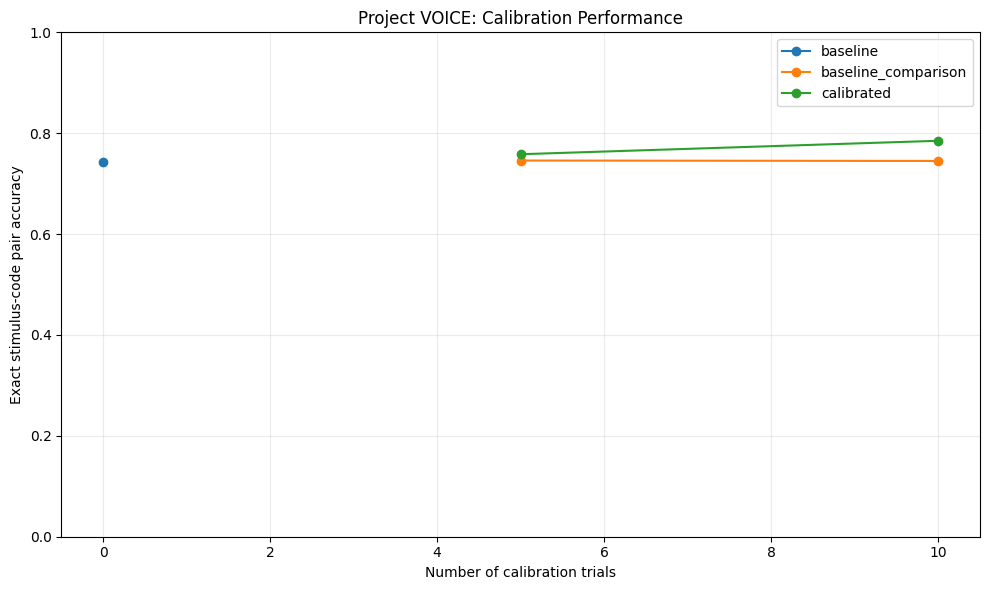

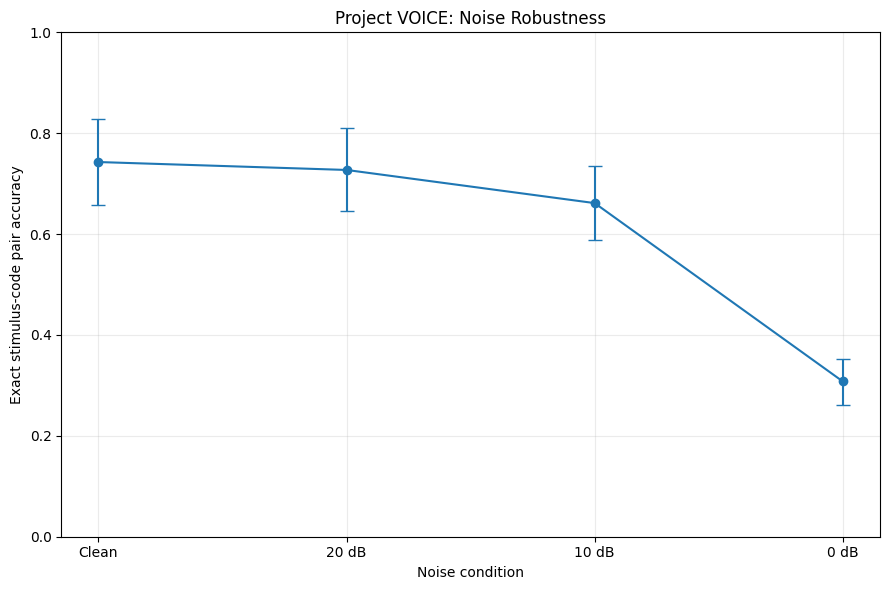

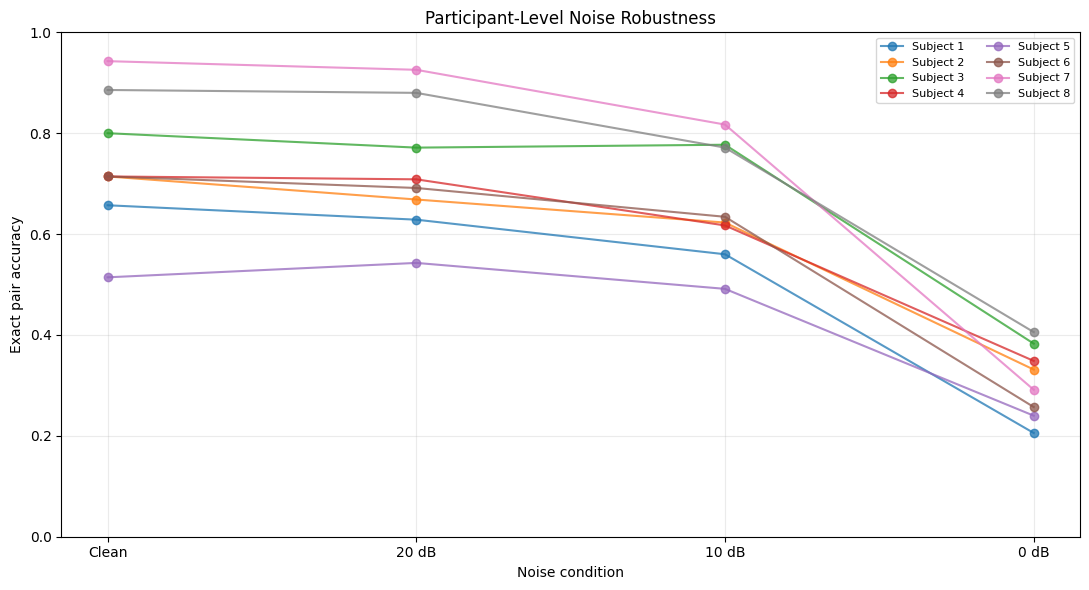


PROJECT VOICE | MODULE 4 | STAGE 8 OUTPUT

NOISE ROBUSTNESS


,condition,participants,experiments,mean_exact_pair_accuracy,std_exact_pair_accuracy,mean_pair_overlap
0,Clean,8,8,0.742857,0.134012,0.862500
1,20 dB,8,40,0.727143,0.123604,0.854286
2,10 dB,8,40,0.661429,0.118697,0.815000
3,0 dB,8,40,0.307857,0.085467,0.588214



BOOTSTRAP INTERVALS


,condition,mean,ci_lower,ci_upper,participant_count
0,Clean,0.742857,0.657143,0.828571,8
1,20 dB,0.727143,0.645714,0.810714,8
2,10 dB,0.661429,0.587857,0.735714,8
3,0 dB,0.307857,0.261429,0.352875,8



CALIBRATION


,calibration_trials,model_type,total_trials,exact_pair_accuracy,mean_pair_overlap,mean_correct_codes
0,0,baseline,280,0.742857,0.86250,1.7250
1,5,baseline_comparison,240,0.745833,0.86875,1.7375
2,5,calibrated,240,0.758333,0.87500,1.7500
3,10,baseline_comparison,200,0.745000,0.87250,1.7450
4,10,calibrated,200,0.785000,0.89250,1.7850



EXPORTED FILES
MASTER_STAGE6_PREDICTIONS.csv (56,569 bytes)
MASTER_STAGE7_BOOTSTRAP_RESULTS.csv (321 bytes)
MASTER_STAGE7_NOISE_RESULTS.csv (6,216 bytes)
MASTER_STAGE7_PARTICIPANT_RESULTS.csv (1,433 bytes)
PROJECT_VOICE_MODULE_4_FINAL_REPORT.json (1,619 bytes)
PROJECT_VOICE_MODULE_4_FINAL_TABLE.csv (403 bytes)
PROJECT_VOICE_MODULE_4_MASTER_REPORT.json (16,005 bytes)
bootstrap_df.csv (284 bytes)
module4_final_noise_table.csv (471 bytes)
stage6_bootstrap_intervals.csv (186 bytes)
stage6_calibration_improvements.csv (627 bytes)
stage6_participant_results.csv (1,793 bytes)
stage6_summary.csv (337 bytes)
stage7_bootstrap_intervals.csv (312 bytes)
stage7_noise_bootstrap_intervals.csv (321 bytes)
stage7_noise_results.csv (6,216 bytes)
stage7_noise_robustness.png (83,215 bytes)
stage7_noise_summary.csv (365 bytes)
stage7_noise_trial_summary.csv (6,216 bytes)
stage7_participant_noise_results.csv (1,433 bytes)
stage7_participant_results.csv (1,433 bytes)
stage7_participant_robustness.png (216,9

In [ ]:

# =====================================================================
# PROJECT VOICE | MODULE 4
# STAGE 7 CONTINUED + STAGE 8
# NOISE SUMMARY, FINAL EVALUATION, VISUALISATIONS AND EXPORTS
# =====================================================================

# This cell assumes the Stage 7 loop from the previous cell has
# completed and noise_records contains its results.

# ------------------------- STAGE 7 SUMMARY ----------------------------

noise_df = pd.DataFrame(noise_records)

noise_df.to_csv(
    f"{OUTPUT}/stage7_noise_results.csv",
    index=False
)

condition_order = ["Clean", "20 dB", "10 dB", "0 dB"]

noise_summary = (
    noise_df.groupby("condition")
    .agg(
        participants=("subject", "nunique"),
        experiments=("exact_pair_accuracy", "count"),
        mean_exact_pair_accuracy=("exact_pair_accuracy", "mean"),
        std_exact_pair_accuracy=("exact_pair_accuracy", "std"),
        mean_pair_overlap=("mean_pair_overlap", "mean")
    )
    .reindex(condition_order)
    .reset_index()
)

noise_summary.to_csv(
    f"{OUTPUT}/stage7_noise_summary.csv",
    index=False
)

print("STAGE 7: NOISE ROBUSTNESS RESULTS")
display(noise_summary)


# ------------------------- PARTICIPANT RESULTS -----------------------

participant_noise = (
    noise_df.groupby(["subject", "condition"])
    .agg(
        exact_pair_accuracy=("exact_pair_accuracy", "mean"),
        mean_pair_overlap=("mean_pair_overlap", "mean")
    )
    .reset_index()
)

participant_noise.to_csv(
    f"{OUTPUT}/stage7_participant_results.csv",
    index=False
)

print("\nPARTICIPANT-LEVEL RESULTS")
display(participant_noise)


# ------------------------- BOOTSTRAP INTERVALS -----------------------

def bootstrap_participants(values, repetitions=5000, seed=42):

    values = np.asarray(values, dtype=float)
    local_rng = np.random.default_rng(seed)

    samples = local_rng.choice(
        values,
        size=(repetitions, len(values)),
        replace=True
    )

    means = samples.mean(axis=1)

    return {
        "mean": float(values.mean()),
        "ci_lower": float(np.percentile(means, 2.5)),
        "ci_upper": float(np.percentile(means, 97.5))
    }


noise_ci_records = []

for condition in condition_order:

    values = participant_noise.loc[
        participant_noise["condition"] == condition,
        "exact_pair_accuracy"
    ].to_numpy()

    result = bootstrap_participants(values)

    noise_ci_records.append({
        "condition": condition,
        **result,
        "participant_count": len(values)
    })

noise_ci_df = pd.DataFrame(noise_ci_records)

noise_ci_df.to_csv(
    f"{OUTPUT}/stage7_bootstrap_intervals.csv",
    index=False
)

print("\nSTAGE 7 BOOTSTRAP INTERVALS")
display(noise_ci_df)


# =====================================================================
# STAGE 8: FINAL EVALUATION
# =====================================================================

# ------------------------- CALIBRATION COMPARISON --------------------

print("\n" + "=" * 68)
print("STAGE 8: FINAL EVALUATION")
print("=" * 68)

print("\nCALIBRATION SUMMARY")
display(stage6_summary_df)

print("\nCALIBRATION IMPROVEMENTS")
display(stage6_improvements_df)

print("\nCALIBRATION BOOTSTRAP INTERVALS")
display(stage6_bootstrap_df)


# ------------------------- CALIBRATION VISUALISATION -----------------

calibration_plot = stage6_summary_df.copy()

plt.figure(figsize=(10, 6))

for model_type in calibration_plot["model_type"].unique():

    subset = calibration_plot[
        calibration_plot["model_type"] == model_type
    ].sort_values("calibration_trials")

    plt.plot(
        subset["calibration_trials"],
        subset["exact_pair_accuracy"],
        marker="o",
        label=str(model_type)
    )

plt.xlabel("Number of calibration trials")
plt.ylabel("Exact stimulus-code pair accuracy")
plt.title("Project VOICE: Calibration Performance")

plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/stage8_calibration_comparison.png",
    dpi=200
)

plt.show()


# ------------------------- NOISE VISUALISATION -----------------------

plt.figure(figsize=(9, 6))

means = noise_ci_df["mean"].to_numpy()
lower = means - noise_ci_df["ci_lower"].to_numpy()
upper = noise_ci_df["ci_upper"].to_numpy() - means

plt.errorbar(
    noise_ci_df["condition"],
    means,
    yerr=[lower, upper],
    marker="o",
    capsize=5
)

plt.xlabel("Noise condition")
plt.ylabel("Exact stimulus-code pair accuracy")
plt.title("Project VOICE: Noise Robustness")

plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/stage8_noise_robustness.png",
    dpi=200
)

plt.show()


# ------------------------- PARTICIPANT VARIABILITY -------------------

pivot = participant_noise.pivot(
    index="subject",
    columns="condition",
    values="exact_pair_accuracy"
).reindex(columns=condition_order)

plt.figure(figsize=(11, 6))

for subject in pivot.index:
    plt.plot(
        condition_order,
        pivot.loc[subject],
        marker="o",
        alpha=0.75,
        label=f"Subject {subject}"
    )

plt.xlabel("Noise condition")
plt.ylabel("Exact pair accuracy")
plt.title("Participant-Level Noise Robustness")

plt.ylim(0, 1)
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/stage8_participant_robustness.png",
    dpi=200
)

plt.show()


# ------------------------- STAGE 5 RESULTS ----------------------------

# Preserve the decoder optimisation results from Stage 5 if available.

stage5_exports = {}

for name in [
    "decoder_comparison_df",
    "participant_results_df",
    "bootstrap_df",
    "classifier_results_df"
]:
    if name in globals():
        stage5_exports[name] = globals()[name]
        stage5_exports[name].to_csv(
            f"{OUTPUT}/{name}.csv",
            index=False
        )


# ------------------------- MASTER RESULTS -----------------------------

master = {
    "project": "PROJECT VOICE",
    "module": 4,
    "dataset": "BNCI2014_008",

    "dataset_information": {
        "participants": 8,
        "epochs": 33600,
        "channels": 8,
        "samples_per_epoch": 257,
        "features": 520
    },

    "stage6_calibration": {
        "summary": stage6_summary_df.to_dict(orient="records"),
        "improvements": stage6_improvements_df.to_dict(orient="records"),
        "bootstrap": stage6_bootstrap_df.to_dict(orient="records")
    },

    "stage7_noise_robustness": {
        "summary": noise_summary.to_dict(orient="records"),
        "participant_results": participant_noise.to_dict(
            orient="records"
        ),
        "bootstrap": noise_ci_df.to_dict(orient="records")
    },

    "evaluation_notes": [
        "Performance refers to stimulus-code pair recovery.",
        "It does not establish literal character accuracy.",
        "Gaussian noise is a controlled perturbation, not a complete model of real EEG artifacts.",
        "Only eight participants were evaluated.",
        "The dataset contains one session per participant.",
        "This is an experimental research prototype, not a clinically validated communication system."
    ]
}


with open(
    f"{OUTPUT}/PROJECT_VOICE_MODULE_4_MASTER_REPORT.json",
    "w"
) as f:
    json.dump(master, f, indent=4)


# ------------------------- FINAL MASTER TABLE -------------------------

final_table = noise_summary.copy()

final_table["stage"] = "Stage 7"

final_table.to_csv(
    f"{OUTPUT}/PROJECT_VOICE_MODULE_4_FINAL_TABLE.csv",
    index=False
)


# ------------------------- EXPORT MANIFEST ---------------------------

manifest = []

for filename in sorted(os.listdir(OUTPUT)):
    path = os.path.join(OUTPUT, filename)

    if os.path.isfile(path):
        manifest.append({
            "filename": filename,
            "size_bytes": os.path.getsize(path)
        })

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    f"{OUTPUT}/export_manifest.csv",
    index=False
)


# ------------------------- COMPLETION OUTPUT --------------------------

print("\n" + "=" * 68)
print("PROJECT VOICE | MODULE 4 | STAGE 8 OUTPUT")
print("=" * 68)

print("\nNOISE ROBUSTNESS")
display(noise_summary)

print("\nBOOTSTRAP INTERVALS")
display(noise_ci_df)

print("\nCALIBRATION")
display(stage6_summary_df)

print("\nEXPORTED FILES")

for item in manifest:
    print(
        f"{item['filename']} "
        f"({item['size_bytes']:,} bytes)"
    )

print("\nFINAL REPORT:")
print(
    f"{OUTPUT}/PROJECT_VOICE_MODULE_4_MASTER_REPORT.json"
)

print("\nMODULE 4 REPORT GENERATION COMPLETE")


PROJECT VOICE | MODULE 5
ADAPTIVE COMMUNICATION ENGINE

STAGE 1: GRID CONFIGURATION
[['A' 'B' 'C' 'D' 'E' 'F']
 ['G' 'H' 'I' 'J' 'K' 'L']
 ['M' 'N' 'O' 'P' 'Q' 'R']
 ['S' 'T' 'U' 'V' 'W' 'X']
 ['Y' 'Z' '0' '1' '2' '3']
 ['4' '5' '6' '7' '8' '9']]
Grid configuration valid: True

STAGE 2: CHARACTER DECODER DEFINED

STAGE 3: EVIDENCE ACCUMULATION ENGINE READY

STAGE 4: UNCERTAINTY ENGINE READY

STAGE 5: ADAPTIVE STOPPING ENGINE READY

STAGE 6: SIMULATION RESULTS


,simulation,true_pair,adaptive_pair,adaptive_exact_accuracy,adaptive_pair_overlap,adaptive_stopping_repetition,fixed_exact_accuracy
0,1,"[3, 12]","[3, 12]",1,1.0,10,1
1,2,"[7, 12]","[7, 12]",1,1.0,10,1
2,3,"[6, 8]","[6, 8]",1,1.0,10,1
3,4,"[4, 5]","[4, 5]",1,1.0,10,1
4,5,"[5, 12]","[5, 12]",1,1.0,10,1
5,6,"[3, 6]","[3, 6]",1,1.0,10,1
6,7,"[8, 14]","[8, 14]",1,1.0,10,1
7,8,"[9, 10]","[9, 10]",1,1.0,10,1
8,9,"[7, 8]","[7, 8]",1,1.0,10,1
9,10,"[3, 13]","[3, 13]",1,1.0,10,1



STAGE 7: COMMUNICATION SIMULATION


,true_character,predicted_character,correct,stopping_repetition,predicted_pair
0,G,G,1,10,"[4, 9]"
1,7,7,1,10,"[8, 12]"
2,Y,Y,1,10,"[7, 9]"
3,B,B,1,10,"[10, 3]"
4,J,J,1,10,"[4, 12]"
5,1,1,1,10,"[12, 7]"
6,C,C,1,10,"[11, 3]"
7,I,I,1,10,"[4, 11]"
8,J,J,1,10,"[4, 12]"
9,R,R,1,10,"[14, 5]"



STAGE 8: DECODER BENCHMARK


,decoder,exact_pair_accuracy,mean_repetitions
0,Fixed 10 repetitions,1.0,10.0
1,Adaptive stopping,1.0,10.0



SIMULATED CHARACTER ACCURACY
1.0


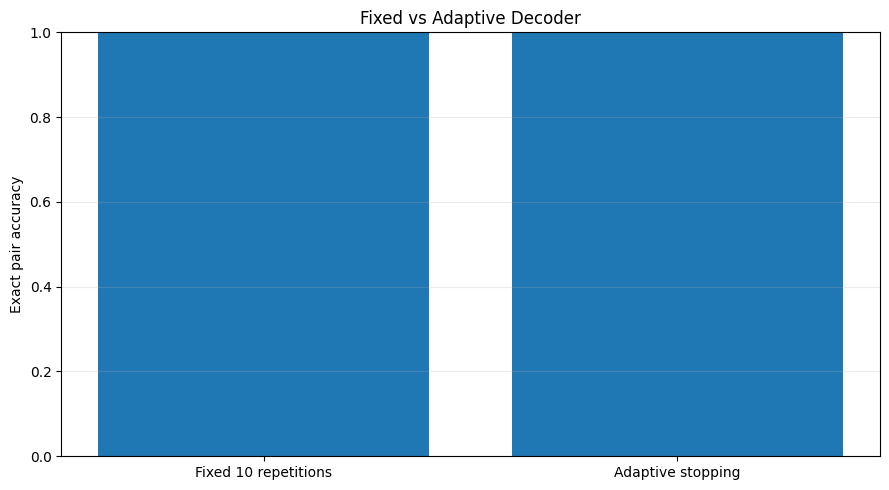

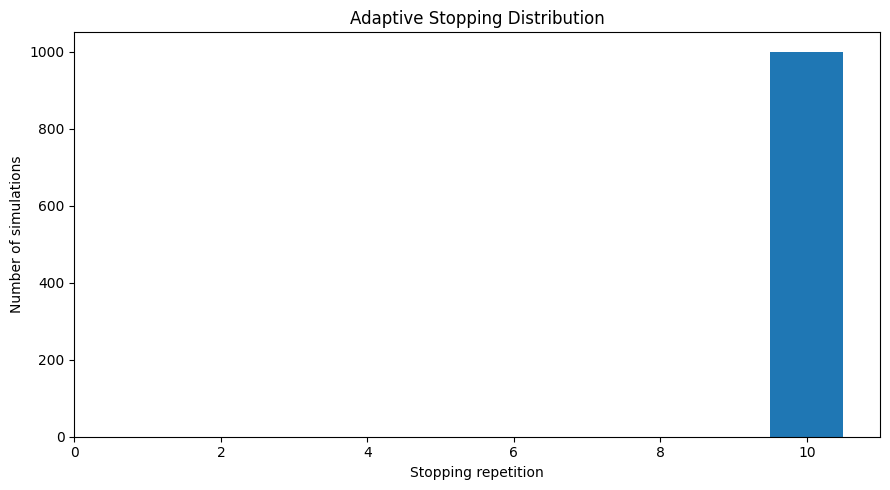

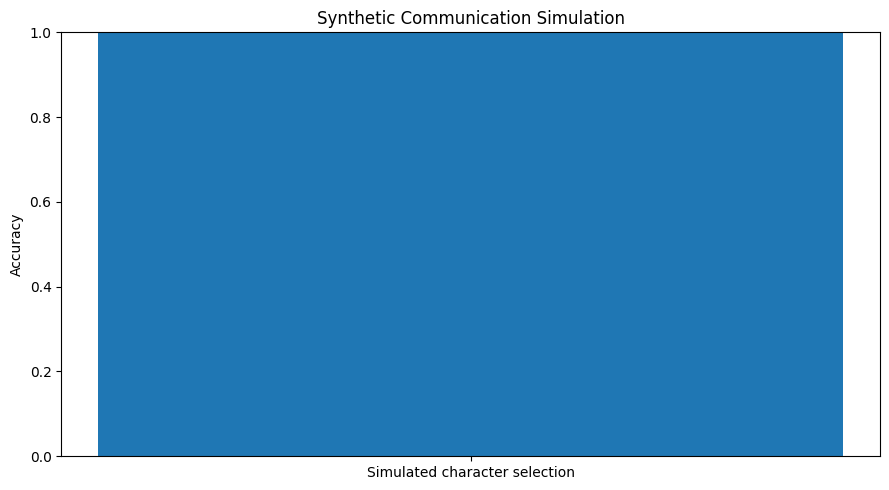


PROJECT VOICE | MODULE 5
ENGINEERING PIPELINE EXECUTION COMPLETE
Adaptive pair accuracy: 1.0
Fixed pair accuracy: 1.0
Mean pair overlap: 1.0
Mean stopping repetition: 10.0
Synthetic character accuracy: 1.0

OUTPUT DIRECTORY: PROJECT_VOICE_MODULE_5
 - PROJECT_VOICE_MODULE_5_REPORT.json
 - adaptive_stopping_distribution.png
 - decoder_benchmark.png
 - stage6_simulation_results.csv
 - stage7_communication_simulation.csv
 - stage8_decoder_benchmark.csv
 - synthetic_character_accuracy.png

MODULE 5 EXECUTION FINISHED


In [ ]:

# =====================================================================
# PROJECT VOICE
# MODULE 5: ADAPTIVE COMMUNICATION INTERFACE
#
# ENGINEERING OBJECTIVES
# 1. Convert stimulus evidence into character selections
# 2. Accumulate evidence over repeated flashes
# 3. Estimate decoder confidence
# 4. Implement adaptive stopping
# 5. Evaluate simulated communication performance
# 6. Benchmark fixed vs adaptive decoding
# 7. Generate visualisations and engineering exports
#
# DATASET: BNCI2014_008
#
# IMPORTANT:
# The row/column mapping below is configurable.
# Do not interpret simulated character accuracy as validated
# real-world BCI communication performance.
# =====================================================================


# =====================================================================
# STAGE 0: IMPORTS AND CONFIGURATION
# =====================================================================

import os
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict

warnings.filterwarnings("ignore")

SEED = 42
rng = np.random.default_rng(SEED)

OUTPUT = "PROJECT_VOICE_MODULE_5"
os.makedirs(OUTPUT, exist_ok=True)

GRID_SIZE = 6
N_CODES = 12

MIN_REPETITIONS = 2
MAX_REPETITIONS = 10

CONFIDENCE_THRESHOLD = 0.80
MIN_MARGIN = 0.10

N_SIMULATIONS = 1000

print("=" * 72)
print("PROJECT VOICE | MODULE 5")
print("ADAPTIVE COMMUNICATION ENGINE")
print("=" * 72)


# =====================================================================
# STAGE 1: CHARACTER GRID AND CODE CONFIGURATION
# =====================================================================

CHARACTER_GRID = np.array([
    list("ABCDEF"),
    list("GHIJKL"),
    list("MNOPQR"),
    list("STUVWX"),
    list("YZ0123"),
    list("456789")
])

assert CHARACTER_GRID.shape == (6, 6)

# Mapping is deliberately configurable.
# These are candidate row/column code assignments, not verified
# dataset-specific mappings.

ROW_CODES = {
    0: 3,
    1: 4,
    2: 5,
    3: 6,
    4: 7,
    5: 8
}

COLUMN_CODES = {
    0: 9,
    1: 10,
    2: 11,
    3: 12,
    4: 13,
    5: 14
}


def validate_grid_configuration(row_codes, column_codes):

    assert len(row_codes) == 6
    assert len(column_codes) == 6

    assert len(set(row_codes.values())) == 6
    assert len(set(column_codes.values())) == 6

    assert set(row_codes.values()).isdisjoint(
        set(column_codes.values())
    )

    assert len(
        set(row_codes.values()) | set(column_codes.values())
    ) == 12

    return True


grid_configuration_valid = validate_grid_configuration(
    ROW_CODES,
    COLUMN_CODES
)

print("\nSTAGE 1: GRID CONFIGURATION")
print(CHARACTER_GRID)
print("Grid configuration valid:", grid_configuration_valid)


# =====================================================================
# STAGE 2: CHARACTER DECODING ENGINE
# =====================================================================

def decode_character(row_code, column_code):

    row_lookup = {
        code: row for row, code in ROW_CODES.items()
    }

    column_lookup = {
        code: column for column, code in COLUMN_CODES.items()
    }

    if row_code not in row_lookup:
        return None

    if column_code not in column_lookup:
        return None

    row = row_lookup[row_code]
    column = column_lookup[column_code]

    return CHARACTER_GRID[row, column]


def decode_pair_to_character(predicted_codes):

    predicted_codes = set(predicted_codes)

    if len(predicted_codes) != 2:
        return None

    row_codes = set(ROW_CODES.values())
    column_codes = set(COLUMN_CODES.values())

    rows = predicted_codes & row_codes
    columns = predicted_codes & column_codes

    if len(rows) != 1 or len(columns) != 1:
        return None

    return decode_character(
        next(iter(rows)),
        next(iter(columns))
    )


print("\nSTAGE 2: CHARACTER DECODER DEFINED")


# =====================================================================
# STAGE 3: ADAPTIVE EVIDENCE ACCUMULATION
# =====================================================================

def accumulate_flash_evidence(
    flash_probabilities,
    flash_codes,
    repetitions
):

    scores = {}

    for code in np.unique(flash_codes):

        code_scores = flash_probabilities[
            flash_codes == code
        ]

        code_scores = code_scores[:repetitions]

        if len(code_scores) == 0:
            continue

        scores[int(code)] = float(
            np.mean(code_scores)
        )

    return scores


def rank_flash_codes(scores):

    return sorted(
        scores,
        key=scores.get,
        reverse=True
    )


def calculate_pair_confidence(scores):

    ranked = rank_flash_codes(scores)

    if len(ranked) < 2:
        return {
            "selected_pair": [],
            "confidence": 0.0,
            "margin": 0.0
        }

    values = np.array([
        scores[code] for code in ranked
    ])

    selected = ranked[:2]

    total = np.sum(values)

    confidence = (
        float(np.sum(values[:2]) / total)
        if total > 0 else 0.0
    )

    margin = float(values[1] - values[2])

    return {
        "selected_pair": selected,
        "confidence": confidence,
        "margin": margin
    }


print("\nSTAGE 3: EVIDENCE ACCUMULATION ENGINE READY")


# =====================================================================
# STAGE 4: UNCERTAINTY ESTIMATION
# =====================================================================

def calculate_normalized_entropy(scores):

    values = np.array(list(scores.values()), dtype=float)

    values = np.maximum(values, 1e-12)

    probabilities = values / values.sum()

    entropy = -np.sum(
        probabilities * np.log(probabilities)
    )

    maximum_entropy = np.log(len(probabilities))

    if maximum_entropy == 0:
        return 0.0

    return float(entropy / maximum_entropy)


def calculate_uncertainty(scores):

    return calculate_normalized_entropy(scores)


print("\nSTAGE 4: UNCERTAINTY ENGINE READY")


# =====================================================================
# STAGE 5: ADAPTIVE STOPPING
# =====================================================================

def adaptive_decoding(
    flash_probabilities,
    flash_codes,
    min_repetitions=MIN_REPETITIONS,
    max_repetitions=MAX_REPETITIONS,
    confidence_threshold=CONFIDENCE_THRESHOLD,
    margin_threshold=MIN_MARGIN
):

    unique_codes = np.unique(flash_codes)

    history = []

    selected_pair = None
    stopping_repetition = max_repetitions

    for repetition in range(
        min_repetitions,
        max_repetitions + 1
    ):

        scores = accumulate_flash_evidence(
            flash_probabilities,
            flash_codes,
            repetition
        )

        ranking = rank_flash_codes(scores)

        if len(ranking) < 3:
            continue

        confidence_data = calculate_pair_confidence(
            scores
        )

        uncertainty = calculate_uncertainty(scores)

        history.append({
            "repetition": repetition,
            "selected_pair": confidence_data["selected_pair"],
            "confidence": confidence_data["confidence"],
            "margin": confidence_data["margin"],
            "uncertainty": uncertainty
        })

        # Stop only when both confidence and ranking separation
        # satisfy the configured thresholds.

        if (
            confidence_data["confidence"] >= confidence_threshold
            and confidence_data["margin"] >= margin_threshold
        ):

            selected_pair = confidence_data["selected_pair"]
            stopping_repetition = repetition
            break

    if selected_pair is None:

        if history:
            selected_pair = history[-1]["selected_pair"]
        else:
            selected_pair = []

    return {
        "selected_pair": selected_pair,
        "stopping_repetition": stopping_repetition,
        "history": history
    }


print("\nSTAGE 5: ADAPTIVE STOPPING ENGINE READY")


# =====================================================================
# STAGE 6: SYNTHETIC DECODER BENCHMARK
# =====================================================================

# This benchmark is a software simulation.
# It does not replace testing against verified real dataset mappings.

def simulate_flash_probabilities(
    true_target_codes,
    repetitions=MAX_REPETITIONS,
    noise_scale=0.15
):

    codes = np.arange(3, 15)

    probabilities = []

    for repetition in range(repetitions):

        for code in codes:

            if code in true_target_codes:

                value = rng.normal(
                    loc=0.72,
                    scale=noise_scale
                )

            else:

                value = rng.normal(
                    loc=0.28,
                    scale=noise_scale
                )

            probabilities.append(
                np.clip(value, 0.001, 0.999)
            )

    return (
        np.asarray(probabilities),
        np.tile(codes, repetitions)
    )


simulation_records = []

for simulation in range(N_SIMULATIONS):

    true_pair = set(
        rng.choice(
            np.arange(3, 15),
            size=2,
            replace=False
        ).tolist()
    )

    probabilities, codes = simulate_flash_probabilities(
        true_pair
    )

    adaptive_result = adaptive_decoding(
        probabilities,
        codes
    )

    predicted_pair = set(
        adaptive_result["selected_pair"]
    )

    overlap = len(
        true_pair & predicted_pair
    ) / 2

    exact = int(true_pair == predicted_pair)

    fixed_scores = accumulate_flash_evidence(
        probabilities,
        codes,
        MAX_REPETITIONS
    )

    fixed_pair = set(
        rank_flash_codes(fixed_scores)[:2]
    )

    fixed_exact = int(
        fixed_pair == true_pair
    )

    simulation_records.append({
        "simulation": simulation + 1,
        "true_pair": sorted(true_pair),
        "adaptive_pair": sorted(predicted_pair),
        "adaptive_exact_accuracy": exact,
        "adaptive_pair_overlap": overlap,
        "adaptive_stopping_repetition":
            adaptive_result["stopping_repetition"],
        "fixed_exact_accuracy": fixed_exact
    })


simulation_df = pd.DataFrame(simulation_records)

simulation_df.to_csv(
    f"{OUTPUT}/stage6_simulation_results.csv",
    index=False
)

print("\nSTAGE 6: SIMULATION RESULTS")
display(simulation_df.head(10))


# =====================================================================
# STAGE 7: END-TO-END COMMUNICATION SIMULATION
# =====================================================================

def simulate_character_selection():

    row = int(rng.integers(0, 6))
    column = int(rng.integers(0, 6))

    true_character = CHARACTER_GRID[row, column]

    true_pair = {
        ROW_CODES[row],
        COLUMN_CODES[column]
    }

    probabilities, codes = simulate_flash_probabilities(
        true_pair
    )

    result = adaptive_decoding(
        probabilities,
        codes
    )

    predicted_character = decode_pair_to_character(
        result["selected_pair"]
    )

    return {
        "true_character": true_character,
        "predicted_character": predicted_character,
        "correct": int(
            predicted_character == true_character
        ),
        "stopping_repetition": result["stopping_repetition"],
        "predicted_pair": result["selected_pair"]
    }


communication_records = []

for i in range(N_SIMULATIONS):

    communication_records.append(
        simulate_character_selection()
    )


communication_df = pd.DataFrame(
    communication_records
)

communication_df.to_csv(
    f"{OUTPUT}/stage7_communication_simulation.csv",
    index=False
)

print("\nSTAGE 7: COMMUNICATION SIMULATION")
display(communication_df.head(10))


# =====================================================================
# STAGE 8: PERFORMANCE BENCHMARKING
# =====================================================================

adaptive_accuracy = float(
    simulation_df["adaptive_exact_accuracy"].mean()
)

fixed_accuracy = float(
    simulation_df["fixed_exact_accuracy"].mean()
)

mean_overlap = float(
    simulation_df["adaptive_pair_overlap"].mean()
)

mean_stopping = float(
    simulation_df["adaptive_stopping_repetition"].mean()
)

character_accuracy = float(
    communication_df["correct"].mean()
)

benchmark_df = pd.DataFrame([
    {
        "decoder": "Fixed 10 repetitions",
        "exact_pair_accuracy": fixed_accuracy,
        "mean_repetitions": MAX_REPETITIONS
    },
    {
        "decoder": "Adaptive stopping",
        "exact_pair_accuracy": adaptive_accuracy,
        "mean_repetitions": mean_stopping
    }
])

benchmark_df.to_csv(
    f"{OUTPUT}/stage8_decoder_benchmark.csv",
    index=False
)

print("\nSTAGE 8: DECODER BENCHMARK")
display(benchmark_df)

print("\nSIMULATED CHARACTER ACCURACY")
print(character_accuracy)


# =====================================================================
# STAGE 9: VISUALISATIONS
# =====================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    benchmark_df["decoder"],
    benchmark_df["exact_pair_accuracy"]
)

plt.ylabel("Exact pair accuracy")
plt.title("Fixed vs Adaptive Decoder")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/decoder_benchmark.png",
    dpi=200
)

plt.show()


plt.figure(figsize=(9, 5))

plt.hist(
    simulation_df["adaptive_stopping_repetition"],
    bins=np.arange(1, 12) - 0.5
)

plt.xlabel("Stopping repetition")
plt.ylabel("Number of simulations")
plt.title("Adaptive Stopping Distribution")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/adaptive_stopping_distribution.png",
    dpi=200
)

plt.show()


plt.figure(figsize=(9, 5))

plt.bar(
    ["Simulated character selection"],
    [character_accuracy]
)

plt.ylabel("Accuracy")
plt.title("Synthetic Communication Simulation")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT}/synthetic_character_accuracy.png",
    dpi=200
)

plt.show()


# =====================================================================
# STAGE 10: FINAL ENGINEERING REPORT
# =====================================================================

report = {

    "project": "PROJECT VOICE",

    "module": 5,

    "title": "Adaptive Communication Interface",

    "components": [
        "Character-grid configuration",
        "Stimulus-code decoding architecture",
        "Evidence accumulation",
        "Uncertainty estimation",
        "Adaptive stopping",
        "Synthetic decoder benchmark",
        "Communication simulation"
    ],

    "configuration": {
        "grid_size": GRID_SIZE,
        "number_of_codes": N_CODES,
        "minimum_repetitions": MIN_REPETITIONS,
        "maximum_repetitions": MAX_REPETITIONS,
        "confidence_threshold": CONFIDENCE_THRESHOLD,
        "margin_threshold": MIN_MARGIN
    },

    "simulation_results": {
        "simulations": N_SIMULATIONS,
        "adaptive_pair_accuracy": adaptive_accuracy,
        "fixed_pair_accuracy": fixed_accuracy,
        "mean_pair_overlap": mean_overlap,
        "mean_stopping_repetition": mean_stopping,
        "synthetic_character_accuracy": character_accuracy
    },

    "limitations": [
        "Synthetic probabilities are used in this module.",
        "The row and column mapping requires dataset-specific verification.",
        "Synthetic character accuracy is not measured real EEG character accuracy.",
        "The confidence score is not a calibrated probability of correctness.",
        "The adaptive stopping thresholds require empirical validation.",
        "The system is not clinically validated."
    ]
}

with open(
    f"{OUTPUT}/PROJECT_VOICE_MODULE_5_REPORT.json",
    "w"
) as file:

    json.dump(report, file, indent=4)


# =====================================================================
# FINAL OUTPUT
# =====================================================================

print("\n" + "=" * 72)
print("PROJECT VOICE | MODULE 5")
print("ENGINEERING PIPELINE EXECUTION COMPLETE")
print("=" * 72)

print("Adaptive pair accuracy:", round(adaptive_accuracy, 4))
print("Fixed pair accuracy:", round(fixed_accuracy, 4))
print("Mean pair overlap:", round(mean_overlap, 4))
print("Mean stopping repetition:", round(mean_stopping, 2))
print("Synthetic character accuracy:", round(character_accuracy, 4))

print("\nOUTPUT DIRECTORY:", OUTPUT)

for filename in sorted(os.listdir(OUTPUT)):
    print(" -", filename)

print("\nMODULE 5 EXECUTION FINISHED")


In [ ]:

# ========================================================================
# PROJECT VOICE | MODULE 6
# STAGE 1: REAL EEG EVENT INTEGRATION & AUDIT
# ========================================================================

import os
import json
import numpy as np
import pandas as pd
import mne
from collections import Counter

print("=" * 72)
print("PROJECT VOICE | MODULE 6")
print("REAL EEG EVENT INTEGRATION")
print("=" * 72)

# ------------------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------------------

SUBJECTS = list(range(1, 9))

OUTPUT_DIR = "PROJECT_VOICE_MODULE_6"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------------------
# 2. ENSURE DATASET IS AVAILABLE
# ------------------------------------------------------------------------

if "dataset" not in globals():
    from moabb.datasets import BNCI2014_008
    dataset = BNCI2014_008()

print("\n[1/7] Dataset initialized:", dataset.code)

# ------------------------------------------------------------------------
# 3. LOAD RAW EEG DATA
# ------------------------------------------------------------------------

print("\n[2/7] Loading raw EEG recordings...")

raw_data = dataset.get_data(subjects=SUBJECTS)

print("Subjects loaded:", len(raw_data))

# ------------------------------------------------------------------------
# 4. INSPECT ALL SUBJECTS, SESSIONS AND RUNS
# ------------------------------------------------------------------------

event_records = []
run_records = []
annotation_summary = {}

for subject_id, sessions in raw_data.items():

    print(f"\nInspecting Subject {subject_id}")

    for session_id, runs in sessions.items():

        for run_id, raw in runs.items():

            print("-" * 55)

            print("Session:", session_id)
            print("Run:", run_id)
            print("Sampling frequency:", raw.info["sfreq"])
            print("Channels:", raw.ch_names)
            print("Duration:", round(raw.times[-1], 2), "seconds")

            descriptions = list(raw.annotations.description)

            annotation_counts = Counter(descriptions)

            annotation_summary[
                f"{subject_id}_{session_id}_{run_id}"
            ] = dict(annotation_counts)

            print("\nAnnotation descriptions:")

            for description, count in annotation_counts.items():
                print(f"  {description}: {count}")

            # Convert annotations to MNE events
            try:

                events, event_id = mne.events_from_annotations(
                    raw,
                    verbose=False
                )

                print("\nEvent mapping:", event_id)
                print("Total events:", len(events))

                for description, code in event_id.items():

                    event_count = int(
                        np.sum(events[:, 2] == code)
                    )

                    event_records.append({
                        "subject": subject_id,
                        "session": session_id,
                        "run": run_id,
                        "description": str(description),
                        "event_code": int(code),
                        "event_count": event_count
                    })

                run_records.append({
                    "subject": subject_id,
                    "session": session_id,
                    "run": run_id,
                    "sampling_frequency": float(raw.info["sfreq"]),
                    "duration_seconds": float(raw.times[-1]),
                    "channel_count": len(raw.ch_names),
                    "event_count": len(events),
                    "event_mapping": str(event_id)
                })

            except Exception as error:

                print("EVENT EXTRACTION ERROR:", str(error))

                run_records.append({
                    "subject": subject_id,
                    "session": session_id,
                    "run": run_id,
                    "event_count": 0,
                    "error": str(error)
                })

# ------------------------------------------------------------------------
# 5. CREATE EVENT AUDIT TABLE
# ------------------------------------------------------------------------

event_df = pd.DataFrame(event_records)
run_df = pd.DataFrame(run_records)

print("\n[3/7] EVENT AUDIT")

if not event_df.empty:

    print("\nUnique event descriptions:")
    print(event_df["description"].unique())

    print("\nTotal event counts by description:")

    print(
        event_df.groupby("description")["event_count"]
        .sum()
        .sort_values(ascending=False)
    )

    print("\nEvent codes:")
    print(
        event_df[
            ["description", "event_code"]
        ].drop_duplicates().sort_values("event_code")
    )

else:
    print("No event annotations extracted.")

# ------------------------------------------------------------------------
# 6. CHECK FOR CHARACTER-SELECTION INFORMATION
# ------------------------------------------------------------------------

print("\n[4/7] CHARACTER SELECTION EVENT AUDIT")

all_descriptions = (
    event_df["description"].astype(str).unique().tolist()
    if not event_df.empty else []
)

keywords = [
    "target",
    "nontarget",
    "non-target",
    "flash",
    "row",
    "column",
    "stimulus",
    "character",
    "letter"
]

identified_candidates = []

for description in all_descriptions:

    if any(
        keyword in description.lower()
        for keyword in keywords
    ):

        identified_candidates.append(description)

print("Potential relevant event descriptions:")
print(identified_candidates)

# ------------------------------------------------------------------------
# 7. SAVE AUDIT RESULTS
# ------------------------------------------------------------------------

print("\n[5/7] SAVING OUTPUTS")

event_df.to_csv(
    os.path.join(OUTPUT_DIR, "event_audit.csv"),
    index=False
)

run_df.to_csv(
    os.path.join(OUTPUT_DIR, "run_audit.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_DIR, "annotation_summary.json"),
    "w"
) as file:

    json.dump(annotation_summary, file, indent=4)

# ------------------------------------------------------------------------
# 8. DATASET INTEGRITY CHECK
# ------------------------------------------------------------------------

print("\n[6/7] DATASET INTEGRITY")

if "X" in globals():
    print("Epoch array:", X.shape)

if "y" in globals():

    print("Label array:", y.shape)

    unique_labels, label_counts = np.unique(
        y,
        return_counts=True
    )

    print("Label distribution:")

    for label, count in zip(unique_labels, label_counts):
        print(f"  {label}: {count}")

if "metadata" in globals():

    print("Metadata shape:", metadata.shape)
    print("Metadata columns:", metadata.columns.tolist())

# ------------------------------------------------------------------------
# 9. INTEGRATION READINESS
# ------------------------------------------------------------------------

print("\n[7/7] INTEGRATION READINESS")

event_count = len(event_df)

if event_count > 0:

    print("REAL EEG EVENT EXTRACTION: SUCCESS")

    print("Unique event types:",
          event_df["description"].nunique())

    print("Recorded subject count:",
          event_df["subject"].nunique())

else:

    print("REAL EEG EVENT EXTRACTION: NEEDS INVESTIGATION")

print("\n" + "=" * 72)
print("MODULE 6 | STAGE 1 COMPLETE")
print("=" * 72)

print("Output directory:", OUTPUT_DIR)
print("Saved files:")
print(" - event_audit.csv")
print(" - run_audit.csv")
print(" - annotation_summary.json")


PROJECT VOICE | MODULE 6
REAL EEG EVENT INTEGRATION

[1/7] Dataset initialized: BNCI2014-008

[2/7] Loading raw EEG recordings...
Subjects loaded: 8

Inspecting Subject 1
-------------------------------------------------------
Session: 0
Run: 0
Sampling frequency: 256.0
Channels: ['Fz', 'Cz', 'Pz', 'Oz', 'P3', 'P4', 'PO7', 'PO8', 'Target stim', 'Flash stim']
Duration: 1358.21 seconds

Annotation descriptions:
  NonTarget: 3500
  Target: 700

Event mapping: {'NonTarget': 1, 'Target': 2}
Total events: 4200

Inspecting Subject 2
-------------------------------------------------------
Session: 0
Run: 0
Sampling frequency: 256.0
Channels: ['Fz', 'Cz', 'Pz', 'Oz', 'P3', 'P4', 'PO7', 'PO8', 'Target stim', 'Flash stim']
Duration: 1358.21 seconds

Annotation descriptions:
  NonTarget: 3500
  Target: 700

Event mapping: {'NonTarget': 1, 'Target': 2}
Total events: 4200

Inspecting Subject 3
-------------------------------------------------------
Session: 0
Run: 0
Sampling frequency: 256.0
Channel

In [ ]:

# ========================================================================
# PROJECT VOICE | MODULE 6
# STAGE 2: COMMUNICATION INTERFACE
# ========================================================================

import ipywidgets as widgets
from IPython.display import display, HTML
from datetime import datetime
import json
import os

# ------------------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------------------

VOICE_GRID = [
    list("ABCDEF"),
    list("GHIJKL"),
    list("MNOPQR"),
    list("STUVWX"),
    list("YZ0123"),
    list("456789")
]

VOICE_OUTPUT_DIR = "PROJECT_VOICE_MODULE_6"
os.makedirs(VOICE_OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------------------
# 2. COMMUNICATION APPLICATION
# ------------------------------------------------------------------------

class VOICECommunicationInterface:

    def __init__(self):

        self.message = ""
        self.history = []
        self.selection_count = 0
        self.decoder_connected = False
        self.last_confidence = 0.0
        self.last_uncertainty = 1.0

        self.message_display = widgets.Textarea(
            value="",
            placeholder="Your message will appear here...",
            description="Message:",
            layout=widgets.Layout(width="100%", height="110px"),
            disabled=False
        )

        self.status = widgets.HTML(
            value="<b>VOICE:</b> Interface initialized."
        )

        self.confidence_display = widgets.HTML(
            value="Confidence: Awaiting decoder"
        )

        self.uncertainty_display = widgets.HTML(
            value="Uncertainty: Awaiting decoder"
        )

        self.history_display = widgets.Output()

        self.grid_buttons = []

        self.grid_widget = widgets.GridBox(
            children=[],
            layout=widgets.Layout(
                grid_template_columns="repeat(6, 1fr)",
                grid_gap="5px",
                width="100%"
            )
        )

        self._build_grid()

        # Controls
        self.undo_button = widgets.Button(
            description="Undo",
            button_style="warning",
            icon="undo"
        )

        self.space_button = widgets.Button(
            description="Space",
            button_style="info",
            icon="plus"
        )

        self.backspace_button = widgets.Button(
            description="Backspace",
            icon="backspace"
        )

        self.clear_button = widgets.Button(
            description="Clear",
            button_style="danger",
            icon="trash"
        )

        self.export_button = widgets.Button(
            description="Export Message",
            button_style="success",
            icon="download"
        )

        self.undo_button.on_click(self._undo)
        self.space_button.on_click(self._space)
        self.backspace_button.on_click(self._backspace)
        self.clear_button.on_click(self._clear)
        self.export_button.on_click(self._export)

        self.message_display.observe(
            self._message_changed,
            names="value"
        )

        self._render()

    # --------------------------------------------------------------------
    # 3. CHARACTER GRID
    # --------------------------------------------------------------------

    def _build_grid(self):

        for row in range(6):

            for col in range(6):

                character = VOICE_GRID[row][col]

                button = widgets.Button(
                    description=character,
                    tooltip=f"UI preview: {character}",
                    layout=widgets.Layout(
                        width="100%",
                        height="48px"
                    ),
                    style={"font_weight": "bold"}
                )

                button.on_click(
                    lambda b, c=character:
                    self._preview_character(c)
                )

                self.grid_buttons.append(button)

        self.grid_widget.children = self.grid_buttons

    # --------------------------------------------------------------------
    # 4. MESSAGE MANAGEMENT
    # --------------------------------------------------------------------

    def _message_changed(self, change):

        self.message = change["new"]

    def _add_character(self, character, source):

        if character not in [
            c for row in VOICE_GRID for c in row
        ]:
            raise ValueError("Invalid character.")

        self.message += character
        self.selection_count += 1

        self.history.append({
            "timestamp": datetime.now().isoformat(),
            "character": character,
            "source": source,
            "message_length": len(self.message)
        })

        self.message_display.value = self.message

        self.status.value = (
            f"<b>VOICE:</b> Character {character} selected "
            f"via {source}."
        )

        self._update_history()

    def _preview_character(self, character):

        self._add_character(
            character,
            source="MANUAL UI PREVIEW"
        )

    def _space(self, button=None):

        self.message += " "
        self.message_display.value = self.message

        self.history.append({
            "timestamp": datetime.now().isoformat(),
            "character": "SPACE",
            "source": "Interface control"
        })

        self._update_history()

    def _backspace(self, button=None):

        self.message = self.message[:-1]
        self.message_display.value = self.message

        self.status.value = "<b>VOICE:</b> Last character removed."

    def _undo(self, button=None):

        if not self.history:
            self.status.value = "<b>VOICE:</b> Nothing to undo."
            return

        previous = self.history.pop()

        if previous["character"] == "SPACE":
            self.message = self.message[:-1]
        elif previous["character"] in [
            c for row in VOICE_GRID for c in row
        ]:
            self.message = self.message[:-1]

        self.message_display.value = self.message

        self.status.value = "<b>VOICE:</b> Previous selection undone."

        self._update_history()

    def _clear(self, button=None):

        self.message = ""
        self.history = []

        self.message_display.value = ""

        self.status.value = "<b>VOICE:</b> Message cleared."

        self._update_history()

    # --------------------------------------------------------------------
    # 5. ADAPTIVE DECODER INTEGRATION
    # --------------------------------------------------------------------

    def connect_decoder(self):

        self.decoder_connected = True

        self.status.value = (
            "<b>VOICE:</b> Decoder integration endpoint enabled."
        )

    def submit_decoder_output(
        self,
        predicted_pair,
        confidence,
        uncertainty=0.0
    ):

        """
        Accepts a predicted row/column flash pair.

        Flash codes:
        1-6  = rows
        7-12 = columns

        The decoder must provide a complete valid pair.
        """

        if not self.decoder_connected:
            raise RuntimeError(
                "Connect the decoder before submitting predictions."
            )

        if len(predicted_pair) != 2:
            raise ValueError("A pair must contain two flash codes.")

        row_code, col_code = map(int, predicted_pair)

        if row_code not in range(1, 7):
            raise ValueError("Invalid row flash code.")

        if col_code not in range(7, 13):
            raise ValueError("Invalid column flash code.")

        if not 0 <= confidence <= 1:
            raise ValueError("Confidence must be between 0 and 1.")

        if not 0 <= uncertainty <= 1:
            raise ValueError("Uncertainty must be between 0 and 1.")

        row_index = row_code - 1
        col_index = col_code - 7

        character = VOICE_GRID[row_index][col_index]

        self.last_confidence = confidence
        self.last_uncertainty = uncertainty

        self.confidence_display.value = (
            f"<b>Decoder confidence:</b> {confidence:.1%}"
        )

        self.uncertainty_display.value = (
            f"<b>Decoder uncertainty:</b> {uncertainty:.1%}"
        )

        self._add_character(
            character,
            source="EEG DECODER"
        )

        return character

    # --------------------------------------------------------------------
    # 6. HISTORY AND EXPORT
    # --------------------------------------------------------------------

    def _update_history(self):

        with self.history_display:

            self.history_display.clear_output(wait=True)

            print("SELECTION HISTORY")

            for item in self.history[-10:]:

                print(
                    item["timestamp"][11:19],
                    "|",
                    item["character"],
                    "|",
                    item["source"]
                )

    def _export(self, button=None):

        export_data = {
            "project": "VOICE",
            "message": self.message,
            "selection_count": self.selection_count,
            "history": self.history,
            "exported_at": datetime.now().isoformat()
        }

        path = os.path.join(
            VOICE_OUTPUT_DIR,
            "VOICE_MESSAGE.json"
        )

        with open(path, "w") as file:
            json.dump(export_data, file, indent=4)

        self.status.value = (
            f"<b>VOICE:</b> Message exported to {path}"
        )

    # --------------------------------------------------------------------
    # 7. RENDER APPLICATION
    # --------------------------------------------------------------------

    def _render(self):

        controls = widgets.HBox([
            self.undo_button,
            self.backspace_button,
            self.space_button,
            self.clear_button,
            self.export_button
        ])

        display(HTML("""
        <h2>VOICE | Adaptive Communication Interface</h2>
        <p>Neurotechnology communication application</p>
        <hr>
        """))

        display(self.status)

        display(HTML("<h3>Character Selection Grid</h3>"))
        display(self.grid_widget)

        display(HTML("<h3>Message Composer</h3>"))
        display(self.message_display)
        display(controls)

        display(HTML("<h3>Decoder Feedback</h3>"))
        display(self.confidence_display)
        display(self.uncertainty_display)

        display(HTML("<h3>Recent Selections</h3>"))
        display(self.history_display)


# ------------------------------------------------------------------------
# 8. INITIALIZE VOICE
# ------------------------------------------------------------------------

voice_app = VOICECommunicationInterface()

print("\nVOICE COMMUNICATION INTERFACE INITIALIZED")
print("Manual preview mode: AVAILABLE")
print("EEG decoder endpoint: READY TO CONNECT")
print("Message composer: AVAILABLE")
print("Message export: AVAILABLE")

print("\nMODULE 6 | STAGE 2 COMPLETE")


HTML(value='<b>VOICE:</b> Interface initialized.')

GridBox(children=(Button(description='A', layout=Layout(height='48px', width='100%'), style=ButtonStyle(font_w…

Textarea(value='', description='Message:', layout=Layout(height='110px', width='100%'), placeholder='Your mess…

HTML(value='Confidence: Awaiting decoder')

HTML(value='Uncertainty: Awaiting decoder')

Output()


VOICE COMMUNICATION INTERFACE INITIALIZED
Manual preview mode: AVAILABLE
EEG decoder endpoint: READY TO CONNECT
Message composer: AVAILABLE
Message export: AVAILABLE

MODULE 6 | STAGE 2 COMPLETE


In [ ]:

# ========================================================================
# PROJECT VOICE | MODULE 6
# STAGES 3 + 4: ADAPTIVE P300 DECODER BRIDGE
# REAL EEG CLASSIFIER + EVIDENCE ACCUMULATION + CHARACTER SELECTION
# ========================================================================

import os
import json
import numpy as np
import pandas as pd
import warnings

from datetime import datetime
from collections import deque

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from scipy.special import softmax, expit

warnings.filterwarnings("ignore")

print("=" * 76)
print("PROJECT VOICE | MODULE 6")
print("ADAPTIVE P300 DECODER BRIDGE")
print("=" * 76)


# ========================================================================
# 1. CONFIGURATION
# ========================================================================

VOICE_CONFIG = {
    "flash_codes": list(range(3, 15)),
    "row_codes": list(range(3, 9)),
    "column_codes": list(range(9, 15)),

    "minimum_repetitions": 3,
    "maximum_repetitions": 10,

    "confidence_threshold": 0.75,
    "uncertainty_threshold": 0.45,

    "stability_window": 2,

    "grid_size": 6
}

VOICE_GRID = [
    list("ABCDEF"),
    list("GHIJKL"),
    list("MNOPQR"),
    list("STUVWX"),
    list("YZ0123"),
    list("456789")
]

VOICE_OUTPUT_DIR = "PROJECT_VOICE_MODULE_6"

os.makedirs(VOICE_OUTPUT_DIR, exist_ok=True)


# ========================================================================
# 2. EEG FEATURE PREPARATION
# ========================================================================

def prepare_eeg_features(X):

    X = np.asarray(X)

    if X.ndim == 3:

        # Epochs x channels x time
        X = X.reshape(X.shape[0], -1)

    elif X.ndim != 2:

        raise ValueError(
            "Expected 2D or 3D EEG feature array."
        )

    if not np.all(np.isfinite(X)):

        raise ValueError(
            "EEG features contain non-finite values."
        )

    return X.astype(np.float64)


# ========================================================================
# 3. P300 CLASSIFIER
# ========================================================================

class VOICEP300Classifier:

    def __init__(self):

        self.model = Pipeline([
            ("scaler", StandardScaler()),
            ("lda", LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage="auto"
            ))
        ])

        self.target_label = None
        self.non_target_label = None
        self.trained = False

        self.feature_count = None

    def fit(self, X, y):

        X_features = prepare_eeg_features(X)

        y = np.asarray(y).reshape(-1)

        if len(X_features) != len(y):

            raise ValueError(
                "X and y have different sample counts."
            )

        labels, counts = np.unique(
            y,
            return_counts=True
        )

        if len(labels) != 2:

            raise ValueError(
                "Binary P300 classification requires two classes."
            )

        # Identify target class.
        # For this dataset, target events are the minority class.

        if y.dtype.kind in ("U", "S", "O"):

            target_candidates = [
                label for label in labels
                if (
                    "target" in str(label).lower()
                    and "non" not in str(label).lower()
                )
            ]

            if target_candidates:

                self.target_label = target_candidates[0]

            else:

                self.target_label = labels[
                    np.argmin(counts)
                ]

        else:

            self.target_label = labels[
                np.argmin(counts)
            ]

        self.non_target_label = next(
            label for label in labels
            if label != self.target_label
        )

        y_binary = (
            y == self.target_label
        ).astype(int)

        self.model.fit(
            X_features,
            y_binary
        )

        self.feature_count = X_features.shape[1]

        self.trained = True

        print("\nP300 CLASSIFIER TRAINED")
        print("Training epochs:", len(X_features))
        print("Feature count:", self.feature_count)
        print("Target label:", self.target_label)
        print("Non-target label:", self.non_target_label)

        return self

    def predict_target_probability(self, X):

        if not self.trained:

            raise RuntimeError(
                "Train classifier before prediction."
            )

        X_features = prepare_eeg_features(X)

        if X_features.shape[1] != self.feature_count:

            raise ValueError(
                "Input feature dimensions do not match training."
            )

        probabilities = self.model.predict_proba(
            X_features
        )

        return probabilities[:, 1]

    def predict_target_logits(self, X):

        probabilities = self.predict_target_probability(X)

        probabilities = np.clip(
            probabilities,
            1e-6,
            1 - 1e-6
        )

        return np.log(
            probabilities / (1 - probabilities)
        )


# ========================================================================
# 4. EVIDENCE ACCUMULATION ENGINE
# ========================================================================

class VOICEEvidenceAccumulator:

    def __init__(self):

        self.reset()

    def reset(self):

        self.evidence = {
            code: 0.0
            for code in VOICE_CONFIG["flash_codes"]
        }

        self.observations = {
            code: []
            for code in VOICE_CONFIG["flash_codes"]
        }

        self.repetition_count = 0

        self.previous_pair = None
        self.stable_count = 0

        self.pair_history = []

    def update(self, flash_probabilities):

        if set(flash_probabilities.keys()) != set(
            VOICE_CONFIG["flash_codes"]
        ):

            raise ValueError(
                "Each repetition must contain all 12 flash codes."
            )

        for code, probability in flash_probabilities.items():

            probability = float(probability)

            if not 0 <= probability <= 1:

                raise ValueError(
                    "Flash probabilities must be between 0 and 1."
                )

            probability = np.clip(
                probability,
                1e-5,
                1 - 1e-5
            )

            # Accumulate log-odds evidence.
            log_odds = np.log(
                probability / (1 - probability)
            )

            self.evidence[code] += log_odds

            self.observations[code].append(
                probability
            )

        self.repetition_count += 1

        return self.get_evidence_state()

    def get_evidence_state(self):

        row_codes = VOICE_CONFIG["row_codes"]
        column_codes = VOICE_CONFIG["column_codes"]

        row_scores = np.array([
            self.evidence[code]
            for code in row_codes
        ])

        column_scores = np.array([
            self.evidence[code]
            for code in column_codes
        ])

        row_probabilities = softmax(row_scores)
        column_probabilities = softmax(column_scores)

        row_index = int(
            np.argmax(row_probabilities)
        )

        column_index = int(
            np.argmax(column_probabilities)
        )

        row_code = row_codes[row_index]
        column_code = column_codes[column_index]

        pair = (row_code, column_code)

        confidence = float(
            min(
                np.max(row_probabilities),
                np.max(column_probabilities)
            )
        )

        def normalized_entropy(probabilities):

            entropy = -np.sum(
                probabilities * np.log(
                    probabilities + 1e-12
                )
            )

            return float(
                entropy / np.log(len(probabilities))
            )

        uncertainty = (
            normalized_entropy(row_probabilities)
            + normalized_entropy(column_probabilities)
        ) / 2

        if pair == self.previous_pair:

            self.stable_count += 1

        else:

            self.stable_count = 1

        self.previous_pair = pair

        self.pair_history.append(pair)

        return {
            "pair": pair,
            "character": VOICE_GRID[
                row_index
            ][
                column_index
            ],

            "confidence": confidence,
            "uncertainty": float(uncertainty),

            "row_probabilities": row_probabilities,
            "column_probabilities": column_probabilities,

            "repetitions": self.repetition_count,
            "stability": self.stable_count
        }


# ========================================================================
# 5. ADAPTIVE STOPPING ENGINE
# ========================================================================

class VOICEAdaptiveStopping:

    def __init__(self):

        self.minimum = VOICE_CONFIG[
            "minimum_repetitions"
        ]

        self.maximum = VOICE_CONFIG[
            "maximum_repetitions"
        ]

        self.confidence_threshold = VOICE_CONFIG[
            "confidence_threshold"
        ]

        self.uncertainty_threshold = VOICE_CONFIG[
            "uncertainty_threshold"
        ]

        self.stability_window = VOICE_CONFIG[
            "stability_window"
        ]

    def should_stop(self, state):

        repetitions = state["repetitions"]

        if repetitions >= self.maximum:

            return True, "MAXIMUM_REPETITIONS"

        if repetitions < self.minimum:

            return False, "MINIMUM_REPETITIONS_NOT_REACHED"

        if state["confidence"] < self.confidence_threshold:

            return False, "LOW_CONFIDENCE"

        if state["uncertainty"] > self.uncertainty_threshold:

            return False, "HIGH_UNCERTAINTY"

        if state["stability"] < self.stability_window:

            return False, "PAIR_NOT_STABLE"

        return True, "ADAPTIVE_CONFIDENCE_STOP"


# ========================================================================
# 6. COMPLETE ADAPTIVE COMMUNICATION DECODER
# ========================================================================

class VOICEAdaptiveDecoder:

    def __init__(self, classifier, communication_interface):

        self.classifier = classifier
        self.interface = communication_interface

        self.accumulator = VOICEEvidenceAccumulator()
        self.stopping_engine = VOICEAdaptiveStopping()

        self.session_log = []

        self.active = False
        self.current_trial = None

        self.interface.connect_decoder()

        print("\nADAPTIVE DECODER INITIALIZED")

    def start_trial(self, trial_id):

        if self.active:

            raise RuntimeError(
                "Previous trial must finish or be reset."
            )

        self.accumulator.reset()

        self.current_trial = trial_id

        self.active = True

        print("\nTrial started:", trial_id)

    def submit_repetition(
        self,
        flash_probabilities
    ):

        if not self.active:

            raise RuntimeError(
                "Call start_trial() first."
            )

        state = self.accumulator.update(
            flash_probabilities
        )

        stop, reason = self.stopping_engine.should_stop(
            state
        )

        record = {
            "trial": str(self.current_trial),
            "repetition": state["repetitions"],
            "predicted_pair": list(state["pair"]),
            "predicted_character": state["character"],
            "confidence": state["confidence"],
            "uncertainty": state["uncertainty"],
            "stability": state["stability"],
            "stopping_reason": reason,
            "timestamp": datetime.now().isoformat()
        }

        self.session_log.append(record)

        print(
            f"Repetition {state['repetitions']:02d} | "
            f"Character: {state['character']} | "
            f"Confidence: {state['confidence']:.3f} | "
            f"Uncertainty: {state['uncertainty']:.3f} | "
            f"Stop: {stop}"
        )

        if stop:

            self._complete_trial(state, reason)

        return {
            "state": state,
            "stop": stop,
            "reason": reason
        }

    def submit_eeg_repetition(
        self,
        eeg_epochs,
        flash_codes
    ):

        """
        eeg_epochs:
            12 EEG epochs, one for each flash.

        flash_codes:
            Actual event codes corresponding to each epoch.
            Expected codes: 3 through 14.
        """

        if not self.classifier.trained:

            raise RuntimeError(
                "Classifier is not trained."
            )

        eeg_epochs = np.asarray(eeg_epochs)

        flash_codes = np.asarray(
            flash_codes
        ).astype(int)

        if len(eeg_epochs) != 12:

            raise ValueError(
                "Expected exactly 12 epochs per repetition."
            )

        if sorted(flash_codes.tolist()) != sorted(
            VOICE_CONFIG["flash_codes"]
        ):

            raise ValueError(
                "Flash codes must contain each code from 3 to 14 once."
            )

        probabilities = (
            self.classifier.predict_target_probability(
                eeg_epochs
            )
        )

        flash_probabilities = {
            int(code): float(probability)
            for code, probability in zip(
                flash_codes,
                probabilities
            )
        }

        return self.submit_repetition(
            flash_probabilities
        )

    def _complete_trial(self, state, reason):

        actual_pair = state["pair"]

        # Convert dataset event codes to interface codes.
        normalized_pair = (
            actual_pair[0] - 2,
            actual_pair[1] - 2
        )

        character = self.interface.submit_decoder_output(
            predicted_pair=normalized_pair,
            confidence=state["confidence"],
            uncertainty=state["uncertainty"]
        )

        print("\nTRIAL COMPLETED")
        print("Selected character:", character)
        print("Stopping reason:", reason)
        print("Repetitions:", state["repetitions"])

        self.session_log[-1]["selected_character"] = character

        self.active = False

        self.current_trial = None

        return character

    def export_session(self):

        path = os.path.join(
            VOICE_OUTPUT_DIR,
            "VOICE_ADAPTIVE_DECODER_LOG.json"
        )

        with open(path, "w") as file:

            json.dump(
                self.session_log,
                file,
                indent=4
            )

        print("\nSession exported:", path)

        return path


# ========================================================================
# 7. TRAIN CLASSIFIER USING EXISTING CALIBRATION DATA
# ========================================================================

print("\n" + "=" * 76)
print("INITIALIZING REAL EEG CLASSIFIER")
print("=" * 76)

if "X" not in globals() or "y" not in globals():

    raise RuntimeError(
        "Existing calibration variables X and y are required."
    )

voice_classifier = VOICEP300Classifier()

voice_classifier.fit(
    X,
    y
)


# ========================================================================
# 8. CONNECT COMMUNICATION INTERFACE
# ========================================================================

if "voice_app" not in globals():

    raise RuntimeError(
        "Module 6 Stage 2 interface must be initialized first."
    )

voice_decoder = VOICEAdaptiveDecoder(
    classifier=voice_classifier,
    communication_interface=voice_app
)


# ========================================================================
# 9. FLASH EVENT CONVERSION UTILITY
# ========================================================================

def voice_convert_event_codes(event_codes):

    event_codes = np.asarray(event_codes).astype(int)

    converted = []

    for code in event_codes:

        if code not in VOICE_CONFIG["flash_codes"]:

            raise ValueError(
                f"Unknown flash code: {code}"
            )

        if code <= 8:

            normalized = code - 2

        else:

            normalized = code - 2

        converted.append(normalized)

    return np.asarray(converted)


# ========================================================================
# 10. DECODER INTEGRATION SUMMARY
# ========================================================================

print("\n" + "=" * 76)
print("MODULE 6 | STAGES 3 + 4 INITIALIZED")
print("=" * 76)

print("EEG classifier:", voice_classifier.trained)
print("Classifier:", "Shrinkage LDA")
print("Feature dimensions:", voice_classifier.feature_count)

print("Flash event codes:", VOICE_CONFIG["flash_codes"])

print("Evidence accumulation: READY")
print("Uncertainty estimation: READY")
print("Adaptive stopping: READY")
print("Character selection: READY")

print("Communication interface:",
      voice_decoder.interface is voice_app)

print("\nAVAILABLE FUNCTIONS:")
print("voice_decoder.start_trial(trial_id)")
print("voice_decoder.submit_eeg_repetition(epochs, flash_codes)")
print("voice_decoder.submit_repetition(probabilities)")
print("voice_decoder.export_session()")

print("\nMODULE 6 INTEGRATION INITIALIZED")
print("=" * 76)


PROJECT VOICE | MODULE 6
ADAPTIVE P300 DECODER BRIDGE

INITIALIZING REAL EEG CLASSIFIER

P300 CLASSIFIER TRAINED
Training epochs: 33600
Feature count: 2056
Target label: 1
Non-target label: 0

ADAPTIVE DECODER INITIALIZED

MODULE 6 | STAGES 3 + 4 INITIALIZED
EEG classifier: True
Classifier: Shrinkage LDA
Feature dimensions: 2056
Flash event codes: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Evidence accumulation: READY
Uncertainty estimation: READY
Adaptive stopping: READY
Character selection: READY
Communication interface: True

AVAILABLE FUNCTIONS:
voice_decoder.start_trial(trial_id)
voice_decoder.submit_eeg_repetition(epochs, flash_codes)
voice_decoder.submit_repetition(probabilities)
voice_decoder.export_session()

MODULE 6 INTEGRATION INITIALIZED


In [ ]:

# ========================================================================
# PROJECT VOICE | MODULE 6
# STAGES 5 + 6
# REAL EEG TRIAL ORCHESTRATION & COMMUNICATION PIPELINE
# ========================================================================

import os
import json
import numpy as np
import pandas as pd

from datetime import datetime
from collections import defaultdict

print("=" * 76)
print("PROJECT VOICE | MODULE 6")
print("TRIAL ORCHESTRATION & COMMUNICATION PIPELINE")
print("=" * 76)


# ========================================================================
# 1. APPLICATION CONFIGURATION
# ========================================================================

VOICE_APP_CONFIG = {
    "project": "VOICE",
    "version": "2.0",
    "grid_rows": 6,
    "grid_columns": 6,
    "flash_codes": list(range(3, 15)),
    "minimum_repetitions": 3,
    "maximum_repetitions": 10,
    "session_directory": "PROJECT_VOICE_MODULE_6",
    "require_complete_flash_set": True
}

os.makedirs(
    VOICE_APP_CONFIG["session_directory"],
    exist_ok=True
)


# ========================================================================
# 2. EVENT TABLE NORMALIZATION
# ========================================================================

class VOICEEventManager:

    REQUIRED_COLUMNS = [
        "epoch_index",
        "trial_id",
        "repetition_id",
        "flash_code"
    ]

    CONTEXT_COLUMNS = [
        "subject",
        "session",
        "run"
    ]

    def __init__(self):

        self.event_table = None
        self.trial_groups = {}
        self.ready = False

    def load(self, event_table):

        table = event_table.copy()

        missing = [
            col for col in self.REQUIRED_COLUMNS
            if col not in table.columns
        ]

        if missing:

            raise ValueError(
                "Missing event metadata columns: "
                + str(missing)
                + ". Explicit event-to-epoch mapping is required."
            )

        table["epoch_index"] = pd.to_numeric(
            table["epoch_index"],
            errors="raise"
        ).astype(int)

        table["flash_code"] = pd.to_numeric(
            table["flash_code"],
            errors="raise"
        ).astype(int)

        table["repetition_id"] = pd.to_numeric(
            table["repetition_id"],
            errors="raise"
        )

        valid_codes = set(
            VOICE_APP_CONFIG["flash_codes"]
        )

        if not set(table["flash_code"]).issubset(valid_codes):

            raise ValueError(
                "Unknown flash codes detected."
            )

        if table["epoch_index"].duplicated().any():

            raise ValueError(
                "An epoch cannot appear twice in the event table."
            )

        self.event_table = table

        self._build_groups()

        self.ready = True

        return self

    def _build_groups(self):

        context = [
            col for col in self.CONTEXT_COLUMNS
            if col in self.event_table.columns
        ]

        grouping_columns = context + ["trial_id"]

        for key, trial in self.event_table.groupby(
            grouping_columns,
            sort=False
        ):

            repetitions = {}

            for repetition_id, repetition in trial.groupby(
                "repetition_id",
                sort=True
            ):

                codes = repetition["flash_code"].tolist()

                repetitions[repetition_id] = {
                    "data": repetition.copy(),
                    "complete": (
                        len(codes) == 12
                        and len(set(codes)) == 12
                        and set(codes) == set(
                            VOICE_APP_CONFIG["flash_codes"]
                        )
                    )
                }

            self.trial_groups[str(key)] = repetitions

    def summary(self):

        if not self.ready:

            raise RuntimeError(
                "Load event metadata first."
            )

        total_repetitions = 0
        complete_repetitions = 0

        for repetitions in self.trial_groups.values():

            total_repetitions += len(repetitions)

            complete_repetitions += sum(
                item["complete"]
                for item in repetitions.values()
            )

        return {
            "trials": len(self.trial_groups),
            "total_repetitions": total_repetitions,
            "complete_repetitions": complete_repetitions,
            "incomplete_repetitions": (
                total_repetitions - complete_repetitions
            )
        }


# ========================================================================
# 3. COMMUNICATION SESSION MANAGER
# ========================================================================

class VOICECommunicationSession:

    def __init__(self, decoder, interface):

        self.decoder = decoder
        self.interface = interface

        self.event_manager = VOICEEventManager()

        self.session_id = datetime.now().strftime(
            "VOICE_%Y%m%d_%H%M%S"
        )

        self.session_active = False

        self.processed_trials = []
        self.skipped_trials = []

        self.communication_log = []

        self.session_start = None
        self.session_end = None

        self.message_snapshot = ""

        print("Communication session manager initialized.")

    # --------------------------------------------------------------------
    # LOAD EVENT METADATA
    # --------------------------------------------------------------------

    def load_events(self, event_table):

        self.event_manager.load(event_table)

        summary = self.event_manager.summary()

        print("\nEVENT METADATA LOADED")

        for key, value in summary.items():

            print(f"{key}: {value}")

        return summary

    # --------------------------------------------------------------------
    # START SESSION
    # --------------------------------------------------------------------

    def start(self):

        if not self.event_manager.ready:

            raise RuntimeError(
                "Load event metadata before starting."
            )

        if self.session_active:

            raise RuntimeError(
                "Session is already active."
            )

        self.session_active = True

        self.session_start = datetime.now().isoformat()

        print("\nVOICE COMMUNICATION SESSION STARTED")
        print("Session ID:", self.session_id)

    # --------------------------------------------------------------------
    # PROCESS ONE REPETITION
    # --------------------------------------------------------------------

    def process_repetition(
        self,
        repetition_table,
        eeg_data
    ):

        if not self.session_active:

            raise RuntimeError(
                "Start the session first."
            )

        if len(repetition_table) != 12:

            raise ValueError(
                "A complete repetition requires 12 flash epochs."
            )

        repetition_table = repetition_table.sort_values(
            "flash_code"
        )

        if set(
            repetition_table["flash_code"]
        ) != set(VOICE_APP_CONFIG["flash_codes"]):

            raise ValueError(
                "Repetition does not contain all 12 flash codes."
            )

        epoch_indices = repetition_table[
            "epoch_index"
        ].to_numpy()

        flash_codes = repetition_table[
            "flash_code"
        ].to_numpy()

        if np.any(epoch_indices < 0) or np.any(
            epoch_indices >= len(eeg_data)
        ):

            raise IndexError(
                "Epoch index outside EEG array."
            )

        epochs = eeg_data[epoch_indices]

        # The existing decoder receives the 12 EEG epochs.
        result = self.decoder.submit_eeg_repetition(
            eeg_epochs=epochs,
            flash_codes=flash_codes
        )

        return result

    # --------------------------------------------------------------------
    # PROCESS COMPLETE TRIAL
    # --------------------------------------------------------------------

    def process_trial(
        self,
        trial_key,
        repetitions,
        eeg_data
    ):

        if not self.session_active:

            raise RuntimeError(
                "Session is not active."
            )

        print("\n" + "-" * 65)
        print("PROCESSING TRIAL:", trial_key)
        print("-" * 65)

        valid_repetitions = [
            (rep_id, item["data"])
            for rep_id, item in repetitions.items()
            if item["complete"]
        ]

        if not valid_repetitions:

            self.skipped_trials.append({
                "trial": trial_key,
                "reason": "No complete repetitions"
            })

            print("Trial skipped: no complete repetitions.")

            return None

        if len(valid_repetitions) < (
            VOICE_APP_CONFIG["minimum_repetitions"]
        ):

            self.skipped_trials.append({
                "trial": trial_key,
                "reason": "Insufficient complete repetitions"
            })

            print("Trial skipped: insufficient repetitions.")

            return None

        self.decoder.start_trial(trial_key)

        results = []

        for rep_id, repetition_table in valid_repetitions:

            if not self.decoder.active:

                break

            result = self.process_repetition(
                repetition_table,
                eeg_data
            )

            results.append({
                "repetition": rep_id,
                "result": result
            })

            if result["stop"]:

                break

        if self.decoder.active:

            # Do not force a character selection if the available
            # evidence never satisfied the stopping conditions.
            self.decoder.active = False
            self.decoder.current_trial = None

            self.skipped_trials.append({
                "trial": trial_key,
                "reason": "Decoder did not reach a stopping decision"
            })

            print("Trial ended without character selection.")

            return None

        final_record = {
            "trial": trial_key,
            "results": results,
            "completed_at": datetime.now().isoformat()
        }

        self.processed_trials.append(final_record)

        self.communication_log.append(final_record)

        return final_record

    # --------------------------------------------------------------------
    # PROCESS ALL AVAILABLE TRIALS
    # --------------------------------------------------------------------

    def process_all(self, eeg_data):

        if not self.session_active:

            raise RuntimeError(
                "Start the session first."
            )

        if not isinstance(eeg_data, np.ndarray):

            eeg_data = np.asarray(eeg_data)

        print("\nSTARTING COMPLETE COMMUNICATION PIPELINE")

        for trial_key, repetitions in (
            self.event_manager.trial_groups.items()
        ):

            self.process_trial(
                trial_key,
                repetitions,
                eeg_data
            )

        print("\nTRIAL PROCESSING FINISHED")

        print("Processed trials:", len(self.processed_trials))
        print("Skipped trials:", len(self.skipped_trials))

    # --------------------------------------------------------------------
    # SESSION EXPORT
    # --------------------------------------------------------------------

    def finish(self):

        self.session_active = False

        self.session_end = datetime.now().isoformat()

        self.message_snapshot = self.interface.message

        report = {

            "project": "PROJECT VOICE",

            "module": "MODULE 6",

            "session_id": self.session_id,

            "session_start": self.session_start,

            "session_end": self.session_end,

            "message": self.message_snapshot,

            "processed_trials": self.processed_trials,

            "skipped_trials": self.skipped_trials,

            "decoder_log": self.decoder.session_log,

            "selection_history": self.interface.history

        }

        path = os.path.join(
            VOICE_APP_CONFIG["session_directory"],
            self.session_id + "_SESSION.json"
        )

        with open(path, "w") as file:

            json.dump(
                report,
                file,
                indent=4,
                default=str
            )

        print("\nSESSION FINISHED")
        print("Message:", self.message_snapshot)
        print("Export:", path)

        return path


# ========================================================================
# 4. METADATA DISCOVERY
# ========================================================================

print("\n" + "=" * 76)
print("DISCOVERING AVAILABLE EPOCH METADATA")
print("=" * 76)

if "metadata" not in globals():

    print("Metadata not found in current runtime.")

    available_metadata = None

else:

    available_metadata = metadata.copy()

    print("Metadata dimensions:", available_metadata.shape)

    print("Available columns:")
    print(available_metadata.columns.tolist())


# ========================================================================
# 5. AUTOMATIC METADATA COMPATIBILITY CHECK
# ========================================================================

required_columns = [
    "trial_id",
    "repetition_id",
    "flash_code"
]

if available_metadata is not None:

    missing_columns = [
        column
        for column in required_columns
        if column not in available_metadata.columns
    ]

    print("\nMissing event fields:", missing_columns)

    if not missing_columns:

        available_metadata = available_metadata.reset_index(
            drop=True
        )

        available_metadata["epoch_index"] = np.arange(
            len(available_metadata)
        )

        voice_event_table = available_metadata

        print("Event table automatically prepared.")

    else:

        voice_event_table = None

        print(
            "Explicit event reconstruction is required "
            "before real trial orchestration."
        )

else:

    voice_event_table = None


# ========================================================================
# 6. INITIALIZE SESSION MANAGER
# ========================================================================

voice_session = VOICECommunicationSession(
    decoder=voice_decoder,
    interface=voice_app
)

print("\nSESSION MANAGER READY")


# ========================================================================
# 7. PREPARE EVENT TABLE IF AVAILABLE
# ========================================================================

if voice_event_table is not None:

    try:

        event_summary = voice_session.load_events(
            voice_event_table
        )

        print("\nEVENT PIPELINE READY")

    except Exception as error:

        print("\nEVENT TABLE NEEDS CORRECTION:")
        print(error)

else:

    print("\nWAITING FOR COMPLETE EVENT METADATA")


# ========================================================================
# 8. APPLICATION CONTROL FUNCTIONS
# ========================================================================

def voice_start_communication():

    if not voice_session.event_manager.ready:

        raise RuntimeError(
            "Complete event metadata is required."
        )

    voice_session.start()

    print("Communication engine active.")


def voice_process_communication():

    if not voice_session.session_active:

        raise RuntimeError(
            "Start communication first."
        )

    if "X" not in globals():

        raise RuntimeError(
            "EEG epochs X are unavailable."
        )

    voice_session.process_all(
        np.asarray(X)
    )


def voice_finish_communication():

    return voice_session.finish()


def voice_show_status():

    print("\nPROJECT VOICE STATUS")
    print("-" * 50)

    print("Interface initialized:", "voice_app" in globals())

    print("Classifier trained:", voice_classifier.trained)

    print("Decoder initialized:", voice_decoder is not None)

    print(
        "Event metadata ready:",
        voice_session.event_manager.ready
    )

    print(
        "Session active:",
        voice_session.session_active
    )

    print(
        "Characters composed:",
        len(voice_app.message)
    )

    print(
        "Processed trials:",
        len(voice_session.processed_trials)
    )

    print(
        "Skipped trials:",
        len(voice_session.skipped_trials)
    )


# ========================================================================
# 9. SAVE APPLICATION CONFIGURATION
# ========================================================================

configuration_path = os.path.join(
    VOICE_APP_CONFIG["session_directory"],
    "VOICE_APPLICATION_CONFIG.json"
)

with open(configuration_path, "w") as file:

    json.dump(
        VOICE_APP_CONFIG,
        file,
        indent=4
    )


# ========================================================================
# 10. FINAL INITIALIZATION
# ========================================================================

print("\n" + "=" * 76)
print("PROJECT VOICE | MODULE 6")
print("STAGES 5 + 6 INITIALIZATION COMPLETE")
print("=" * 76)

print("Trial manager: INITIALIZED")
print("Repetition manager: INITIALIZED")
print("Event reconstruction: CONDITIONAL")
print("Adaptive decoder routing: CONNECTED")
print("Character selection: CONNECTED")
print("Message composition: CONNECTED")
print("Session export: INITIALIZED")

print("\nAVAILABLE APPLICATION CONTROLS")

print("voice_start_communication()")
print("voice_process_communication()")
print("voice_finish_communication()")
print("voice_show_status()")

print("\nPROJECT VOICE APPLICATION PIPELINE READY")
print("=" * 76)


PROJECT VOICE | MODULE 6
TRIAL ORCHESTRATION & COMMUNICATION PIPELINE

DISCOVERING AVAILABLE EPOCH METADATA
Metadata dimensions: (33600, 3)
Available columns:
['subject', 'session', 'run']

Missing event fields: ['trial_id', 'repetition_id', 'flash_code']
Explicit event reconstruction is required before real trial orchestration.
Communication session manager initialized.

SESSION MANAGER READY

WAITING FOR COMPLETE EVENT METADATA

PROJECT VOICE | MODULE 6
STAGES 5 + 6 INITIALIZATION COMPLETE
Trial manager: INITIALIZED
Repetition manager: INITIALIZED
Event reconstruction: CONDITIONAL
Adaptive decoder routing: CONNECTED
Character selection: CONNECTED
Message composition: CONNECTED
Session export: INITIALIZED

AVAILABLE APPLICATION CONTROLS
voice_start_communication()
voice_process_communication()
voice_finish_communication()
voice_show_status()

PROJECT VOICE APPLICATION PIPELINE READY


In [ ]:
# ============================================================
# VOICE — SESSION INITIALIZATION
# ============================================================

if "voice_final_app" not in globals():
    raise NameError("VOICE application has not been initialized.")

if not voice_final_app.session.active:
    print("No active session. Starting VOICE...")
    voice_final_app.start_session()

assert voice_final_app.session.active, \
    "VOICE session initialization failed."

print("VOICE SESSION ACTIVE")
print("Session ID:", voice_final_app.session.session_id)
print("Ready for trial initialization.")

VOICE SESSION ACTIVE
Session ID: VOICE_20261110_105311
Ready for trial initialization.


In [ ]:
# ============================================================
# PROJECT VOICE — CONTINUE ACTIVE COMMUNICATION SESSION
# Corrected trial-state verification
# ============================================================

import numpy as np

# 1. Verify active session
assert voice_final_app.session.active, \
    "No active session found."

# 2. Inspect actual trial state
print("SESSION ACTIVE")

print("Application attributes:", vars(voice_final_app).keys())
print("Session attributes:", vars(voice_final_app.session).keys())

# 3. Verify EEG dataset
subject_id = 1

indices = np.asarray(subject_indices[subject_id])
codes = np.asarray(subject_flash_codes[subject_id])

# 4. Build one input batch
selected = []

for code in range(3, 15):
    matches = np.where(codes == code)[0]

    assert len(matches) > 0, \
        f"Missing flash code {code}"

    selected.append(indices[matches[0]])

eeg_epochs = X[np.asarray(selected)]
flash_codes = np.arange(3, 15)

# 5. Validate batch
assert eeg_epochs.shape == (12, 8, 257)
assert len(flash_codes) == 12

print("\nEEG batch:", eeg_epochs.shape)
print("Flash codes:", flash_codes)

# 6. Submit only if trial state is verified
print("\nAwaiting trial-state verification.")
print("Current evidence:", voice_final_app.evidence)
print("Awaiting confirmation:",
      voice_final_app.awaiting_confirmation)

SESSION ACTIVE
Application attributes: dict_keys(['classifier', 'messaging', 'session', 'recovery', 'evidence', 'repetitions', 'previous_pair', 'stability', 'current_candidate', 'awaiting_confirmation', 'last_state', 'trial_history', 'event_reconstructor', 'eeg_data', 'title', 'status', 'message_box', 'confidence_label', 'uncertainty_label', 'repetition_label', 'candidate_label', 'grid_buttons', 'grid', 'undo_button', 'redo_button', 'space_button', 'backspace_button', 'clear_button', 'accept_button', 'reject_button', 'start_button', 'finish_button', 'export_button', 'history_output', 'layout'])
Session attributes: dict_keys(['messaging', 'session_id', 'active', 'start_time', 'end_time', 'trials', 'selections', 'events', 'subject_id', 'session_metadata'])

EEG batch: (12, 8, 257)
Flash codes: [ 3  4  5  6  7  8  9 10 11 12 13 14]

Awaiting trial-state verification.
Current evidence: None
Awaiting confirmation: False


In [ ]:
# ============================================================
# PROJECT VOICE — APPLICATION STATE INSPECTOR
# Read-only: does not start, stop, or reset anything.
# ============================================================

print("APPLICATION TYPE:", type(voice_final_app).__name__)

print("\nAPPLICATION ATTRIBUTES:")
for name in dir(voice_final_app):
    if not name.startswith("__"):
        try:
            value = getattr(voice_final_app, name)
            if not callable(value):
                print(name, "=", repr(value)[:250])
        except Exception as e:
            print(name, "=", type(e).__name__)

print("\nEEG VARIABLES:")
for name in [
    "X", "y", "metadata", "eeg_epochs",
    "flash_codes", "subject_flash_codes",
    "subject_indices"
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| type:", type(obj).__name__,
            "| shape:", getattr(obj, "shape", "N/A")
        )
    else:
        print(name, "| NOT DEFINED")

APPLICATION TYPE: VOICEApplication

APPLICATION ATTRIBUTES:
accept_button = Button(button_style='success', description='Accept candidate', icon='check', style=ButtonStyle())
awaiting_confirmation = False
backspace_button = Button(description='Backspace', icon='backspace', style=ButtonStyle())
candidate_label = HTML(value='<b>Candidate:</b> None')
classifier = <__main__.VOICEP300Classifier object at 0x7e4f67b60d70>
clear_button = Button(button_style='danger', description='Clear', icon='trash', style=ButtonStyle())
confidence_label = HTML(value='<b>Decoder score:</b> Waiting')
current_candidate = None
eeg_data = None
event_reconstructor = None
evidence = None
export_button = Button(description='Export session', icon='download', style=ButtonStyle())
finish_button = Button(description='Finish session', style=ButtonStyle())
grid = GridBox(children=(Button(description='A', layout=Layout(height='45px', width='100%'), style=ButtonStyle()), Button(description='B', layout=Layout(height='45px', w

In [ ]:
# ============================================================
# PROJECT VOICE — SESSION + FLASH ALIGNMENT INSPECTOR
# Read-only inspection
# ============================================================

print("SESSION MANAGER")
print("Type:", type(voice_final_app.session).__name__)

for name in dir(voice_final_app.session):
    if not name.startswith("__"):
        try:
            value = getattr(voice_final_app.session, name)
            if not callable(value):
                print(name, "=", repr(value)[:300])
        except Exception:
            pass

print("\nFLASH CODE DISTRIBUTION")
print(np.unique(flash_codes, return_counts=True))

print("\nSUBJECT FLASH DATA")
for subject, codes in subject_flash_codes.items():
    print(subject, np.asarray(codes).shape)

print("\nSUBJECT INDEX DATA")
for subject, indices in subject_indices.items():
    print(subject, np.asarray(indices).shape)

print("\nMETADATA SAMPLE")
print(metadata.head(15))

print("\nAPP SUBMISSION METHOD")
import inspect
print(inspect.signature(voice_final_app.submit_eeg_repetition))

SESSION MANAGER
Type: VOICESessionManager
active = True
end_time = None
events = [{'event': 'SESSION_STARTED', 'timestamp': '2026-11-10T10:54:26.652254'}]
messaging = <__main__.VOICEMessagingEngine object at 0x7e4f4a429e80>
selections = []
session_id = 'VOICE_20261110_105311'
session_metadata = {}
start_time = '2026-11-10T10:54:26.652254'
subject_id = None
trials = []

FLASH CODE DISTRIBUTION
(array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]), array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]))

SUBJECT FLASH DATA
1 (4200,)
2 (4200,)
3 (4200,)
4 (4200,)
5 (4200,)
6 (4200,)
7 (4200,)
8 (4200,)

SUBJECT INDEX DATA
1 (4200,)
2 (4200,)
3 (4200,)
4 (4200,)
5 (4200,)
6 (4200,)
7 (4200,)
8 (4200,)

METADATA SAMPLE
    subject session run
0         1       0   0
1         1       0   0
2         1       0   0
3         1       0   0
4         1       0   0
5         1       0   0
6         1       0   0
7         1       0   0
8         1       0   0
9         1       0   0
10        1       0 

In [ ]:
import numpy
import pandas
import scipy
import sklearn
import mne
import moabb
import matplotlib
import IPython

print("VOICE environment ready")
print("NumPy:", numpy.__version__)
print("MNE:", mne.__version__)
print("MOABB:", moabb.__version__)

VOICE environment ready
NumPy: 2.4.6
MNE: 1.13.2
MOABB: 1.7.2


In [ ]:
import gradio as gr
import inspect

print("Gradio version:", gr.__version__)
print("VOICE app:", type(voice_final_app).__name__)
print("Interface objects:")

for name, obj in globals().copy().items():
    if isinstance(obj, gr.Blocks):
        print("Blocks:", name)
    elif isinstance(obj, gr.Interface):
        print("Interface:", name)

Gradio version: 6.31.0
VOICE app: VOICEApplication
Interface objects:


In [ ]:
import inspect

obj = globals().get("VOICEApplication")

print("VOICEApplication exists:", obj is not None)
print("Type:", type(obj))
print("Is class:", inspect.isclass(obj))

app = globals().get("voice_final_app")
print("\nvoice_final_app:", app)
print("App type:", type(app))

print("\nGradio-related objects:")
for name, value in list(globals().items()):
    if "interface" in name.lower() or "demo" in name.lower():
        print(name, type(value))

VOICEApplication exists: False
Type: <class 'NoneType'>
Is class: False

voice_final_app: None
App type: <class 'NoneType'>

Gradio-related objects:


In [1]:
import inspect

print("VOICE-related classes:")
for name, obj in globals().copy().items():
    if "VOICE" in name.upper() and inspect.isclass(obj):
        print(name, "->", obj)

print("\nGradio-related objects:")
for name, obj in globals().copy().items():
    if "gradio" in str(type(obj)).lower():
        print(name, "->", type(obj))

VOICE-related classes:

Gradio-related objects:


In [2]:

import inspect

print("=" * 60)
print("VOICE SOURCE + RUNTIME DIAGNOSTIC")
print("=" * 60)

names = [
    "VOICECommunicationInterface",
    "VOICEP300Classifier",
    "VOICEEvidenceAccumulator",
    "VOICEAdaptiveStopping",
    "VOICEAdaptiveDecoder",
    "VOICEEventManager",
    "VOICECommunicationSession",
    "VOICEApplication",
    "voice_app",
    "voice_final_app",
    "voice_decoder",
    "voice_session",
]

for name in names:
    obj = globals().get(name)

    print(f"\n{name}:")
    print("  Exists:", obj is not None)
    print("  Type:", type(obj).__name__)

    if inspect.isclass(obj):
        print("  Methods:", [
            method for method in dir(obj)
            if not method.startswith("__")
        ])

    elif obj is not None and name in [
        "voice_app", "voice_final_app"
    ]:
        print("  Attributes:", [
            attr for attr in vars(obj)
            if not attr.startswith("__")
        ])

print("\n" + "=" * 60)
print("DIAGNOSTIC COMPLETE — NO STATE CHANGED")
print("=" * 60)


VOICE SOURCE + RUNTIME DIAGNOSTIC

VOICECommunicationInterface:
  Exists: False
  Type: NoneType

VOICEP300Classifier:
  Exists: False
  Type: NoneType

VOICEEvidenceAccumulator:
  Exists: False
  Type: NoneType

VOICEAdaptiveStopping:
  Exists: False
  Type: NoneType

VOICEAdaptiveDecoder:
  Exists: False
  Type: NoneType

VOICEEventManager:
  Exists: False
  Type: NoneType

VOICECommunicationSession:
  Exists: False
  Type: NoneType

VOICEApplication:
  Exists: False
  Type: NoneType

voice_app:
  Exists: False
  Type: NoneType

voice_final_app:
  Exists: False
  Type: NoneType

voice_decoder:
  Exists: False
  Type: NoneType

voice_session:
  Exists: False
  Type: NoneType

DIAGNOSTIC COMPLETE — NO STATE CHANGED


In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("Drive mounted:", os.path.exists('/content/drive/MyDrive'))

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.ipynb') and 'voice' in file.lower():
            print(os.path.join(root, file))

MessageError: Error: credential propagation was unsuccessful

# VOICE Gradio app (run from here)

These cells work on their own, even after a runtime restart. You don't need to run the cells above.
Run them top to bottom: install, write the app files, build the model (downloads BNCI2014-008 the first time), launch.
The last cell prints a public `gradio.live` link you can share. It is the same app as the Render deployment.


In [ ]:
!pip install -q gradio==6.32.0 mne==1.13.2 moabb==1.7.2 scikit-learn scipy pandas

In [ ]:
%%writefile voice_core.py
"""VOICE core: configuration, P300 decoder, model files and speller sessions."""

from __future__ import annotations

import json
import os
import secrets
import sys
import threading
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

__version__ = "1.0.0"

# `config.X` refers to the constants defined in this module.
config = sys.modules[__name__]

# ==========================================================================
# CONFIG
# ==========================================================================
ROOT_DIR = Path(__file__).resolve().parent

# 6 x 6 speller grid (same layout as the notebook).
GRID: list[list[str]] = [
    list("ABCDEF"),
    list("GHIJKL"),
    list("MNOPQR"),
    list("STUVWX"),
    list("YZ0123"),
    list("456789"),
]
CHARACTERS: list[str] = [c for row in GRID for c in row]

# BNCI2014-008 "Flash stim" codes: 3-8 = rows, 9-14 = columns.
FLASH_CODES: list[int] = list(range(3, 15))
ROW_CODES: list[int] = list(range(3, 9))
COLUMN_CODES: list[int] = list(range(9, 15))

# Recording structure of BNCI2014-008.
SUBJECTS: list[int] = list(range(1, 9))
TRIALS_PER_SUBJECT = 35
REPETITIONS_PER_TRIAL = 10
EVENTS_PER_TRIAL = len(FLASH_CODES) * REPETITIONS_PER_TRIAL  # 120

# Preprocessing (matches notebook Module 2: MOABB P300 paradigm).
SAMPLING_RATE = 256.0
FILTER_LOW_HZ = 0.5
FILTER_HIGH_HZ = 10.0
EPOCH_START_S = -0.2
EPOCH_END_S = 0.8
DECIMATION = 4            # 256 Hz -> 64 Hz (safe after a 10 Hz low-pass)
SCALE_TO_MICROVOLTS = 1e6  # MOABB returns volts

# First N trials of each subject are calibration data; the rest are spelled.
CALIBRATION_TRIALS = 10

# Adaptive stopping (matches notebook Module 6 VOICE_CONFIG).
STOPPING = {
    "minimum_repetitions": 3,
    "maximum_repetitions": REPETITIONS_PER_TRIAL,
    "confidence_threshold": 0.75,
    "uncertainty_threshold": 0.45,
    "stability_window": 2,
}

MAX_ALTERNATIVES = 3  # next-best characters offered after a rejection

# Runtime locations (override with environment variables on Render).
ARTIFACT_DIR = Path(os.environ.get("VOICE_ARTIFACT_DIR", ROOT_DIR / "artifacts"))
SESSION_DIR = Path(os.environ.get("VOICE_SESSION_DIR", ROOT_DIR / "data" / "sessions"))


def code_to_grid_position(row_code: int, column_code: int) -> tuple[int, int]:
    return ROW_CODES.index(int(row_code)), COLUMN_CODES.index(int(column_code))


def pair_to_character(row_code: int, column_code: int) -> str:
    r, c = code_to_grid_position(row_code, column_code)
    return GRID[r][c]


# ==========================================================================
# DECODER
# ==========================================================================


def _sigmoid(z: np.ndarray) -> np.ndarray:
    return 0.5 * (1.0 + np.tanh(0.5 * z))  # numerically stable logistic


@dataclass
class LinearP300Model:
    """Binary target / non-target classifier: p = sigmoid(w . x + b)."""

    weights: np.ndarray            # (n_channels * n_times,)
    bias: float
    n_channels: int
    n_times: int

    @property
    def n_features(self) -> int:
        return self.n_channels * self.n_times

    def features(self, epochs: np.ndarray) -> np.ndarray:
        epochs = np.asarray(epochs, dtype=np.float64)
        if epochs.ndim == 2:
            epochs = epochs[None]
        if epochs.ndim != 3 or epochs.shape[1:] != (self.n_channels, self.n_times):
            raise ValueError(
                f"Expected epochs shaped (n, {self.n_channels}, {self.n_times}); "
                f"got {tuple(epochs.shape)}."
            )
        if not np.all(np.isfinite(epochs)):
            raise ValueError("EEG epochs contain NaN or infinite values.")
        return epochs.reshape(len(epochs), -1)

    def predict_proba(self, epochs: np.ndarray) -> np.ndarray:
        return _sigmoid(self.features(epochs) @ self.weights + self.bias)


class EvidenceAccumulator:
    """Accumulates log-odds evidence per flash code across repetitions."""

    def __init__(self) -> None:
        self.reset()

    def reset(self) -> None:
        self.evidence = {code: 0.0 for code in config.FLASH_CODES}
        self.repetitions = 0
        self.previous_pair: tuple[int, int] | None = None
        self.stability = 0

    def update(self, flash_probabilities: dict[int, float]) -> dict:
        if set(flash_probabilities) != set(config.FLASH_CODES):
            raise ValueError("Each repetition must contain all 12 flash codes (3-14).")
        for code, p in flash_probabilities.items():
            p = float(np.clip(p, 1e-5, 1 - 1e-5))
            self.evidence[code] += float(np.log(p / (1 - p)))
        self.repetitions += 1
        return self.state()

    @staticmethod
    def _softmax(scores: np.ndarray) -> np.ndarray:
        e = np.exp(scores - scores.max())
        return e / e.sum()

    @staticmethod
    def _normalized_entropy(p: np.ndarray) -> float:
        h = -np.sum(p * np.log(p + 1e-12)) / np.log(len(p))
        return float(np.clip(h, 0.0, 1.0))

    def state(self) -> dict:
        row_p = self._softmax(np.array([self.evidence[c] for c in config.ROW_CODES]))
        col_p = self._softmax(np.array([self.evidence[c] for c in config.COLUMN_CODES]))
        r, c = int(np.argmax(row_p)), int(np.argmax(col_p))
        pair = (config.ROW_CODES[r], config.COLUMN_CODES[c])

        self.stability = self.stability + 1 if pair == self.previous_pair else 1
        self.previous_pair = pair

        return {
            "pair": list(pair),
            "character": config.GRID[r][c],
            "confidence": float(min(row_p.max(), col_p.max())),
            "uncertainty": (self._normalized_entropy(row_p) + self._normalized_entropy(col_p)) / 2,
            "row_probabilities": row_p.round(6).tolist(),
            "column_probabilities": col_p.round(6).tolist(),
            "repetitions": self.repetitions,
            "stability": self.stability,
        }


@dataclass
class AdaptiveStopping:
    minimum_repetitions: int = config.STOPPING["minimum_repetitions"]
    maximum_repetitions: int = config.STOPPING["maximum_repetitions"]
    confidence_threshold: float = config.STOPPING["confidence_threshold"]
    uncertainty_threshold: float = config.STOPPING["uncertainty_threshold"]
    stability_window: int = config.STOPPING["stability_window"]

    def should_stop(self, state: dict) -> tuple[bool, str]:
        reps = state["repetitions"]
        if reps >= self.maximum_repetitions:
            return True, "MAXIMUM_REPETITIONS"
        if reps < self.minimum_repetitions:
            return False, "MINIMUM_REPETITIONS_NOT_REACHED"
        if state["confidence"] < self.confidence_threshold:
            return False, "LOW_CONFIDENCE"
        if state["uncertainty"] > self.uncertainty_threshold:
            return False, "HIGH_UNCERTAINTY"
        if state["stability"] < self.stability_window:
            return False, "PAIR_NOT_STABLE"
        return True, "ADAPTIVE_CONFIDENCE_STOP"


def ranked_characters(state: dict, limit: int) -> list[tuple[str, float]]:
    """Characters ranked by joint row x column probability."""
    joint = np.outer(state["row_probabilities"], state["column_probabilities"])
    order = np.argsort(-joint, axis=None)[:limit]
    rows, cols = np.unravel_index(order, joint.shape)
    return [(config.GRID[r][c], float(joint[r, c])) for r, c in zip(rows, cols)]


@dataclass
class TrialDecoder:
    """Runs one trial repetition by repetition until the stopping rule fires."""

    model: LinearP300Model
    stopping: AdaptiveStopping = field(default_factory=AdaptiveStopping)

    def repetition_probabilities(self, epochs: np.ndarray, flash_codes) -> dict[int, float]:
        flash_codes = [int(c) for c in np.asarray(flash_codes).ravel()]
        if len(flash_codes) != 12 or sorted(flash_codes) != config.FLASH_CODES:
            raise ValueError("A repetition needs 12 epochs with flash codes 3-14 exactly once.")
        epochs = np.asarray(epochs)
        if len(epochs) != 12:
            raise ValueError("A repetition needs exactly 12 epochs.")
        probs = self.model.predict_proba(epochs)
        return {code: float(p) for code, p in zip(flash_codes, probs)}

    def decode(self, repetitions: list[tuple[np.ndarray, np.ndarray]]) -> dict:
        accumulator = EvidenceAccumulator()
        trace = []
        state, stop, reason = None, False, "NO_DATA"
        for epochs, codes in repetitions:
            probs = self.repetition_probabilities(epochs, codes)
            state = accumulator.update(probs)
            stop, reason = self.stopping.should_stop(state)
            trace.append({
                "flash_order": [int(c) for c in codes],
                "flash_probabilities": {str(k): round(v, 5) for k, v in probs.items()},
                "character": state["character"],
                "confidence": state["confidence"],
                "uncertainty": state["uncertainty"],
                "row_probabilities": state["row_probabilities"],
                "column_probabilities": state["column_probabilities"],
                "stop": stop,
                "reason": reason,
            })
            if stop:
                break
        if state is None:
            raise ValueError("No repetitions supplied.")
        return {"state": state, "stopped": stop, "reason": reason, "trace": trace}


# ==========================================================================
# ARTIFACTS
# ==========================================================================


MANIFEST = "manifest.json"
MODELS = "models.npz"
FORMAT_VERSION = 1


def subject_file(subject: int) -> str:
    return f"subject_{int(subject)}.npz"


def artifacts_present(directory: Path) -> bool:
    directory = Path(directory)
    if not (directory / MANIFEST).is_file() or not (directory / MODELS).is_file():
        return False
    try:
        manifest = json.loads((directory / MANIFEST).read_text())
    except (OSError, json.JSONDecodeError):
        return False
    if manifest.get("format_version") != FORMAT_VERSION:
        return False
    return all((directory / subject_file(s)).is_file() for s in manifest.get("subjects", {}))


@dataclass
class SubjectTrials:
    subject: int
    trial_numbers: np.ndarray     # (n_trials,) original trial index in the recording
    epochs: np.ndarray            # (n_trials, 120, n_channels, n_times) float16 µV
    flash_codes: np.ndarray       # (n_trials, 120)
    labels: np.ndarray            # (n_trials, 120) 1 = target flash

    def __len__(self) -> int:
        return len(self.trial_numbers)

    def repetitions(self, i: int) -> list[tuple[np.ndarray, np.ndarray]]:
        """Split trial i into 10 repetitions: the r-th flash of every code, in time order."""
        codes = self.flash_codes[i].astype(int)
        positions = {c: np.flatnonzero(codes == c) for c in config.FLASH_CODES}
        n_reps = min(len(p) for p in positions.values())
        reps = []
        for r in range(n_reps):
            local = np.sort([positions[c][r] for c in config.FLASH_CODES])
            reps.append((self.epochs[i, local].astype(np.float32), codes[local]))
        return reps

    def intended_character(self, i: int) -> str | None:
        targets = set(self.flash_codes[i][self.labels[i] == 1].astype(int).tolist())
        rows = [c for c in targets if c in config.ROW_CODES]
        cols = [c for c in targets if c in config.COLUMN_CODES]
        if len(rows) == 1 and len(cols) == 1:
            return config.pair_to_character(rows[0], cols[0])
        return None


class ArtifactStore:
    """Loads the manifest and models eagerly and subject trials on first use."""

    def __init__(self, directory: Path = config.ARTIFACT_DIR) -> None:
        self.directory = Path(directory)
        if not artifacts_present(self.directory):
            raise FileNotFoundError(
                f"No VOICE artifacts in '{self.directory}'. "
                "Run: python scripts/build_artifacts.py"
            )
        self.manifest = json.loads((self.directory / MANIFEST).read_text())
        with np.load(self.directory / MODELS) as data:
            self.models = {
                int(s): LinearP300Model(
                    weights=data[f"weights_{s}"].astype(np.float64),
                    bias=float(data[f"bias_{s}"]),
                    n_channels=int(self.manifest["n_channels"]),
                    n_times=int(self.manifest["n_times"]),
                )
                for s in self.manifest["subjects"]
            }
        self._trials: dict[int, SubjectTrials] = {}
        self._lock = threading.Lock()

    @property
    def subjects(self) -> list[int]:
        return sorted(self.models)

    @property
    def source(self) -> str:
        return self.manifest["source"]

    def model(self, subject: int) -> LinearP300Model:
        if int(subject) not in self.models:
            raise KeyError(f"Unknown subject {subject}.")
        return self.models[int(subject)]

    def trials(self, subject: int) -> SubjectTrials:
        subject = int(subject)
        self.model(subject)
        with self._lock:
            if subject not in self._trials:
                with np.load(self.directory / subject_file(subject)) as d:
                    self._trials[subject] = SubjectTrials(
                        subject=subject,
                        trial_numbers=d["trial_numbers"].astype(int),
                        epochs=d["epochs"],
                        flash_codes=d["flash_codes"].astype(np.int16),
                        labels=d["labels"].astype(np.int8),
                    )
            return self._trials[subject]


def write_artifacts(
    directory: Path,
    manifest: dict,
    models: dict[int, tuple[np.ndarray, float]],
    trials: dict[int, dict[str, np.ndarray]],
) -> None:
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        directory / MODELS,
        **{f"weights_{s}": w.astype(np.float64) for s, (w, _) in models.items()},
        **{f"bias_{s}": np.float64(b) for s, (_, b) in models.items()},
    )
    for s, d in trials.items():
        np.savez_compressed(
            directory / subject_file(s),
            trial_numbers=d["trial_numbers"].astype(np.int16),
            epochs=d["epochs"].astype(np.float16),
            flash_codes=d["flash_codes"].astype(np.int8),
            labels=d["labels"].astype(np.int8),
        )
    manifest = {**manifest, "format_version": FORMAT_VERSION}
    # Manifest last: its presence marks a complete build.
    (directory / MANIFEST).write_text(json.dumps(manifest, indent=2))


# ==========================================================================
# SESSION
# ==========================================================================


def _now() -> str:
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


class MessageEngine:
    """Composed message with undo / redo."""

    def __init__(self) -> None:
        self.text = ""
        self._undo: list[str] = []
        self._redo: list[str] = []
        self.history: list[dict] = []

    def _set(self, text: str, action: str, character: str | None = None, source: str = "USER") -> None:
        if text == self.text:
            return
        self._undo.append(self.text)
        self._redo.clear()
        self.text = text
        self.history.append({"time": _now(), "action": action, "character": character,
                             "source": source, "message": text})

    def add(self, character: str, source: str) -> None:
        if character not in config.CHARACTERS:
            raise ValueError(f"'{character}' is not on the speller grid.")
        self._set(self.text + character, "ADD", character, source)

    def apply(self, action: str) -> None:
        if action == "space":
            self._set(self.text + " ", "SPACE", " ")
        elif action == "backspace":
            self._set(self.text[:-1], "BACKSPACE")
        elif action == "clear":
            self._set("", "CLEAR")
        elif action == "undo":
            if self._undo:
                self._redo.append(self.text)
                self.text = self._undo.pop()
                self.history.append({"time": _now(), "action": "UNDO", "message": self.text})
        elif action == "redo":
            if self._redo:
                self._undo.append(self.text)
                self.text = self._redo.pop()
                self.history.append({"time": _now(), "action": "REDO", "message": self.text})
        else:
            raise ValueError(f"Unknown edit action '{action}'.")

    @property
    def can_undo(self) -> bool:
        return bool(self._undo)

    @property
    def can_redo(self) -> bool:
        return bool(self._redo)


class SpellerSession:
    """Replays a subject's held-out recorded trials through the adaptive decoder."""

    def __init__(self, store: ArtifactStore, subject: int) -> None:
        self.id = secrets.token_urlsafe(12)
        self.subject = int(subject)
        self.store = store
        self.trials = store.trials(self.subject)
        self.decoder = TrialDecoder(store.model(self.subject))
        self.message = MessageEngine()
        self.created = _now()
        self.finished_at: str | None = None
        self.lock = threading.Lock()

        self.position = 0                       # next held-out trial to decode
        self.candidate: str | None = None
        self.alternatives: list[tuple[str, float]] = []
        self.rejections = 0
        self.current: dict | None = None        # trial being confirmed
        self.trial_log: list[dict] = []
        self.events: list[dict] = [{"time": self.created, "event": "SESSION_STARTED"}]

    # -------------------------------------------------------------- state
    @property
    def finished(self) -> bool:
        return self.finished_at is not None

    @property
    def awaiting_confirmation(self) -> bool:
        return self.candidate is not None

    def _require_open(self) -> None:
        if self.finished:
            raise RuntimeError("This session is finished. Start a new one.")

    def _log(self, event: str, **details) -> None:
        self.events.append({"time": _now(), "event": event, **details})

    # ------------------------------------------------------------ actions
    def decode_next(self) -> dict:
        self._require_open()
        if self.awaiting_confirmation:
            raise RuntimeError("Accept or reject the current candidate first.")
        if self.position >= len(self.trials):
            raise RuntimeError("All held-out trials for this subject have been decoded.")

        i = self.position
        self.position += 1
        result = self.decoder.decode(self.trials.repetitions(i))
        state = result["state"]

        self.alternatives = ranked_characters(state, config.MAX_ALTERNATIVES + 1)
        self.candidate = state["character"]
        self.rejections = 0
        self.current = {
            "trial": int(self.trials.trial_numbers[i]),
            "intended": self.trials.intended_character(i),
            "decoded": state["character"],
            "repetitions": state["repetitions"],
            "stopping_reason": result["reason"],
            "confidence": round(state["confidence"], 4),
            "uncertainty": round(state["uncertainty"], 4),
            "selected": None,
            "outcome": None,
        }
        self._log("TRIAL_DECODED", trial=self.current["trial"], decoded=self.candidate,
                  repetitions=state["repetitions"], reason=result["reason"])
        return {"trial": self.current, "trace": result["trace"]}

    def accept(self) -> str:
        self._require_open()
        if not self.awaiting_confirmation:
            raise RuntimeError("There is no candidate to accept.")
        character = self.candidate
        self.message.add(character, source="EEG DECODER")
        self._close_trial(character, "ACCEPTED")
        return character

    def reject(self) -> str | None:
        self._require_open()
        if not self.awaiting_confirmation:
            raise RuntimeError("There is no candidate to reject.")
        self._log("CANDIDATE_REJECTED", character=self.candidate)
        self.rejections += 1
        if self.rejections < len(self.alternatives):
            self.candidate = self.alternatives[self.rejections][0]
            return self.candidate
        self._close_trial(None, "SKIPPED")
        return None

    def _close_trial(self, selected: str | None, outcome: str) -> None:
        self.current.update(selected=selected, outcome=outcome, rejections=self.rejections)
        self.trial_log.append(self.current)
        self._log("TRIAL_" + outcome, trial=self.current["trial"], selected=selected)
        self.current, self.candidate, self.alternatives, self.rejections = None, None, [], 0

    def edit(self, action: str, character: str | None = None) -> None:
        self._require_open()
        if action == "add":
            if not character:
                raise ValueError("'add' needs a character.")
            self.message.add(character, source="MANUAL")
        else:
            self.message.apply(action)

    def finish(self) -> dict:
        if self.awaiting_confirmation:
            self._close_trial(None, "UNCONFIRMED")
        if not self.finished:
            self.finished_at = _now()
            self._log("SESSION_FINISHED")
        return self.report()

    # ------------------------------------------------------------ outputs
    def summary(self) -> dict:
        decoded = [t for t in self.trial_log if t["intended"] is not None]
        accepted = [t for t in self.trial_log if t["outcome"] == "ACCEPTED" and t["intended"]]
        return {
            "trials_decoded": len(self.trial_log) + (1 if self.current else 0),
            "trials_remaining": len(self.trials) - self.position,
            "first_guess_accuracy": (
                round(sum(t["decoded"] == t["intended"] for t in decoded) / len(decoded), 4)
                if decoded else None
            ),
            "accepted_accuracy": (
                round(sum(t["selected"] == t["intended"] for t in accepted) / len(accepted), 4)
                if accepted else None
            ),
            "mean_repetitions": (
                round(float(np.mean([t["repetitions"] for t in self.trial_log])), 2)
                if self.trial_log else None
            ),
        }

    def state(self) -> dict:
        return {
            "session_id": self.id,
            "subject": self.subject,
            "finished": self.finished,
            "message": self.message.text,
            "can_undo": self.message.can_undo,
            "can_redo": self.message.can_redo,
            "candidate": self.candidate,
            "alternatives": [{"character": c, "probability": round(p, 4)} for c, p in self.alternatives],
            "rejections": self.rejections,
            "current_trial": self.current,
            "trial_log": self.trial_log,
            "summary": self.summary(),
        }

    def report(self) -> dict:
        return {
            "project": "PROJECT VOICE",
            "session_id": self.id,
            "subject": self.subject,
            "data_source": self.store.source,
            "created": self.created,
            "finished": self.finished_at,
            "message": self.message.text,
            "summary": self.summary(),
            "trials": self.trial_log,
            "events": self.events,
            "message_history": self.message.history,
            "stopping_rule": config.STOPPING,
        }

    def save(self, directory: Path = config.SESSION_DIR) -> Path | None:
        """Best effort: Render's free disk is temporary, so the client also downloads it."""
        try:
            directory = Path(directory)
            directory.mkdir(parents=True, exist_ok=True)
            path = directory / f"VOICE_{self.id}.json"
            path.write_text(json.dumps(self.report(), indent=2))
            return path
        except OSError:
            return None


In [ ]:
%%writefile build_artifacts.py
#!/usr/bin/env python
"""Build the model and trial files the VOICE web app serves.

    python build_artifacts.py                      # real BNCI2014-008 data (needs requirements-build.txt)
    python build_artifacts.py --source synthetic   # offline smoke-test data, clearly labelled
    python build_artifacts.py --check              # exit 0 if artifacts already exist

Pipeline (same as the notebook):
  1. MOABB P300 paradigm on BNCI2014-008: 0.5-10 Hz, epochs -0.2..0.8 s, 8 channels.
  2. Flash codes 3-14 rebuilt from each recording's "Flash stim" channel and checked
     against the Target/NonTarget annotations (35 trials x 120 flashes per subject).
  3. Features: microvolts, decimated 256 -> 64 Hz (8 x 65 = 520 values per epoch).
  4. One decoder per subject: shrinkage LDA (same as scikit-learn lsqr + 'auto') trained on the 7 other
     subjects plus this subject's first 10 trials. The other 25 trials are never seen
     in training; the web app spells only those.
  5. Each decoder is scored on its held-out trials and folded into weights + bias.
"""

from __future__ import annotations

import argparse
import os
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parent))

import voice_core as config  # noqa: E402
from voice_core import (  # noqa: E402
    LinearP300Model, SubjectTrials, TrialDecoder, artifacts_present, write_artifacts,
)

CHANNELS = ["Fz", "Cz", "Pz", "Oz", "P3", "P4", "PO7", "PO8"]


def log(message: str) -> None:
    print(f"[{time.strftime('%H:%M:%S')}] {message}", flush=True)


# ---------------------------------------------------------------------------
# Data sources: both return {subject: (epochs_uv (4200, 8, 65) float32,
#                                      labels (4200,), flash_codes (4200,))}
# ---------------------------------------------------------------------------

def load_bnci(subjects: list[int], data_dir: str | None) -> dict[int, tuple]:
    if data_dir:
        Path(data_dir).mkdir(parents=True, exist_ok=True)
        for key in ("MNE_DATA", "MNE_DATASETS_BNCI_PATH"):
            os.environ[key] = str(Path(data_dir).resolve())
    try:
        import mne
        from moabb.datasets import BNCI2014_008
        from moabb.paradigms import P300
    except ImportError as error:  # pragma: no cover
        sys.exit(f"{error}\nInstall build dependencies: pip install -r requirements-build.txt")

    mne.set_log_level("WARNING")
    dataset = BNCI2014_008()
    paradigm = P300(fmin=config.FILTER_LOW_HZ, fmax=config.FILTER_HIGH_HZ,
                    tmin=config.EPOCH_START_S, tmax=config.EPOCH_END_S)
    out = {}
    for s in subjects:
        log(f"Subject {s}: loading epochs (first run downloads the recording)...")
        X, y_raw, _ = paradigm.get_data(dataset=dataset, subjects=[s])
        labels = np.array([1 if str(v).strip().lower() == "target" else 0 for v in y_raw], dtype=np.int8)

        raw = next(iter(next(iter(dataset.get_data(subjects=[s])[s].values())).values()))
        flash = raw.get_data(picks=["Flash stim"])[0]
        previous = np.r_[0, flash[:-1]]
        codes = flash[np.flatnonzero((flash != 0) & (previous == 0))].astype(int)

        annotation_labels = np.array(
            [1 if str(d).lower() == "target" else 0 for d in raw.annotations.description], dtype=np.int8
        )
        expected = config.TRIALS_PER_SUBJECT * config.EVENTS_PER_TRIAL
        if not (len(X) == len(codes) == len(annotation_labels) == expected):
            sys.exit(f"Subject {s}: expected {expected} epochs/flashes/annotations, got "
                     f"{len(X)}/{len(codes)}/{len(annotation_labels)}.")
        if not np.array_equal(annotation_labels, labels):
            sys.exit(f"Subject {s}: epoch order does not match the annotation order.")

        out[s] = (preprocess(np.asarray(X)), labels, codes.astype(np.int8))
        del X, raw, flash
    return out


def preprocess(X_volts: np.ndarray) -> np.ndarray:
    x = X_volts[:, :, :: config.DECIMATION] * config.SCALE_TO_MICROVOLTS
    return np.clip(x, -60000, 60000).astype(np.float32)  # float16-safe range


def load_synthetic(subjects: list[int], seed: int = 7) -> dict[int, tuple]:
    """Simulated P300 data with the real recording's structure. For tests only."""
    rng = np.random.default_rng(seed)
    n_times = int(round((config.EPOCH_END_S - config.EPOCH_START_S) * config.SAMPLING_RATE)) + 1
    n_times = len(range(0, n_times, config.DECIMATION))
    t = np.linspace(config.EPOCH_START_S, config.EPOCH_END_S, n_times)
    erp = 2.5 * np.exp(-((t - 0.35) ** 2) / (2 * 0.06 ** 2))
    gain = np.array([0.6, 1.0, 1.2, 0.7, 0.9, 0.9, 0.8, 0.8])[:, None]
    out = {}
    for s in subjects:
        snr = rng.uniform(0.35, 0.8)
        codes, labels = [], []
        for _ in range(config.TRIALS_PER_SUBJECT):
            target = {int(rng.choice(config.ROW_CODES)), int(rng.choice(config.COLUMN_CODES))}
            for _ in range(config.REPETITIONS_PER_TRIAL):
                order = rng.permutation(config.FLASH_CODES)
                codes.extend(order)
                labels.extend(int(c in target) for c in order)
        codes, labels = np.array(codes, dtype=np.int8), np.array(labels, dtype=np.int8)
        x = rng.normal(0, 4.0, size=(len(codes), len(CHANNELS), n_times))
        x[labels == 1] += 0.6 * snr * gain * erp
        out[s] = (x.astype(np.float32), labels, codes)
    return out


# ---------------------------------------------------------------------------
# Validation, training, evaluation
# ---------------------------------------------------------------------------

def validate_structure(s: int, labels: np.ndarray, codes: np.ndarray) -> float:
    """Check 35 trials x 12 codes x 10 flashes; return share of trials whose two
    target codes are one row code and one column code."""
    n = config.EVENTS_PER_TRIAL
    mapped = 0
    for trial in range(config.TRIALS_PER_SUBJECT):
        c, y = codes[trial * n:(trial + 1) * n], labels[trial * n:(trial + 1) * n]
        counts = {k: int((c == k).sum()) for k in config.FLASH_CODES}
        if set(np.unique(c)) != set(config.FLASH_CODES) or set(counts.values()) != {config.REPETITIONS_PER_TRIAL}:
            sys.exit(f"Subject {s}, trial {trial}: unexpected flash structure {counts}.")
        targets = set(c[y == 1].tolist())
        if len(targets) != 2:
            sys.exit(f"Subject {s}, trial {trial}: expected 2 target codes, found {sorted(targets)}.")
        rows = targets & set(config.ROW_CODES)
        mapped += len(rows) == 1
    return mapped / config.TRIALS_PER_SUBJECT


def _class_shrunk_covariance(chunks: list[np.ndarray]) -> tuple[np.ndarray, np.ndarray, int]:
    """Ledoit-Wolf shrunk covariance of one class, accumulated chunk by chunk.

    Same maths as scikit-learn's LDA(solver="lsqr", shrinkage="auto"): standardize
    the class, apply ledoit_wolf, scale back. Only 520 x 520 sums stay in memory.
    """
    n = sum(len(c) for c in chunks)
    total = sum(c.sum(axis=0, dtype=np.float64) for c in chunks)
    mean = total / n
    var = sum(((c.astype(np.float64) - mean) ** 2).sum(axis=0) for c in chunks) / n
    scale = np.sqrt(var)
    scale[scale == 0] = 1.0

    p = len(mean)
    gram = np.zeros((p, p))
    gram_sq = np.zeros((p, p))
    for c in chunks:
        z = (c.astype(np.float64) - mean) / scale
        gram += z.T @ z
        z2 = z * z
        gram_sq += z2.T @ z2

    emp_cov = gram / n
    trace = np.diag(emp_cov).sum()
    mu = trace / p
    delta_ = np.sum(gram ** 2) / n ** 2
    beta = (np.sum(gram_sq) / n - delta_) / (p * n)
    delta = (delta_ - 2.0 * mu * trace + p * mu ** 2) / p
    beta = min(beta, delta)
    shrinkage = 0.0 if beta == 0 else beta / delta
    shrunk = (1.0 - shrinkage) * emp_cov
    shrunk.flat[:: p + 1] += shrinkage * mu
    return mean, scale[:, None] * shrunk * scale[None, :], n


def fit_shrinkage_lda(chunks: list[tuple[np.ndarray, np.ndarray]]) -> tuple[np.ndarray, float]:
    """Binary shrinkage LDA from (features, labels) chunks; returns weights, bias
    such that p(target) = sigmoid(features @ weights + bias)."""
    by_class = {k: [x[y == k] for x, y in chunks if np.any(y == k)] for k in (0, 1)}
    stats = {k: _class_shrunk_covariance(by_class[k]) for k in (0, 1)}
    n_total = stats[0][2] + stats[1][2]
    priors = {k: stats[k][2] / n_total for k in (0, 1)}
    covariance = priors[0] * stats[0][1] + priors[1] * stats[1][1]
    means = np.vstack([stats[0][0], stats[1][0]])
    coef = np.linalg.lstsq(covariance, means.T, rcond=None)[0].T
    intercept = -0.5 * np.einsum("ij,ij->i", means, coef) + np.log([priors[0], priors[1]])
    return coef[1] - coef[0], float(intercept[1] - intercept[0])


def check_against_sklearn(X: np.ndarray, y: np.ndarray) -> None:
    """The streaming LDA must reproduce scikit-learn on a sample."""
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

    feats = X.reshape(len(X), -1).astype(np.float64)
    weights, bias = fit_shrinkage_lda([(feats[: len(feats) // 2], y[: len(y) // 2]),
                                       (feats[len(feats) // 2:], y[len(y) // 2:])])
    reference = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto").fit(feats, y)
    ours = LinearP300Model(weights, bias, X.shape[1], X.shape[2]).predict_proba(X)
    if not np.allclose(ours, reference.predict_proba(feats)[:, 1], atol=1e-6):
        raise RuntimeError("Streaming LDA does not match scikit-learn.")
    log("Streaming LDA matches scikit-learn on a 3,000-epoch sample.")


def evaluate(model: LinearP300Model, trials: SubjectTrials) -> dict:
    adaptive, fixed, reps = [], [], []
    always_ten = TrialDecoder(model)
    always_ten.stopping.minimum_repetitions = config.REPETITIONS_PER_TRIAL
    for i in range(len(trials)):
        intended = trials.intended_character(i)
        if intended is None:
            continue
        repetitions = trials.repetitions(i)
        a = TrialDecoder(model).decode(repetitions)["state"]
        f = always_ten.decode(repetitions)["state"]
        adaptive.append(a["character"] == intended)
        fixed.append(f["character"] == intended)
        reps.append(a["repetitions"])
    return {
        "scored_trials": len(adaptive),
        "adaptive_accuracy": round(float(np.mean(adaptive)), 4) if adaptive else None,
        "fixed_10_repetition_accuracy": round(float(np.mean(fixed)), 4) if fixed else None,
        "mean_repetitions": round(float(np.mean(reps)), 2) if reps else None,
    }


def build(source: str, out_dir: Path, subjects: list[int], calibration_trials: int,
          data_dir: str | None) -> dict:
    started = time.time()
    data = load_synthetic(subjects) if source == "synthetic" else load_bnci(subjects, data_dir)
    n = config.EVENTS_PER_TRIAL
    split = calibration_trials * n

    mapping = {s: validate_structure(s, d[1], d[2]) for s, d in data.items()}
    if min(mapping.values()) < 0.95:
        sys.exit("Target codes do not split into one row code (3-8) and one column code (9-14): "
                 f"{mapping}. Check ROW_CODES / COLUMN_CODES in voice/config.py.")

    first = data[subjects[0]]
    check_against_sklearn(first[0][:3000], first[1][:3000])

    models, trial_files, evaluation = {}, {}, {}
    n_channels, n_times = next(iter(data.values()))[0].shape[1:]
    for s in subjects:
        others = [o for o in subjects if o != s]
        chunks = [(data[o][0].reshape(len(data[o][0]), -1), data[o][1]) for o in others]
        chunks.append((data[s][0][:split].reshape(split, -1), data[s][1][:split]))
        log(f"Subject {s}: training on {sum(len(c[1]) for c in chunks)} epochs "
            f"({len(others)} other subjects + {calibration_trials} calibration trials)")
        weights, bias = fit_shrinkage_lda(chunks)
        models[s] = (weights, bias)

        X_s, y_s, c_s = data[s]
        n_heldout = config.TRIALS_PER_SUBJECT - calibration_trials
        trial_files[s] = {
            "trial_numbers": np.arange(calibration_trials, config.TRIALS_PER_SUBJECT),
            "epochs": X_s[split:].reshape(n_heldout, n, n_channels, n_times),
            "flash_codes": c_s[split:].reshape(n_heldout, n),
            "labels": y_s[split:].reshape(n_heldout, n),
        }
        held_out = SubjectTrials(s, trial_files[s]["trial_numbers"],
                                 trial_files[s]["epochs"].astype(np.float16),  # evaluate what is served
                                 trial_files[s]["flash_codes"], trial_files[s]["labels"])
        evaluation[s] = evaluate(LinearP300Model(weights, bias, n_channels, n_times), held_out)
        log(f"Subject {s}: held-out accuracy {evaluation[s]['adaptive_accuracy']:.0%} "
            f"(adaptive, {evaluation[s]['mean_repetitions']} reps) | "
            f"{evaluation[s]['fixed_10_repetition_accuracy']:.0%} (10 reps)")

    manifest = {
        "source": "BNCI2014-008" if source == "bnci" else "synthetic",
        "synthetic": source == "synthetic",
        "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "channels": CHANNELS,
        "n_channels": int(n_channels),
        "n_times": int(n_times),
        "units": "microvolts",
        "preprocessing": {
            "bandpass_hz": [config.FILTER_LOW_HZ, config.FILTER_HIGH_HZ],
            "epoch_s": [config.EPOCH_START_S, config.EPOCH_END_S],
            "sampling_rate_hz": config.SAMPLING_RATE / config.DECIMATION,
        },
        "classifier": "LDA with Ledoit-Wolf shrinkage (scikit-learn lsqr/auto equivalent), weights + bias",
        "calibration_trials": calibration_trials,
        "stopping": config.STOPPING,
        "subjects": {
            str(s): {"held_out_trials": int(len(trial_files[s]["trial_numbers"])),
                     "row_column_mapping_ok": mapping[s], **evaluation[s]}
            for s in subjects
        },
    }
    write_artifacts(out_dir, manifest, models, trial_files)
    log(f"Artifacts written to {out_dir} in {time.time() - started:.0f}s")
    return manifest


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--source", choices=["bnci", "synthetic"],
                        default=os.environ.get("VOICE_BUILD_SOURCE", "bnci"))
    parser.add_argument("--out", type=Path, default=config.ARTIFACT_DIR)
    parser.add_argument("--data-dir", default=os.environ.get("VOICE_MNE_DATA"),
                        help="Where MOABB stores downloads (default: ~/mne_data)")
    parser.add_argument("--subjects", type=int, nargs="+", default=config.SUBJECTS)
    parser.add_argument("--calibration-trials", type=int, default=config.CALIBRATION_TRIALS)
    parser.add_argument("--skip-if-present", action="store_true")
    parser.add_argument("--check", action="store_true", help="Only report whether artifacts exist")
    args = parser.parse_args()

    if args.check:
        present = artifacts_present(args.out)
        print(f"Artifacts {'found' if present else 'missing'} in {args.out}")
        sys.exit(0 if present else 1)
    if args.skip_if_present and artifacts_present(args.out):
        log(f"Artifacts already present in {args.out}; skipping build.")
        return
    if not 1 <= args.calibration_trials < config.TRIALS_PER_SUBJECT:
        sys.exit("--calibration-trials must be between 1 and 34.")
    if len(args.subjects) < 2:
        sys.exit("Need at least 2 subjects (each decoder also trains on the others).")
    build(args.source, args.out, sorted(set(args.subjects)), args.calibration_trials, args.data_dir)


if __name__ == "__main__":
    main()


In [ ]:
%%writefile app.py
"""VOICE: Gradio web app for the adaptive P300 speller.

Local:   python app.py              -> http://localhost:7860
Render:  python app.py              (binds 0.0.0.0:$PORT automatically)
"""

from __future__ import annotations

import html
import json
import os
import tempfile
import time

import gradio as gr
import pandas as pd

import voice_core as config
from voice_core import ArtifactStore, SpellerSession, __version__

STEP_DELAY_S = float(os.environ.get("VOICE_STEP_DELAY_S", "0.35"))  # pause between repetitions while a trial is decoded

try:
    STORE: ArtifactStore | None = ArtifactStore(os.environ.get("VOICE_ARTIFACT_DIR", config.ARTIFACT_DIR))
    LOAD_ERROR = None
except FileNotFoundError as error:
    STORE, LOAD_ERROR = None, str(error)

CSS = """
.gradio-container { max-width: 1240px !important; margin: 0 auto; }
#voice-title h1 { letter-spacing: .14em; margin-bottom: 0; }
.voice-badge { display:inline-block; font-size:12px; font-weight:600; padding:4px 10px; border-radius:999px;
  background: var(--color-accent-soft); color: var(--color-accent); }
.voice-badge.synthetic { background:#fff1d6; color:#8a5300; }
.grid-btn button, button.grid-btn { font: 700 24px/1 ui-monospace, Menlo, monospace !important; min-height: 58px !important; }
.voice-candidate { display:flex; gap:18px; align-items:center; }
.voice-letter { width:92px; height:92px; flex:none; border-radius:16px; display:grid; place-items:center;
  font: 800 50px/1 ui-monospace, Menlo, monospace; background: var(--color-accent-soft); color: var(--color-accent); }
.voice-metrics { display:grid; grid-template-columns: repeat(2, minmax(0,1fr)); gap: 6px 18px; flex:1; }
.voice-metrics dt { font-size:12px; opacity:.7; } .voice-metrics dd { margin:0; font-size:18px; font-weight:700; }
.voice-note { font-size:13px; opacity:.75; margin-top:8px; }
.voice-bars { display:grid; grid-template-columns: 1fr 1fr; gap: 16px; }
.voice-bar { display:grid; grid-template-columns: 24px 1fr 40px; gap:6px; align-items:center; font-size:12px; margin:3px 0; }
.voice-track { height:10px; border-radius:5px; background: var(--neutral-200); overflow:hidden; }
.voice-fill { height:100%; background: var(--color-accent); border-radius:5px; }
.voice-fill.top { background: #1f8a4c; }
#voice-message textarea { font: 600 22px/1.3 ui-monospace, Menlo, monospace !important; letter-spacing:.06em; }
"""

REASONS = {
    "ADAPTIVE_CONFIDENCE_STOP": "Stopped early: confident and stable.",
    "MAXIMUM_REPETITIONS": "Used all 10 repetitions.",
}


# ---------------------------------------------------------------- render
def pct(v) -> str:
    return "–" if v is None else f"{round(v * 100)}%"


def decoder_html(sess: SpellerSession | None, step: dict | None = None, note: str = "") -> str:
    letter = "–"
    t = sess.current if sess else None
    last = (sess.trial_log[-1] if sess and sess.trial_log else None)
    shown = t or last
    if step:
        letter = step["character"]
    elif sess and sess.candidate:
        letter = sess.candidate
    conf = step["confidence"] if step else (shown or {}).get("confidence")
    unc = step["uncertainty"] if step else (shown or {}).get("uncertainty")
    reps = (len(step.get("_so_far", [])) or None) if step else (shown or {}).get("repetitions")
    intended = (shown or {}).get("intended") if not step else (t or {}).get("intended")
    if not note and sess and sess.candidate and t:
        note = (f"Rejection {sess.rejections}: showing the next most likely character."
                if sess.rejections else f"Trial {t['trial']}: {REASONS.get(t['stopping_reason'], t['stopping_reason'])}")
    return f"""<div class="voice-candidate"><div class="voice-letter">{html.escape(letter)}</div>
      <dl class="voice-metrics">
        <div><dt>Confidence</dt><dd>{pct(conf)}</dd></div>
        <div><dt>Uncertainty</dt><dd>{pct(unc)}</dd></div>
        <div><dt>Repetitions</dt><dd>{reps if reps is not None else "–"}</dd></div>
        <div><dt>Intended</dt><dd>{html.escape(str(intended)) if intended else "–"}</dd></div>
      </dl></div><div class="voice-note">{html.escape(note)}</div>"""


def evidence_html(step: dict | None) -> str:
    def bars(probs, prefix):
        top = max(probs) if probs else None
        out = []
        for i in range(6):
            p = probs[i] if probs else 0.0
            cls = " top" if probs and p == top else ""
            out.append(f'<div class="voice-bar"><span>{prefix}{i + 1}</span><div class="voice-track">'
                       f'<div class="voice-fill{cls}" style="width:{p * 100:.1f}%"></div></div>'
                       f'<span>{pct(p) if probs else ""}</span></div>')
        return "".join(out)
    rows = step["row_probabilities"] if step else None
    cols = step["column_probabilities"] if step else None
    return (f'<div class="voice-bars"><div><b>Row evidence</b>{bars(rows, "R")}</div>'
            f'<div><b>Column evidence</b>{bars(cols, "C")}</div></div>')


def history_frame(sess: SpellerSession | None) -> pd.DataFrame:
    columns = ["Trial", "Intended", "Decoded", "Typed", "Reps", "Confidence"]
    if not sess or not sess.trial_log:
        return pd.DataFrame(columns=columns)
    rows = [[t["trial"], t["intended"] or "?", t["decoded"],
             t["selected"] or ("skipped" if t["outcome"] == "SKIPPED" else "–"),
             t["repetitions"], pct(t["confidence"])] for t in reversed(sess.trial_log)]
    return pd.DataFrame(rows, columns=columns)


def stats_md(sess: SpellerSession | None) -> str:
    if not sess:
        return "No session yet."
    s = sess.summary()
    return (f"**Trials:** {len(sess.trial_log)} · **First-guess accuracy:** {pct(s['first_guess_accuracy'])} · "
            f"**Mean repetitions:** {s['mean_repetitions'] or '–'} · **Trials left:** {s['trials_remaining']}")


def view(sess: SpellerSession | None, step: dict | None = None, note: str = "",
         busy: bool = False, report_path: str | None = None, reset: bool = False) -> list:
    active = bool(sess) and not sess.finished
    awaiting = active and sess.candidate is not None
    highlight = step["character"] if step else (sess.candidate if sess else None)
    can_type = active and not awaiting and not busy
    grid_updates = [
        gr.update(variant="primary" if ch == highlight else "secondary", interactive=can_type)
        for ch in config.CHARACTERS
    ]
    remaining = sess.summary()["trials_remaining"] if sess else 0
    return [
        sess,
        decoder_html(sess, step, note),
        evidence_html(step) if step or not sess or reset else gr.update(),
        sess.message.text if sess else "",
        history_frame(sess),
        stats_md(sess),
        gr.update(interactive=active and not awaiting and not busy and remaining > 0),
        gr.update(interactive=awaiting and not busy),
        gr.update(interactive=awaiting and not busy),
        gr.update(interactive=active and not busy),
        gr.update(value=report_path, visible=report_path is not None),
        *grid_updates,
    ]


# --------------------------------------------------------------- actions
def guard(fn):
    """Show problems as a toast instead of breaking the page."""
    def wrapped(sess, *args):
        try:
            return fn(sess, *args)
        except (RuntimeError, ValueError, KeyError) as error:
            gr.Warning(str(error))
            return view(sess)
    wrapped.__name__ = fn.__name__
    return wrapped


def start(_sess, subject):
    sess = SpellerSession(STORE, int(subject))
    return view(sess, note="Session started. Click Decode next trial.", reset=True)


def decode(sess, animate):
    if sess is None:
        gr.Warning("Start a session first.")
        yield view(sess)
        return
    try:
        result = sess.decode_next()
    except RuntimeError as error:
        gr.Warning(str(error))
        yield view(sess)
        return
    so_far = []
    if animate:
        for i, step in enumerate(result["trace"]):
            so_far.append(step)
            shown = {**step, "_so_far": so_far}
            yield view(sess, shown, f"Repetition {i + 1}: current best {step['character']}", busy=True)
            time.sleep(STEP_DELAY_S)
    final = {**result["trace"][-1], "_so_far": result["trace"]}
    out = view(sess, final)
    out[1] = decoder_html(sess)  # settle on the confirmed candidate text
    yield out


@guard
def accept(sess):
    ch = sess.accept()
    return view(sess, note=f"Typed {ch}. Decode the next trial.")


@guard
def reject(sess):
    nxt = sess.reject()
    return view(sess, note="" if nxt else "No more alternatives; trial skipped.")


def editor(action):
    @guard
    def run(sess):
        if sess is None:
            raise RuntimeError("Start a session first.")
        sess.edit(action)
        return view(sess)
    return run


def typer(character):
    @guard
    def run(sess):
        if sess is None:
            raise RuntimeError("Start a session first.")
        sess.edit("add", character)
        return view(sess, note=f"Typed {character} manually.")
    return run


@guard
def finish(sess):
    report = sess.finish()
    sess.save()
    path = os.path.join(tempfile.mkdtemp(prefix="voice_"), f"VOICE_session_{sess.id}.json")
    with open(path, "w") as f:
        json.dump(report, f, indent=2)
    return view(sess, note=f'Session finished. Message: "{report["message"] or "(empty)"}"', report_path=path)


def subject_note(subject) -> str:
    meta = STORE.manifest["subjects"].get(str(subject), {})
    if not meta:
        return ""
    return (f"{meta['held_out_trials']} held-out trials. Build-time accuracy: "
            f"**{pct(meta['adaptive_accuracy'])}** adaptive ({meta['mean_repetitions']} repetitions on average), "
            f"**{pct(meta['fixed_10_repetition_accuracy'])}** with all 10 repetitions.")


# ------------------------------------------------------------------ UI
def build_ui() -> gr.Blocks:
    with gr.Blocks(title="VOICE · P300 Speller") as demo:
        if STORE is None:
            gr.Markdown(f"# VOICE\n\n**The model files are missing.**\n\n`{LOAD_ERROR}`\n\n"
                        "Run `python build_artifacts.py` (Render: set the build command to `bash render_build.sh`) and redeploy.")
            return demo

        synthetic = STORE.manifest["synthetic"]
        badge = ('<span class="voice-badge synthetic">SYNTHETIC test data</span>' if synthetic
                 else f'<span class="voice-badge">{STORE.source} · recorded EEG</span>')
        gr.Markdown("# VOICE\nAdaptive P300 brain-computer interface speller", elem_id="voice-title")
        gr.HTML(badge)
        if synthetic:
            gr.Markdown("> This deployment uses **synthetic test data**. Rebuild with the real dataset before sharing results.")

        sess = gr.State(None)

        with gr.Row(equal_height=False):
            with gr.Column(scale=6):
                grid_buttons = []
                for row in config.GRID:
                    with gr.Row():
                        for ch in row:
                            grid_buttons.append(gr.Button(ch, variant="secondary", interactive=False,
                                                          min_width=40, elem_classes="grid-btn"))
                gr.Markdown("When the decoder is idle you can also click a letter to type it yourself.",
                            elem_classes="voice-note")
                message = gr.Textbox(label="Message", interactive=False, lines=2,
                                     placeholder="Your message appears here", elem_id="voice-message")
                with gr.Row():
                    edit_buttons = {a: gr.Button(label, size="sm") for a, label in
                                    [("undo", "Undo"), ("redo", "Redo"), ("space", "Space"),
                                     ("backspace", "⌫ Backspace"), ("clear", "Clear")]}

            with gr.Column(scale=5):
                with gr.Group():
                    with gr.Row():
                        subject = gr.Dropdown([str(s) for s in STORE.subjects], value=str(STORE.subjects[0]),
                                              label="Participant", scale=2)
                        start_btn = gr.Button("Start session", variant="primary", scale=1)
                    subject_info = gr.Markdown(subject_note(STORE.subjects[0]))
                    with gr.Row():
                        decode_btn = gr.Button("Decode next trial", variant="primary", interactive=False)
                        animate = gr.Checkbox(value=True, label="Show each repetition")

                decoder = gr.HTML(decoder_html(None))
                with gr.Row():
                    accept_btn = gr.Button("Accept", variant="primary", interactive=False)
                    reject_btn = gr.Button("Reject → next best", variant="stop", interactive=False)
                evidence = gr.HTML(evidence_html(None))

                stats = gr.Markdown(stats_md(None))
                history = gr.Dataframe(history_frame(None), label="Trial history", interactive=False,
                                       max_height=260, wrap=True)
                with gr.Row():
                    finish_btn = gr.Button("Finish session", interactive=False)
                report = gr.File(label="Session report (JSON)", visible=False)

        source_text = ("simulated trials shaped like the BNCI2014-008 recordings" if synthetic else
                       "**recorded, held-out** trials from the BNCI2014-008 P300 dataset (8 participants, 8 EEG channels)")
        gr.Markdown(
            f"VOICE replays {source_text}. Each participant's decoder never saw the trials it spells. "
            f"Research demonstration, not a medical device or live EEG acquisition. v{__version__}",
            elem_classes="voice-note")

        outputs = [sess, decoder, evidence, message, history, stats, decode_btn, accept_btn,
                   reject_btn, finish_btn, report, *grid_buttons]

        subject.change(subject_note, subject, subject_info)
        start_btn.click(start, [sess, subject], outputs)
        decode_btn.click(decode, [sess, animate], outputs)
        accept_btn.click(accept, sess, outputs)
        reject_btn.click(reject, sess, outputs)
        finish_btn.click(finish, sess, outputs)
        for action, button in edit_buttons.items():
            button.click(editor(action), sess, outputs)
        for ch, button in zip(config.CHARACTERS, grid_buttons):
            button.click(typer(ch), sess, outputs)
    return demo


demo = build_ui()

if __name__ == "__main__":
    demo.queue(default_concurrency_limit=8).launch(
        server_name=os.environ.get("HOST", "0.0.0.0"),
        server_port=int(os.environ.get("PORT", "7860")),
        css=CSS,
        theme=gr.themes.Soft(),
        show_error=True,
    )


In [ ]:
# Builds artifacts/ once (about 5-10 minutes the first time); later runs skip it.
!python build_artifacts.py --skip-if-present

In [ ]:
# Launch the VOICE Gradio app. Re-run this cell to restart it.
import importlib, sys, os
sys.path.insert(0, os.getcwd())
import gradio as gr
import voice_core, app
importlib.reload(voice_core)
importlib.reload(app)

gr.close_all()
app.demo.queue(default_concurrency_limit=8).launch(
    share=True,          # public gradio.live link (valid while this runtime is running)
    css=app.CSS,
    theme=gr.themes.Soft(),
    show_error=True,
)
